# Kandinsky 5.0 Video Lite — DIMER guided notebook: text-to-video and image-to-video on a Kaggle T4 (standalone)

[![GitHub](https://img.shields.io/badge/GitHub-181717?style=flat&logo=github&logoColor=white)](https://github.com/kurtvalcorza/kandinsky5-video-generation-pipeline) [![Hugging Face T2V](https://img.shields.io/badge/%F0%9F%A4%97%20Hugging%20Face-Kandinsky--5.0--T2V--Lite--sft--5s-ffcc4d?style=flat)](https://huggingface.co/kandinskylab/Kandinsky-5.0-T2V-Lite-sft-5s-Diffusers/tree/5c74c11b3ecfb96249b588d17aebd59f3fd9a080) [![Hugging Face I2V](https://img.shields.io/badge/%F0%9F%A4%97%20Hugging%20Face-Kandinsky--5.0--I2V--Lite--5s-ffcc4d?style=flat)](https://huggingface.co/kandinskylab/Kandinsky-5.0-I2V-Lite-5s-Diffusers/tree/8d965626ab76734922b00e359ca2d8faab2e0417) [![Paper](https://img.shields.io/badge/arXiv-2511.14993-b31b1b.svg)](https://arxiv.org/abs/2511.14993) [![License](https://img.shields.io/badge/License-MIT%20%2B%20Tencent%20Hunyuan%20Community-blue.svg)](https://github.com/kurtvalcorza/kandinsky5-video-generation-pipeline/blob/main/MODEL_CARD.md)

> **⚠️ Notice.** For research, training and evaluation only. Not validated for production,
> clinical, diagnostic or safety-critical use. Running this notebook downloads third-party
> model weights and datasets under their own licenses (see the model card) and uses compute
> on your own Colab or Kaggle account. Data you bring stays in your runtime, and you are
> responsible for having the right to use it. Results here are tutorial evidence, not
> benchmarks. Everything is provided "as is", without warranty of any kind. To the maximum
> extent permitted by law, the maintainers and the DIMER platform accept no liability for
> its use.
>
> **Synthetic media.** The videos this notebook generates are synthetic. They are not records of real events and must
> not be presented as footage for news, disaster-response or evidential use. **Licence territory.** The bundled
> HunyuanVideo VAE is licensed under the Tencent Hunyuan Community License, which does not apply in the European Union,
> the United Kingdom or South Korea; do not run this notebook or use its outputs there.

**Kind:** `TUTORIAL`  
**Profile:** `MULTI-CAPABILITY`  
**Mode:** `GUIDED`  
**Notebook specification:** DIMER Notebook Specification 2.4 — **standalone** (§4)  
**Capability:** text-to-video and image-to-video generation with the 2B-parameter Kandinsky 5.0 Video Lite diffusion transformers, sharing one text-encoding pass and one video VAE

**This notebook is standalone.** Section 2 carries the repository's package (4 modules under `src/kandinsky5_video_pipeline/`, at revision `d59bd5e062da`), the stage runner, the hash-locked requirements (66 packages), the two pinned snapshot manifests and the licence, and verifies every carried file against its SHA-256 before use. Nothing is installed into the notebook kernel: a pinned `uv` (checked by size and SHA-256) builds an isolated Python environment from the lock with `--require-hashes`, and every stage runs there in its own process, so the hosted runtime's own packages are never replaced and no restart is needed. Its only external dependencies are PyPI, the managed CPython build that `uv` downloads, the Hugging Face Hub at the two immutable revisions named below (~28.4 GB, digest-verified before loading), and one pinned Wikimedia Commons photograph. It was generated by `tools/build_notebook.py` (build_notebook.py/3.3-k5video); edit the repository and regenerate rather than editing cells.

**Run all:** **This notebook runs on Kaggle only.** Select **Run all** in a fresh **Kaggle** notebook with the **GPU T4** accelerator and Internet on. Section 1 stops with an actionable message on any other runtime: it checks the Kaggle session markers, a T4-class GPU and at least 24 GB of free host memory, which free Colab (about 12.7 GB) does not have. It builds an isolated Python environment from the carried hash-locked requirements without touching the kernel's packages, stages and SHA-256-verifies two pinned Hub snapshots (~28.4 GB), fetches and verifies one CC0 photograph, validates the prompts, the image and the settings, encodes the three prompts once with a 4-bit text encoder and releases it, generates a 49-frame text-to-video clip and then a 49-frame image-to-video clip one model at a time, checks the decoded frames, scores prompt alignment with CLIP against a swapped-prompt baseline, and writes two mp4 files and a provenance record. The default path needs no repository clone, no DIMER worker or service, no credential, no upload, no configuration edit and no runtime restart. **Duration (estimate):** about one hour. The estimate is assembled from a development probe on a Kaggle T4 (2026-10-11/12; a different, in-kernel install on Python 3.13): about 150 s to download, about 70 s to load the encoders, 1352 s to generate the text-to-video clip and 1378 s for the image-to-video clip. The environment build and the SHA-256 verification of the downloads were not measured. This revision of the notebook has not yet been run.

**Bring Your Own Data:** After the default path completes, Section 11 lets you generate from your own prompts and your own image with the same validation, encoding, generation, checks and export. Set `USE_BYOD = True`, write your prompts, and set `BYOD_IMAGE_PATH` to an image file already in the runtime (on Kaggle, add it as a dataset under `/kaggle/input/`). The image contract (JPEG, PNG or WEBP, at most 25 MiB, shorter side at least 256 px, width/height between 0.5 and 2.5) and the privacy guidance are stated in the Prerequisites and in Section 11. Your files stay inside this runtime; nothing is uploaded anywhere. BYOD is optional and never part of the default path.

Kandinsky 5.0 [1] is a family of diffusion models for image and video generation. This notebook runs two of its **Video Lite** checkpoints, each a diffusion transformer of about 2 billion parameters: the supervised fine-tuned (sft) **text-to-video** model [2] and the **image-to-video** model [3]. Both read a prompt through two text encoders — Qwen2.5-VL-7B [5] for a long, detailed embedding and the CLIP ViT-L/14 text tower [6] for a pooled summary — denoise a video latent with a flow-matching sampler [11] under classifier-free guidance [12], and decode the latent to frames with the HunyuanVideo 3D VAE [4]. The two checkpoints share the encoders and the VAE byte for byte, so one download set and one encoding pass serve both capabilities.

The run fits a 16 GB T4 only because of three choices, each explained where it happens: the 7B text encoder is loaded in **4-bit NF4** [8] and **released** before any transformer loads (Section 5); the transformers and the VAE run in **float16**, because the T4 has no fast bfloat16 path (Sections 6–7 and **What did not work**); and the VAE decodes in **tiles**. **Generated video has no ground truth**, so Section 8 reads sanity checks — are the frames finite, not blank, moving and free of cuts — and a CLIP prompt-alignment proxy compared with a swapped-prompt baseline. None of these is a judgement of video quality.

**Learning objectives:** by the end of this notebook you will be able to —

1. **Explain** how a prompt becomes a video in Kandinsky 5.0 (two text encoders → a diffusion transformer denoising a video latent under classifier-free guidance → a 3D VAE decoder), and why the encoders can be released before generation (Section 5).
2. **Diagnose** a refused input from its validation message, and **identify** the operating limits of the T4 path (Section 4).
3. **Compare** text-to-video and image-to-video: what each takes as input and what the conditioning image fixes (Sections 6–7).
4. **Interpret** decoded-frame checks, first-frame fidelity and a CLIP prompt-alignment margin, and **distinguish** them from a measure of quality (Section 8).
5. **Trace** a generated clip back to its model revisions, digests, seed and settings in the provenance record (Section 9).
6. **Predict**, run and **explain** the effect of changing the seed in an optional activity (Section 10).
7. **Write** an evidence-based conclusion that names what one clip per capability can and cannot show (Conclusion).

**This notebook does not demonstrate:** the distilled 16-step or 10-second checkpoints, the Pro models, text-to-image, fine-tuning or LoRA adaptation, prompt-safety filtering, human preference or VBench-style benchmarks, audio, and any claim that a CLIP score or a frame check measures video quality. Free Colab and CPU-only runtimes are not supported.

## Problem statement

Teams that prepare training and outreach material — for example a disaster-risk-reduction office explaining volcanic hazards, or a lecturer illustrating a coastal scene — sometimes need short illustrative video clips and have no footage or budget to film. Open text-to-video and image-to-video models can draft such clips, but they are large, and most practitioners in the Philippines work on free hosted GPUs rather than data-centre hardware. This notebook asks a narrow question: **can the two Kandinsky 5.0 Video Lite models produce a usable five-second draft on a single 16 GB T4, from a prompt alone and from a prompt plus a photograph, and how would you check the result without ground truth?**

**What a useful outcome looks like.** Each capability returns 49 frames at 512 × 768 px that pass every decoded-frame check in Section 8 (finite, none blank, visible motion, no abrupt cuts); the image-to-video clip starts close to its conditioning photograph; and each clip's CLIP similarity to its own prompt exceeds its similarity to the other capability's prompt. These are the observable signals the notebook can read; whether a clip is good enough for a given audience is a human judgement the notebook does not make.

**Scope boundary.** The notebook does not address photorealistic footage for news or evidence, depictions of real people, long or high-resolution video, audio, fine-tuning, or any setting outside the licence territory of the bundled VAE. Use cases it serves: drafting illustrative clips for training material, and learning how a video diffusion pipeline is assembled, measured and pinned.

## Data context

There is no dataset: the inputs are two prompts written for this notebook and one photograph.

- **Prompts.** The text-to-video prompt describes an outrigger fishing boat at sunrise; the image-to-video prompt describes cloud and palm motion over the photograph's lava field. Both were written by the repository author for this notebook. The negative prompt is the one published with the Kandinsky 5.0 Lite model cards [2].
- **Photograph.** *Mayon Volcano, Albay (Toe )* [9]: a 3264 × 1840 px JPEG (2,182,680 bytes) taken on 2016-08-18 at the toe of a lava flow of Mayon Volcano, Albay, by P.A.V. Mahusay, dedicated to the public domain under CC0 1.0 and hosted on Wikimedia Commons. The notebook pins it by URL, byte size and SHA-256 (`138f5ff9…df1c01`) and refuses it on any mismatch rather than substituting another image.
- **Representativeness and gaps.** One photograph and two prompts exercise every stage but say nothing about how the models behave across subjects, styles or prompt lengths. The photograph has a small corner watermark and distant, unidentifiable people, both of which the image-to-video model may animate or distort. It is a public image, so it may have been part of the models' web-scale training data; the CLIP similarities could therefore be optimistic for this sample, and BYOD with your own photograph avoids that overlap.

## How to use this notebook

**Who this notebook is for.** Learners who can open a hosted notebook, run cells in order and read short Python, and who want to see how a video diffusion pipeline is run, constrained to a small GPU and checked. No prior experience with video models is assumed. You need a Kaggle account with GPU quota: one run uses about an hour of T4 time.

**Running it.** In Kaggle, open *Settings → Accelerator → GPU T4 x2* and turn *Internet* on, then choose *Run all*. The default path needs no edit, no upload, no token and no restart. Sections 1–3 build the environment and download about 28.4 GB, and Sections 6 and 7 each take more than 20 minutes; read ahead while they run.

**Where the code runs.** The kernel installs nothing and imports no model library. Each learner cell calls `run_stage('…')`, which runs one stage of the carried stage runner in its own process with the isolated environment's Python, streams what it prints, and stops the notebook with the stage's own error message if it fails. Stages hand results to each other only through files in the run directory, so GPU and host memory are returned to the system between models.

**Two kinds of cell.** *Learner cells* (Sections 4–11) are the workflow; each runs one stage and prints compact dictionaries. *Infrastructure cells* (Sections 1–3) are collapsed and titled **Infrastructure**: you may run them without studying their implementation.

**Form controls.** `RUN_ACTIVITY` (Section 10) and `USE_BYOD`, `BYOD_IMAGE_PATH`, `BYOD_T2V_PROMPT`, `BYOD_I2V_PROMPT` and `BYOD_CAPABILITIES` (Section 11) are form fields. Leave them at their defaults for the first run.

**Section tags.** **[Concept]** — what the model does and why. **[Evaluation practice]** — how the evidence is produced and read. **[Engineering]** — reproducibility, provenance and packaging.

**Predict, then check.** Before each principal result a **Predict before running** prompt asks you to commit to an expectation; after it, **What to notice** describes normal output, and a collapsed **Check your reasoning** answer follows. Exact numbers vary between runs and GPUs, so the notes describe the shape of a normal result.

## The task: Input → Model/System → Output

| Capability | Input | Model / system | Output |
|---|---|---|---|
| **A. Text-to-video** | a prompt (and the fixed negative prompt) | Qwen2.5-VL-7B (4-bit) + CLIP text encoder → prompt embeddings → sft diffusion transformer, 50 flow-matching steps under guidance 5.0 → HunyuanVideo VAE decoder | 49 RGB frames, 512 × 768 px, an mp4 at 24 fps (about 2 s) |
| **B. Image-to-video** | a prompt + a photograph (resized and centre-cropped to 768 × 512) | the same embeddings path → I2V diffusion transformer conditioned on the encoded photograph → the same VAE | 49 RGB frames, 512 × 768 px, an mp4 at 24 fps |
| **Checks** | both clips, both prompts, the photograph | numpy frame statistics; CLIP ViT-L/14 image and text towers from the same snapshot | a pass/fail per check, a prompt-alignment margin per clip, first-frame fidelity |

## Roadmap

| Section | Tag | What happens | What you read |
|---|---|---|---|
| 1. Check the runtime | [Engineering] | GPU, host RAM and disk checked; a fresh run directory | the GPU and free RAM |
| 2. Carry the code, install the runtime | [Engineering] | carried files verified; an isolated hash-locked environment | versions, `cuda: True` |
| 3. Pin, stage and verify | [Engineering] | two snapshots downloaded and SHA-256-checked | file counts |
| 4. Inputs and refusals | [Evaluation practice] | prompts, photograph and settings validated; three refusals | the crop, the refusals |
| 5. Encode once, release | [Concept] | three prompts encoded by the 4-bit encoder, which is then freed | memory before and after |
| 6. Capability A: text-to-video | [Concept] | the sft transformer generates 49 frames | a frame strip, the checks |
| 7. Capability B: image-to-video | [Concept] | the I2V transformer animates the photograph | a frame strip, the checks |
| 8. Evaluate | [Evaluation practice] | frame checks, first-frame fidelity, CLIP alignment vs a swapped prompt | the principal result |
| 9. Export and provenance | [Engineering] | mp4 files and a provenance record | file list, digests |
| 10. Optional activity | [Concept] | change the seed and regenerate | how much the clip changes |
| 11. Bring Your Own Data | [Evaluation practice] | your prompts and image through the same stages | your clips |

A **fast path** exists only for reading: the frame strips in Sections 6–7 and the summary in Section 8 carry the principal results.

## Glossary

<details>
<summary>Open the glossary</summary>

- **Diffusion transformer (DiT):** a transformer that predicts how to move a noisy latent towards a clean one, one step at a time.
- **Latent:** a compressed representation of the video; the VAE maps frames to latents and back. The HunyuanVideo VAE compresses 4 frames into 1 latent step in time and 8 × 8 pixels into 1 latent cell in space, which is why `num_frames` must be 4k+1.
- **Flow matching:** the training objective and sampler family these models use; the sampler integrates a learned velocity field from noise to data over `steps` Euler steps [11].
- **Classifier-free guidance (CFG):** each step runs the transformer twice — with the prompt and with the negative prompt — and moves the result away from the negative by a factor of `guidance_scale` [12]. It doubles the cost of a step.
- **4-bit NF4 quantization:** stores weights in 4-bit NormalFloat blocks and de-quantizes them on the fly; it cuts the 7B encoder from about 16.6 GB to about 6.7 GB of GPU memory [8].
- **float16 / bfloat16:** 16-bit number formats. float16 has more precision but a smaller range (largest value 65,504), so large activations can overflow to infinity; bfloat16 has the range of float32 but is not fast on a T4.
- **VAE tiling:** decoding the latent in overlapping spatial tiles so the decoder fits in memory.
- **Seed:** the number that fixes the starting noise; the same seed, settings and software give the same clip on the same hardware.
- **CLIP similarity:** the cosine of the angle between CLIP's embedding of a frame and of a text; higher means closer in CLIP's space. It is uncalibrated and is not a probability.
- **Swapped-prompt baseline:** the same frames scored against the *other* capability's prompt; a clip that sits closer to its own prompt than to an unrelated one shows at least coarse prompt alignment.
- **Infrastructure cell:** a collapsed setup cell for reproducibility and provenance, not a learning objective.

</details>

## Prerequisites

- **Runtime:** a fresh **Kaggle** notebook with the **GPU T4** accelerator (T4 x2 is fine: the stages use the first GPU only) and Internet on. Section 1 refuses any session that is not a Kaggle notebook (it requires the `KAGGLE_KERNEL_RUN_TYPE` variable and the `/kaggle` mount), and refuses a GPU with less than 15,000 MiB or compute capability below 7.5, and a session with less than 24 GB of available host RAM. The kernel's Python version does not matter: the notebook installs nothing into it and runs every stage with CPython 3.12.12 in an isolated environment built from 66 hash-locked packages (torch 2.11.0+cu128 and torchvision 0.26.0+cu128 from the PyTorch CUDA 12.8 index, the build the development probe ran on Kaggle; everything else from PyPI). About 28.4 GB of disk is needed for the weights (written to the temporary disk, not `/kaggle/working`) and about 12 GB for the environment. The lock targets manylinux x86_64 only; other platforms stop in Section 1.
- **Precision and placement:** Qwen2.5-VL-7B is quantized to 4-bit NF4 by `bitsandbytes` with float16 compute and placed on the GPU; the CLIP text encoder runs in float16; both are released before generation. Each transformer and the VAE run in float16 on the GPU with VAE tiling on. Kernels are not forced to be deterministic, so the same seed can give slightly different pixels on another GPU or library build.
- **Knowledge:** you can run notebook cells and read short Python. Helpful but not required: what a diffusion model does at inference, what classifier-free guidance is, and why a training-free check is not a quality score. Terms are explained where they are first used and collected in the Glossary.
- **Weights:** every staged weight file is safetensors; `pytorch_model.bin`, `flax_model.msgpack` and `tf_model.h5` duplicates in the upstream repository are not downloaded, nothing is unpickled, and no Hub-hosted code is executed — the model classes come from `diffusers` [7] and `transformers` on PyPI. Licences: the Kandinsky 5.0 transformers are MIT; the HunyuanVideo VAE is under the Tencent Hunyuan Community License [10] (territory excludes the EU, the UK and South Korea; a separate licence is required above 100 million monthly active users; an Acceptable Use Policy applies); Qwen2.5-VL-7B is Apache-2.0; the OpenAI CLIP weights are MIT. The model card has the details.
- **Data contract:** a prompt is 3..1000 characters of printable text (the Qwen encoder keeps at most 512 tokens and CLIP at most 77; Section 5 reports truncation). An image is JPEG, PNG or WEBP, at most 25 MiB, shorter side at least 256 px, longer side at most 8192 px, width/height between 0.5 and 2.5; it is resized to cover 768 × 512 px and centre-cropped, and the crop is reported. Settings stay inside the measured T4 envelope: at most 512 × 768 px, `num_frames` = 4k+1 up to 49, 1..50 steps, guidance 1.0..10.0.
- **Privacy:** Do not upload confidential or restricted data to a hosted runtime unless you are authorized to process it there — photographs of identifiable people, licensed stock images or client material are exactly that. The default path uploads nothing, and BYOD files stay inside the runtime.
- **External access:** the Hugging Face Hub, to fetch `kandinskylab/Kandinsky-5.0-T2V-Lite-sft-5s-Diffusers` at revision `5c74c11b3ecf…` and `kandinskylab/Kandinsky-5.0-I2V-Lite-5s-Diffusers` at revision `8d965626ab76…` (~28.4 GB in total, every file named and digested in the carried manifests); PyPI (`files.pythonhosted.org`), for the pinned `uv` wheel and the 66 hash-locked packages; the managed CPython build (python-build-standalone) that `uv` downloads; and `upload.wikimedia.org`, for the pinned sample photograph. No repository clone and no credentials are required; nothing is installed from this repository.

## 1. Check the runtime · [Engineering]

> **Infrastructure.** The next code cell is collapsed. You may run it without studying its implementation.

The cell stops with an actionable message unless it finds Linux x86_64 (the lock is built for manylinux x86_64), a Kaggle notebook session (`KAGGLE_KERNEL_RUN_TYPE` set to `Interactive` or `Batch`, and the `/kaggle` mount), an NVIDIA GPU with at least 15,000 MiB and compute capability 7.5 (a T4 reports 15,360 MiB and 7.5), at least 24 GB of *available* host RAM, and enough disk. The RAM floor comes from development runs on a Kaggle T4: loading the 4-bit text encoder peaked at 18.6–21.9 GB of host memory, because the encoder's float16 shards pass through host memory before they are quantized. Free Colab offers about 12.7 GB and cannot hold that peak, which is why this notebook supports Kaggle only. The cell also creates a fresh run directory under `outputs/` and puts the weights on the temporary disk, because Kaggle caps the working directory at about 20 GB.

In [1]:
# @title Infrastructure: check the runtime (Kaggle T4), GPU, host RAM and disk; create a fresh run directory
import hashlib
import json
import os
import platform
import shutil
import subprocess
import tempfile
import time
import uuid
from pathlib import Path

SESSION_START = time.perf_counter()
RUNTIME_NOTE = 'This notebook is supported on a Kaggle notebook with a T4 GPU (Settings > Accelerator > GPU T4 x2, Internet on). See Prerequisites and Troubleshooting.'
if platform.system() != 'Linux' or platform.machine() != 'x86_64':
    raise RuntimeError('Unsupported platform: the locked environment is built for Linux x86_64 (manylinux). ' + RUNTIME_NOTE)
# Kaggle-only (owner decision): a Kaggle notebook sets KAGGLE_KERNEL_RUN_TYPE to 'Interactive' or 'Batch' and mounts /kaggle.
# Both markers are required, so a large non-Kaggle session (for example Colab Pro High-RAM) cannot pass the resource gate untested.
KAGGLE_MARKERS = {'KAGGLE_KERNEL_RUN_TYPE': os.environ.get('KAGGLE_KERNEL_RUN_TYPE', ''), '/kaggle': Path('/kaggle').is_dir()}
if KAGGLE_MARKERS['KAGGLE_KERNEL_RUN_TYPE'] not in ('Interactive', 'Batch') or not KAGGLE_MARKERS['/kaggle']:
    raise RuntimeError(f'This is not a Kaggle notebook session (markers found: {KAGGLE_MARKERS}). The notebook is tested and supported on Kaggle only; open it in Kaggle (File > Import Notebook), then Run all. ' + RUNTIME_NOTE)
try:
    gpu = subprocess.run(['nvidia-smi', '--query-gpu=name,memory.total,compute_cap', '--format=csv,noheader,nounits'], capture_output=True, text=True)
except FileNotFoundError as exc:
    raise RuntimeError('No NVIDIA GPU driver was found. ' + RUNTIME_NOTE) from exc
if gpu.returncode or not gpu.stdout.strip():
    raise RuntimeError('CUDA was not detected. ' + RUNTIME_NOTE)
gpu_name, gpu_mib, gpu_cc = [field.strip() for field in gpu.stdout.strip().splitlines()[0].split(',')]
if float(gpu_mib) < 15000 or float(gpu_cc) < 7.5:
    raise RuntimeError(f'GPU {gpu_name} ({gpu_mib} MiB, compute capability {gpu_cc}) is below the T4 class this notebook needs (>= 15000 MiB, >= 7.5). ' + RUNTIME_NOTE)
meminfo = dict(line.split(':', 1) for line in Path('/proc/meminfo').read_text().splitlines() if ':' in line)
ram_total_gb = int(meminfo['MemTotal'].split()[0]) * 1024 / 1e9
ram_available_gb = int(meminfo['MemAvailable'].split()[0]) * 1024 / 1e9
if ram_available_gb < 24.0:
    raise RuntimeError(f'Only {ram_available_gb:.1f} GB of host RAM is available (total {ram_total_gb:.1f} GB). Loading the 4-bit text encoder peaked at about 21.9 GB of host memory in development runs, so this notebook needs at least 24.0 GB available. Free Colab (about 12.7 GB) is not enough. ' + RUNTIME_NOTE)
STEM = 'kandinsky5_video'
ROOT = Path.cwd() / 'outputs' / STEM / uuid.uuid4().hex[:12]
ROOT.mkdir(parents=True)
# The weights go to the temporary disk, not the working directory: Kaggle caps /kaggle/working at about 20 GB.
WEIGHTS = Path(tempfile.gettempdir()) / (STEM + '_weights')
WEIGHTS.mkdir(exist_ok=True)
ENV_ROOT = Path(tempfile.gettempdir()) / (STEM + '_env_' + ROOT.name)
staged_gb = sum(p.stat().st_size for p in WEIGHTS.rglob('*') if p.is_file()) / 1e9
need_gb = max(0.0, 28.9 - staged_gb) + 12.0
free_gb = shutil.disk_usage(WEIGHTS).free / 1e9
if free_gb < need_gb:
    raise RuntimeError(f'Not enough free disk: about {need_gb:.0f} GB is needed for the weights and the environment, {free_gb:.0f} GB is free. Start a fresh session (see Troubleshooting).')
print({'gpu': gpu_name, 'gpu_mib': int(float(gpu_mib)), 'compute_capability': gpu_cc, 'host_ram_available_gb': round(ram_available_gb, 1), 'kaggle': Path('/kaggle').is_dir(), 'kernel_python': platform.python_version(), 'run_directory': str(ROOT), 'weights': str(WEIGHTS), 'free_disk_gb': round(free_gb)})

{'gpu': 'Tesla T4', 'gpu_mib': 15360, 'compute_capability': '7.5', 'host_ram_available_gb': 32.2, 'kaggle': True, 'kernel_python': '3.13.15', 'run_directory': '/content/outputs/kandinsky5_video/42f22852906e', 'weights': '/tmp/kandinsky5_video_weights', 'free_disk_gb': 1149}


**Expected result:** one dictionary naming a `Tesla T4`, its memory, compute capability `7.5`, the available host RAM (about 30 GB on Kaggle), `kaggle: True`, the run directory and the free disk.

## 2. Carry the code and install the locked runtime · [Engineering]

> **Infrastructure.** The next two code cells are collapsed. You may run them without studying their implementation.

The first cell writes the files this notebook carries — the repository's small package (prompt, image and setting validation; pinned identities; frame checks), the stage runner, the hash-locked requirements, the two snapshot manifests and the licence — and checks each against its recorded SHA-256. The second downloads a pinned `uv`, builds an isolated Python 3.12 environment from the lock in two phases — `torch` and `torchvision` from the PyTorch CUDA 12.8 index, every other package from PyPI, each phase from that one index with `--no-deps --require-hashes --only-binary :all:` — checks the result with `uv pip check`, and defines `run_stage`, `load_record`, `show_image` and `show_video`, the helpers the learner cells use.

In [2]:
# @title Infrastructure: write and verify the carried package, stage runner, lock and manifests
CARRIED_FILES = {'src/kandinsky5_video_pipeline/__init__.py': '"""Kandinsky 5.0 Video Lite DIMER pipeline: pins, input validation and decoded-frame checks.\n\nImporting this package never imports torch, diffusers, transformers or huggingface_hub (import boundary).\n"""\n\nfrom .checks import alignment_summary, first_frame_fidelity, frame_checks, to_uint8, to_unit\nfrom .inputs import (\n    FPS,\n    GUIDANCE_SCALE,\n    HEIGHT,\n    I2V_PROMPT,\n    INPUT_SCHEMA,\n    NEGATIVE_PROMPT,\n    NUM_FRAMES,\n    SEED,\n    STEPS,\n    T2V_PROMPT,\n    WIDTH,\n    load_image_file,\n    prepare_image,\n    validate_image,\n    validate_prompt,\n    validate_settings,\n)\nfrom .pipeline import (\n    COMPONENT_LICENSES,\n    I2V_ID,\n    I2V_KEY,\n    I2V_LICENSE,\n    I2V_REVISION,\n    MANIFEST_NAME,\n    MODEL_ID,\n    MODEL_KEY,\n    MODEL_LICENSE,\n    MODEL_REVISION,\n    SAMPLE_IMAGE_AUTHOR,\n    SAMPLE_IMAGE_BYTES,\n    SAMPLE_IMAGE_LICENSE,\n    SAMPLE_IMAGE_PAGE,\n    SAMPLE_IMAGE_SHA256,\n    SAMPLE_IMAGE_URL,\n    fetch_sample_image,\n    missing_files,\n    read_manifest,\n    sha256_file,\n    stage_missing_files,\n    verify_snapshot,\n)\n\n__all__ = [\n    "COMPONENT_LICENSES",\n    "FPS",\n    "GUIDANCE_SCALE",\n    "HEIGHT",\n    "I2V_ID",\n    "I2V_KEY",\n    "I2V_LICENSE",\n    "I2V_PROMPT",\n    "I2V_REVISION",\n    "INPUT_SCHEMA",\n    "MANIFEST_NAME",\n    "MODEL_ID",\n    "MODEL_KEY",\n    "MODEL_LICENSE",\n    "MODEL_REVISION",\n    "NEGATIVE_PROMPT",\n    "NUM_FRAMES",\n    "SAMPLE_IMAGE_AUTHOR",\n    "SAMPLE_IMAGE_BYTES",\n    "SAMPLE_IMAGE_LICENSE",\n    "SAMPLE_IMAGE_PAGE",\n    "SAMPLE_IMAGE_SHA256",\n    "SAMPLE_IMAGE_URL",\n    "SEED",\n    "STEPS",\n    "T2V_PROMPT",\n    "WIDTH",\n    "alignment_summary",\n    "fetch_sample_image",\n    "first_frame_fidelity",\n    "frame_checks",\n    "load_image_file",\n    "missing_files",\n    "prepare_image",\n    "read_manifest",\n    "sha256_file",\n    "stage_missing_files",\n    "to_uint8",\n    "to_unit",\n    "validate_image",\n    "validate_prompt",\n    "validate_settings",\n    "verify_snapshot",\n]\n', 'src/kandinsky5_video_pipeline/pipeline.py': '"""Model identity, pinned snapshots and the pinned sample image for the Kandinsky 5.0 Video Lite tutorial.\n\nNothing here imports a model library at module level (import boundary): torch, diffusers, transformers and\nhuggingface_hub are imported inside the functions that need them, so validation and refusals run without them.\n\nTwo Hub snapshots make one download set. The text-to-video repository supplies every shared component (the\nQwen2.5-VL text encoder, the CLIP text encoder, both tokenizers and the HunyuanVideo VAE) plus its own transformer;\nthe image-to-video repository contributes only its transformer, scheduler config and pipeline index, because its\nshared components are byte-identical to the text-to-video ones at the pinned revisions (recorded in its manifest).\n"""\n# ruff: noqa: E501  -- contract strings and refusal messages are kept on one line so they read as one rule\n\nfrom __future__ import annotations\n\nimport hashlib\nimport json\nfrom pathlib import Path\nfrom typing import Any\n\n# Primary model (text-to-video, supervised fine-tuned "sft" Lite checkpoint, 5-second variant).\nMODEL_ID = "kandinskylab/Kandinsky-5.0-T2V-Lite-sft-5s-Diffusers"\nMODEL_REVISION = "5c74c11b3ecfb96249b588d17aebd59f3fd9a080"\nMODEL_LICENSE = "MIT (Kandinsky 5.0 card metadata); bundled HunyuanVideo VAE under the Tencent Hunyuan Community License"\nMODEL_KEY = "kandinsky5-t2v-lite-sft-5s"\n\n# Second capability (image-to-video Lite checkpoint, 5-second variant).\nI2V_ID = "kandinskylab/Kandinsky-5.0-I2V-Lite-5s-Diffusers"\nI2V_REVISION = "8d965626ab76734922b00e359ca2d8faab2e0417"\nI2V_LICENSE = MODEL_LICENSE\nI2V_KEY = "kandinsky5-i2v-lite-5s"\n\nMANIFEST_NAME = "dimer-base-manifest.json"\nMANIFEST_FORMAT = "dimer_hf_snapshot"\nSAFE_SUFFIXES = (".safetensors", ".json", ".txt")\nREFUSED_SUFFIXES = (".bin", ".pt", ".pth", ".ckpt", ".pkl", ".pickle", ".msgpack", ".h5")\n\n# Component licences, each checked against its upstream source (see MODEL_CARD.md, "Licences").\nCOMPONENT_LICENSES = {\n    "transformer": "MIT (kandinskylab card metadata; LICENSE of the kandinskylab/kandinsky-5 source repository)",\n    "vae": "Tencent Hunyuan Community License (HunyuanVideo 3D VAE; territory excludes the EU, the UK and South Korea)",\n    "text_encoder": "Apache-2.0 (Qwen2.5-VL-7B-Instruct)",\n    "text_encoder_2": "MIT (OpenAI CLIP ViT-L/14; LICENSE of the openai/CLIP source repository)",\n}\n\n# Default image-to-video input: a CC0 photograph from Wikimedia Commons, pinned by URL, size and SHA-256.\nSAMPLE_IMAGE_URL = "https://upload.wikimedia.org/wikipedia/commons/5/58/Mayon_Volcano%2C_Albay_%28Toe_%29.jpg"\nSAMPLE_IMAGE_PAGE = "https://commons.wikimedia.org/wiki/File:Mayon_Volcano,_Albay_(Toe_).jpg"\nSAMPLE_IMAGE_BYTES = 2182680\nSAMPLE_IMAGE_SHA256 = "138f5ff946e1e5a228270b838beacaa882983c2fea4ffb7e82bf4eefa1df1c01"\nSAMPLE_IMAGE_SHA1 = "7f9bee287aee7e77b56ee8cc28f6a023d814f21d"\nSAMPLE_IMAGE_UPLOADED = "2018-05-28T02:08:48Z"\nSAMPLE_IMAGE_LICENSE = "CC0 1.0 (Creative Commons Zero, public domain dedication)"\nSAMPLE_IMAGE_AUTHOR = "P.A.V. Mahusay (Wikimedia Commons user Pavmahusay), own work"\nSAMPLE_IMAGE_NAME = "mayon_volcano_albay_toe.jpg"\nUSER_AGENT = "kandinsky5-video-generation-pipeline/0.1 (DIMER tutorial notebook)"\n\n\ndef sha256_file(path: Path, chunk: int = 1 << 24) -> str:\n    """SHA-256 of a file, read in 16 MiB chunks so multi-GB shards never sit in memory."""\n    digest = hashlib.sha256()\n    with path.open("rb") as handle:\n        while block := handle.read(chunk):\n            digest.update(block)\n    return digest.hexdigest()\n\n\ndef read_manifest(path: Path) -> dict[str, Any]:\n    """Load and structurally check one snapshot manifest; refuse unsafe serialization formats (MOD9)."""\n    manifest = json.loads(path.read_text(encoding="utf-8"))\n    if manifest.get("format") != MANIFEST_FORMAT or manifest.get("formatVersion") != 1:\n        raise ValueError(f"{path}: not a {MANIFEST_FORMAT} v1 manifest")\n    files = manifest.get("files")\n    if not isinstance(files, list) or not files:\n        raise ValueError(f"{path}: manifest lists no files")\n    seen: set[str] = set()\n    for entry in files:\n        name = entry["path"]\n        if name in seen:\n            raise ValueError(f"{path}: duplicate manifest entry {name}")\n        seen.add(name)\n        if name.startswith("/") or ".." in Path(name).parts:\n            raise ValueError(f"{path}: unsafe path {name}")\n        if name.endswith(REFUSED_SUFFIXES):\n            raise ValueError(f"{path}: {name} uses a pickle-capable or duplicate format; only safetensors weights are staged")\n        if len(entry["sha256"]) != 64 or int(entry["bytes"]) < 0:\n            raise ValueError(f"{path}: malformed digest or size for {name}")\n    if sum(int(f["bytes"]) for f in files) != manifest["totalBytes"]:\n        raise ValueError(f"{path}: totalBytes does not equal the sum of file sizes")\n    return manifest\n\n\ndef verify_snapshot(root: Path, model_id: str, revision: str) -> dict[str, Any]:\n    """Re-hash every manifest file under ``root``; raise on the first missing file, size or digest mismatch (MOD7, MOD8)."""\n    manifest = read_manifest(root / MANIFEST_NAME)\n    if (manifest["modelId"], manifest["revision"]) != (model_id, revision):\n        raise ValueError(f"{root}: manifest names {manifest[\'modelId\']}@{manifest[\'revision\']}, expected {model_id}@{revision}")\n    for entry in manifest["files"]:\n        path = root / entry["path"]\n        if not path.is_file():\n            raise ValueError(f"{root.name}: {entry[\'path\']} is missing; re-run the weights stage")\n        size = path.stat().st_size\n        if size != entry["bytes"]:\n            raise ValueError(f"{root.name}: {entry[\'path\']} has {size} bytes, manifest says {entry[\'bytes\']}")\n        if sha256_file(path) != entry["sha256"]:\n            raise ValueError(f"{root.name}: {entry[\'path\']} SHA-256 mismatch; delete the file and re-run the weights stage")\n    return manifest\n\n\ndef missing_files(root: Path) -> list[str]:\n    """Manifest paths absent from ``root`` or of the wrong size (cheap check; the digest check is verify_snapshot)."""\n    manifest = read_manifest(root / MANIFEST_NAME)\n    return [f["path"] for f in manifest["files"] if not (root / f["path"]).is_file() or (root / f["path"]).stat().st_size != f["bytes"]]\n\n\ndef stage_missing_files(root: Path, *, allow_download: bool = True) -> list[str]:\n    """Fetch every absent manifest file from the Hub at the pinned revision (never a branch); return what was fetched."""\n    manifest = read_manifest(root / MANIFEST_NAME)\n    absent = missing_files(root)\n    if absent and not allow_download:\n        raise ValueError(f"{root.name}: {len(absent)} files are missing and downloads are disabled")\n    if not absent:\n        return []\n    from huggingface_hub import hf_hub_download\n\n    for name in absent:\n        hf_hub_download(manifest["modelId"], name, revision=manifest["revision"], local_dir=str(root))\n    return absent\n\n\ndef fetch_sample_image(dest_dir: Path) -> Path:\n    """Download the pinned CC0 sample photograph once and refuse it on any size or SHA-256 mismatch (DAT2, MOD8)."""\n    import urllib.request\n\n    dest_dir.mkdir(parents=True, exist_ok=True)\n    path = dest_dir / SAMPLE_IMAGE_NAME\n    if not (path.is_file() and path.stat().st_size == SAMPLE_IMAGE_BYTES and sha256_file(path) == SAMPLE_IMAGE_SHA256):\n        request = urllib.request.Request(SAMPLE_IMAGE_URL, headers={"User-Agent": USER_AGENT})\n        with urllib.request.urlopen(request, timeout=120) as response:\n            data = response.read(SAMPLE_IMAGE_BYTES + 1)\n        if len(data) != SAMPLE_IMAGE_BYTES or hashlib.sha256(data).hexdigest() != SAMPLE_IMAGE_SHA256:\n            raise ValueError(\n                f"the sample image at {SAMPLE_IMAGE_URL} no longer matches its pinned size/SHA-256 "\n                f"({len(data)} bytes); the notebook will not substitute another image. Use the BYOD branch with your own image."\n            )\n        path.write_bytes(data)\n    return path\n', 'src/kandinsky5_video_pipeline/inputs.py': '"""Input contract and notebook-local validation for both capabilities (VAL1–VAL8, DAT12, DAT19).\n\nEvery check here runs before any model library is imported, so a bad prompt, image or setting is refused in seconds\ninstead of after a 28 GB download or a 20-minute generation. Messages name the failed rule and the fix (UX10).\n"""\n# ruff: noqa: E501  -- contract strings and refusal messages are kept on one line so they read as one rule\n\nfrom __future__ import annotations\n\nfrom pathlib import Path\nfrom typing import Any\n\n# Generation settings measured on a Kaggle T4 by the development probe (see the notebook, "What did not work").\nHEIGHT = 512\nWIDTH = 768\nNUM_FRAMES = 49\nSTEPS = 50\nGUIDANCE_SCALE = 5.0\nSEED = 42\nFPS = 24\n\nT2V_PROMPT = (\n    "A small wooden outrigger fishing boat glides across calm turquoise water at sunrise near a palm-lined beach, "\n    "the camera slowly tracking alongside it."\n)\nI2V_PROMPT = (\n    "Low clouds drift slowly across the sky and the palm trees sway in the wind beyond the dark lava field, "\n    "while the camera pans slowly to the right."\n)\n# The negative prompt published with the Kandinsky 5.0 Lite model cards.\nNEGATIVE_PROMPT = (\n    "Static, 2D cartoon, cartoon, 2d animation, paintings, images, worst quality, low quality, ugly, deformed, walking backwards"\n)\n\nPROMPT_MIN_CHARS = 3\nPROMPT_MAX_CHARS = 1000\nIMAGE_MIN_SIDE = 256\nIMAGE_MAX_SIDE = 8192\nIMAGE_MAX_BYTES = 25 * 1024 * 1024\nIMAGE_MIN_ASPECT = 0.5\nIMAGE_MAX_ASPECT = 2.5\nIMAGE_FORMATS = ("JPEG", "PNG", "WEBP")\nMAX_FRAMES = 49\nMAX_PIXELS = HEIGHT * WIDTH\nMAX_STEPS = 50\n\nINPUT_SCHEMA: dict[str, Any] = {\n    "t2v": {"input": "prompt: str", "output": f"{NUM_FRAMES} RGB frames of {HEIGHT}x{WIDTH} px, an mp4 at {FPS} fps"},\n    "i2v": {"input": "prompt: str + image: JPEG/PNG/WEBP", "output": f"{NUM_FRAMES} RGB frames of {HEIGHT}x{WIDTH} px, an mp4 at {FPS} fps"},\n    "validation": {\n        "prompt": f"{PROMPT_MIN_CHARS}..{PROMPT_MAX_CHARS} characters after trimming, printable text",\n        "image": f"{\'/\'.join(IMAGE_FORMATS)}, at most {IMAGE_MAX_BYTES // 2**20} MiB, shorter side >= {IMAGE_MIN_SIDE} px, longer side <= {IMAGE_MAX_SIDE} px, width/height in {IMAGE_MIN_ASPECT}..{IMAGE_MAX_ASPECT}",\n        "settings": f"height and width multiples of 16 with height*width <= {MAX_PIXELS}; num_frames = 4k+1 <= {MAX_FRAMES}; 1 <= steps <= {MAX_STEPS}; 1.0 <= guidance <= 10.0; 0 <= seed < 2**32",\n    },\n}\n\n\ndef validate_prompt(prompt: Any, *, name: str = "prompt") -> str:\n    """Return the trimmed prompt or raise ValueError naming the rule it breaks."""\n    if not isinstance(prompt, str):\n        raise TypeError(f"{name} must be a string, got {type(prompt).__name__}")\n    text = " ".join(prompt.split())\n    if len(text) < PROMPT_MIN_CHARS:\n        raise ValueError(f"{name} is empty or shorter than {PROMPT_MIN_CHARS} characters; describe the scene and the motion")\n    if len(text) > PROMPT_MAX_CHARS:\n        raise ValueError(f"{name} has {len(text)} characters; the limit is {PROMPT_MAX_CHARS}. Shorten it: the text encoder keeps at most 512 tokens")\n    if any(ord(ch) < 32 for ch in text):\n        raise ValueError(f"{name} contains control characters; remove them")\n    return text\n\n\ndef validate_settings(*, height: int, width: int, num_frames: int, steps: int, guidance_scale: float, seed: int) -> dict[str, Any]:\n    """Check generation settings against the T4 operating envelope (VAL6) before any model loads."""\n    problems = []\n    for label, value in (("height", height), ("width", width)):\n        if not isinstance(value, int) or value < 256 or value % 16:\n            problems.append(f"{label}={value!r} must be an integer >= 256 and a multiple of 16")\n    if isinstance(height, int) and isinstance(width, int) and height * width > MAX_PIXELS:\n        problems.append(f"height*width={height * width} exceeds {MAX_PIXELS} ({HEIGHT}x{WIDTH}), the largest size measured on a T4")\n    if not isinstance(num_frames, int) or num_frames < 1 or num_frames > MAX_FRAMES or (num_frames - 1) % 4:\n        problems.append(f"num_frames={num_frames!r} must be 4k+1 and at most {MAX_FRAMES} (the VAE compresses time by 4)")\n    if not isinstance(steps, int) or not 1 <= steps <= MAX_STEPS:\n        problems.append(f"steps={steps!r} must be an integer in 1..{MAX_STEPS}")\n    if not isinstance(guidance_scale, int | float) or not 1.0 <= float(guidance_scale) <= 10.0:\n        problems.append(f"guidance_scale={guidance_scale!r} must be in 1.0..10.0")\n    if not isinstance(seed, int) or not 0 <= seed < 2**32:\n        problems.append(f"seed={seed!r} must be an integer in 0..2**32-1")\n    if problems:\n        raise ValueError("invalid generation settings: " + "; ".join(problems))\n    return {"height": height, "width": width, "num_frames": num_frames, "steps": steps, "guidance_scale": float(guidance_scale), "seed": seed, "fps": FPS}\n\n\ndef validate_image(image: Any, *, name: str = "image") -> dict[str, Any]:\n    """Check a decoded PIL image against the image contract; return its facts."""\n    from PIL import Image\n\n    if not isinstance(image, Image.Image):\n        raise TypeError(f"{name} must be a PIL image, got {type(image).__name__}")\n    width, height = image.size\n    if min(width, height) < IMAGE_MIN_SIDE:\n        raise ValueError(f"{name} is {width}x{height} px; the shorter side must be at least {IMAGE_MIN_SIDE} px")\n    if max(width, height) > IMAGE_MAX_SIDE:\n        raise ValueError(f"{name} is {width}x{height} px; the longer side must be at most {IMAGE_MAX_SIDE} px")\n    aspect = width / height\n    if not IMAGE_MIN_ASPECT <= aspect <= IMAGE_MAX_ASPECT:\n        raise ValueError(f"{name} has width/height {aspect:.2f}; use an image between {IMAGE_MIN_ASPECT} and {IMAGE_MAX_ASPECT} so the centre crop keeps the subject")\n    return {"width": width, "height": height, "mode": image.mode, "aspect": round(aspect, 3)}\n\n\ndef load_image_file(path: str | Path) -> tuple[Any, dict[str, Any]]:\n    """Open a user or sample image file with the same checks as an in-memory image (DAT13, DAT19)."""\n    from PIL import Image, UnidentifiedImageError\n\n    file = Path(path)\n    if not file.is_file():\n        raise ValueError(f"image file not found: {file}. Set BYOD_IMAGE_PATH to a file inside this runtime")\n    size = file.stat().st_size\n    if size > IMAGE_MAX_BYTES:\n        raise ValueError(f"{file.name} is {size} bytes; the limit is {IMAGE_MAX_BYTES} bytes ({IMAGE_MAX_BYTES // 2**20} MiB)")\n    try:\n        with Image.open(file) as handle:\n            fmt = handle.format\n            image = handle.convert("RGB")\n    except UnidentifiedImageError as exc:\n        raise ValueError(f"{file.name} is not a readable image; use JPEG, PNG or WEBP") from exc\n    if fmt not in IMAGE_FORMATS:\n        raise ValueError(f"{file.name} is {fmt}; use one of {\', \'.join(IMAGE_FORMATS)}")\n    facts = validate_image(image, name=file.name)\n    return image, {**facts, "format": fmt, "bytes": size}\n\n\ndef prepare_image(image: Any, *, width: int = WIDTH, height: int = HEIGHT) -> tuple[Any, dict[str, Any]]:\n    """Resize to cover ``width x height`` and centre-crop; report exactly what was removed (VAL7)."""\n    from PIL import Image\n\n    src_w, src_h = image.size\n    scale = max(width / src_w, height / src_h)\n    new_w, new_h = max(width, round(src_w * scale)), max(height, round(src_h * scale))\n    resized = image.convert("RGB").resize((new_w, new_h), Image.Resampling.LANCZOS)\n    left, top = (new_w - width) // 2, (new_h - height) // 2\n    cropped = resized.crop((left, top, left + width, top + height))\n    kept = (width * height) / (new_w * new_h)\n    report = {\n        "source_size": [src_w, src_h],\n        "resized_to": [new_w, new_h],\n        "crop_box": [left, top, left + width, top + height],\n        "output_size": [width, height],\n        "fraction_of_resized_area_kept": round(kept, 4),\n        "note": "resized with Lanczos to cover the output size, then centre-cropped; nothing else is changed",\n    }\n    return cropped, report\n', 'src/kandinsky5_video_pipeline/checks.py': '"""Decoded-frame checks and a CLIP prompt-alignment proxy for generated video (numpy only; no model imports).\n\nGenerated video has no ground truth here, so these are sanity checks with stated thresholds, not quality metrics:\n\n* ``frame_checks`` — are the decoded frames finite, not blank, moving, and free of abrupt cuts?\n* ``first_frame_fidelity`` — for image-to-video, how close is the first frame to the conditioning image?\n* ``alignment_summary`` — given CLIP cosine similarities of every frame to the clip\'s own prompt and to the other\n  capability\'s prompt (the swapped-prompt baseline), does the clip sit closer to its own prompt?\n\nCLIP similarities are another frozen model\'s uncalibrated opinion (UNC2); they are not probabilities and not a\nmeasure of video quality.\n"""\n# ruff: noqa: E501  -- contract strings and refusal messages are kept on one line so they read as one rule\n\nfrom __future__ import annotations\n\nfrom typing import Any\n\nimport numpy as np\n\nBLANK_STD = 0.01  # per-frame pixel standard deviation (0..1 scale) below which a frame counts as blank\nFROZEN_DIFF = 0.002  # mean absolute change between consecutive frames below which the pair counts as frozen\nCUT_DIFF = 0.25  # mean absolute change above which a consecutive pair counts as an abrupt cut\nMIN_MOTION = 0.002  # mean change over the clip below which the clip counts as static\n\n\ndef to_unit(frames: Any) -> np.ndarray:\n    """Frames as float32 in 0..1, shape (F, H, W, 3); uint8 input is divided by 255."""\n    array = np.asarray(frames)\n    if array.ndim != 4 or array.shape[-1] != 3:\n        raise ValueError(f"expected frames shaped (F, H, W, 3), got {array.shape}")\n    if array.dtype == np.uint8:\n        return array.astype(np.float32) / 255.0\n    return array.astype(np.float32)\n\n\ndef to_uint8(frames: Any) -> np.ndarray:\n    """Frames as uint8 (F, H, W, 3), clipping a float 0..1 input; non-finite values become 0."""\n    unit = np.nan_to_num(to_unit(frames), nan=0.0, posinf=1.0, neginf=0.0)\n    return (unit.clip(0.0, 1.0) * 255.0 + 0.5).astype(np.uint8)\n\n\ndef frame_checks(frames: Any, *, expected_frames: int, height: int, width: int) -> dict[str, Any]:\n    """Structural and temporal sanity checks on decoded frames; ``passed`` is True only if every check holds."""\n    unit = to_unit(frames)\n    finite = np.isfinite(unit)\n    finite_fraction = float(finite.mean())\n    safe = np.where(finite, unit, 0.0)\n    per_frame_std = safe.reshape(len(safe), -1).std(axis=1)\n    diffs = np.abs(np.diff(safe, axis=0)).reshape(len(safe) - 1, -1).mean(axis=1) if len(safe) > 1 else np.zeros(0)\n    report = {\n        "shape": list(unit.shape),\n        "expected_shape": [expected_frames, height, width, 3],\n        "finite_fraction": round(finite_fraction, 6),\n        "blank_frames": int((per_frame_std < BLANK_STD).sum()),\n        "frame_std": {"min": round(float(per_frame_std.min()), 4), "mean": round(float(per_frame_std.mean()), 4)},\n        "consecutive_change": {\n            "mean": round(float(diffs.mean()), 5) if diffs.size else 0.0,\n            "min": round(float(diffs.min()), 5) if diffs.size else 0.0,\n            "max": round(float(diffs.max()), 5) if diffs.size else 0.0,\n        },\n        "frozen_pairs": int((diffs < FROZEN_DIFF).sum()),\n        "abrupt_cut_pairs": int((diffs > CUT_DIFF).sum()),\n        "thresholds": {"blank_std": BLANK_STD, "frozen_diff": FROZEN_DIFF, "cut_diff": CUT_DIFF, "min_motion": MIN_MOTION},\n    }\n    checks = {\n        "shape_as_requested": report["shape"] == report["expected_shape"],\n        "all_values_finite": finite_fraction == 1.0,\n        "no_blank_frames": report["blank_frames"] == 0,\n        "clip_has_motion": report["consecutive_change"]["mean"] >= MIN_MOTION,\n        "no_abrupt_cuts": report["abrupt_cut_pairs"] == 0,\n    }\n    return {**report, "checks": checks, "passed": all(checks.values())}\n\n\ndef first_frame_fidelity(first_frame: Any, conditioning: Any) -> dict[str, Any]:\n    """Mean absolute difference and PSNR (dB, 0..1 scale) between the first generated frame and the conditioning image."""\n    a = to_unit(np.asarray(first_frame)[None])[0]\n    b = to_unit(np.asarray(conditioning)[None])[0]\n    if a.shape != b.shape:\n        raise ValueError(f"first frame {a.shape} and conditioning image {b.shape} differ in shape")\n    mse = float(np.mean((a - b) ** 2))\n    psnr = float("inf") if mse == 0 else 10.0 * np.log10(1.0 / mse)\n    return {"mean_abs_diff": round(float(np.mean(np.abs(a - b))), 5), "psnr_db": round(psnr, 2)}\n\n\ndef alignment_summary(own: Any, other: Any) -> dict[str, Any]:\n    """Summarise per-frame CLIP cosine similarity to the clip\'s own prompt versus the swapped (other) prompt."""\n    own_arr = np.asarray(own, dtype=np.float64).ravel()\n    other_arr = np.asarray(other, dtype=np.float64).ravel()\n    if own_arr.shape != other_arr.shape or own_arr.size == 0:\n        raise ValueError("own and other similarities must be non-empty and the same length")\n    margin = own_arr - other_arr\n    return {\n        "own_prompt_similarity": round(float(own_arr.mean()), 4),\n        "swapped_prompt_similarity": round(float(other_arr.mean()), 4),\n        "margin": round(float(margin.mean()), 4),\n        "frames_closer_to_own_prompt": round(float((margin > 0).mean()), 4),\n        "frames_scored": int(own_arr.size),\n        "reading": "uncalibrated tutorial evidence - CLIP ViT-L/14 cosine similarity against a swapped-prompt baseline; a positive margin means the frames sit closer to their own prompt than to the other capability\'s prompt",\n    }\n', 'tutorial_stages.py': '"""Stage runner for the standalone Kandinsky 5.0 Video Lite tutorial (NOTEBOOK_SPEC 2.4 §8.1 isolated environment).\n\nThe tutorial notebook carries this file verbatim (as ``tutorial_stages.py`` in its run directory, beside the carried\npackage under ``src/``) and runs every stage with the interpreter of an isolated, hash-locked environment::\n\n    python -u tutorial_stages.py --root RUN_DIR --weights WEIGHTS_DIR --stage prepare [--image PATH] [--tag byod]\n\nNothing is installed into the notebook kernel. Each stage is a separate process, so GPU and host memory are returned\nto the system when it exits, and a stage starts from files only: the verified snapshots under ``--weights``, the\nprompt-embedding cache written by ``encode``, the frames written by ``t2v``/``i2v`` and the JSON records of earlier\nstages. Learner-facing exports go to ``RUN_DIR/outputs``; hand-off state goes to ``RUN_DIR/state``. On failure a stage\nwrites ``RUN_DIR/state/<stage>.error.json`` with the exception type and message, which the notebook re-raises.\n\nStages: weights -> prepare -> encode -> t2v -> i2v -> evaluate -> report, plus the optional ``activity``.\nModel work is isolated in four factory functions (``encode_prompts``, ``generate_clip``, ``clip_similarities`` and\n``runtime_versions``) so the CPU tests can replace them with stubs and exercise every stage\'s plumbing.\n"""\n# ruff: noqa: E501  -- the printed dictionaries are the learner-facing output; they are kept on one line each\nfrom __future__ import annotations\n\nimport argparse\nimport json\nimport platform\nimport shutil\nimport sys\nimport time\nimport traceback\nfrom pathlib import Path\nfrom typing import Any\n\nSTEM = "kandinsky5_video"\nSNAPSHOTS = ("kandinsky5-t2v-lite-sft-5s", "kandinsky5-i2v-lite-5s")\nCAPABILITIES = ("t2v", "i2v")\nEMBED_CACHE = "prompt_embeds.safetensors"\nACTIVITY_SEED = 7\n\n\n# --------------------------------------------------------------------------------------------------\n# run context and small helpers\n# --------------------------------------------------------------------------------------------------\n\n\nclass Run:\n    """Paths of one run: carried sources and state under ``root``, snapshots under ``weights``."""\n\n    def __init__(self, root: Path, weights: Path, options: argparse.Namespace) -> None:\n        self.root = root\n        self.weights = weights\n        self.options = options\n        self.tag = options.tag\n        self.out = root / "outputs"\n        self.state = root / "state"\n        self.out.mkdir(parents=True, exist_ok=True)\n        self.state.mkdir(parents=True, exist_ok=True)\n\n    def name(self, base: str) -> str:\n        """A per-journey file name: the default path uses ``base``; BYOD prefixes its tag so nothing is overwritten."""\n        return f"{self.tag}_{base}" if self.tag else base\n\n    def snapshot(self, key: str) -> Path:\n        return self.weights / key\n\n    def write_state(self, name: str, value: Any) -> Path:\n        path = self.state / self.name(name)\n        path.write_text(json.dumps(value, indent=2), encoding="utf-8")\n        return path\n\n    def read_state(self, name: str, needed_by: str) -> Any:\n        path = self.state / self.name(name)\n        if not path.is_file():\n            raise RuntimeError(f"{path.name} is missing: run the stage that writes it before \'{needed_by}\' (run the notebook from the top)")\n        return json.loads(path.read_text(encoding="utf-8"))\n\n    def write_output(self, name: str, value: Any) -> Path:\n        path = self.out / self.name(name)\n        path.write_text(json.dumps(value, indent=2), encoding="utf-8")\n        return path\n\n\ndef host_rss_peak_gb() -> float | None:\n    """Peak resident memory of this stage process (Linux ru_maxrss is KiB); None where ``resource`` does not exist."""\n    try:\n        import resource\n    except ImportError:  # Windows, where only the CPU tests run\n        return None\n    return round(resource.getrusage(resource.RUSAGE_SELF).ru_maxrss * 1024 / 1e9, 2)\n\n\ndef gpu_peak_gb() -> float | None:\n    import torch\n\n    return round(torch.cuda.max_memory_allocated() / 1e9, 2) if torch.cuda.is_available() else None\n\n\ndef require_snapshot_files(run: Run, key: str) -> Path:\n    """Cheap presence-and-size check before loading; the full SHA-256 check ran in the \'weights\' stage."""\n    from kandinsky5_video_pipeline import missing_files\n\n    root = run.snapshot(key)\n    absent = missing_files(root)\n    if absent:\n        raise RuntimeError(f"{key}: {len(absent)} files are missing or changed size since the \'weights\' stage (first: {absent[0]}); re-run Section 3")\n    return root\n\n\n# --------------------------------------------------------------------------------------------------\n# model factories (the CPU tests replace these with stubs)\n# --------------------------------------------------------------------------------------------------\n\n\ndef runtime_versions() -> dict[str, Any]:\n    import accelerate\n    import bitsandbytes\n    import diffusers\n    import torch\n    import transformers\n\n    return {\n        "python": platform.python_version(),\n        "torch": torch.__version__,\n        "torch_cuda": torch.version.cuda,\n        "diffusers": diffusers.__version__,\n        "transformers": transformers.__version__,\n        "accelerate": accelerate.__version__,\n        "bitsandbytes": bitsandbytes.__version__,\n        "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,\n    }\n\n\ndef encode_prompts(run: Run, prompts: dict[str, str]) -> dict[str, Any]:\n    """Load Qwen2.5-VL in 4-bit NF4 and CLIP in float16, encode every prompt once, save the embeddings, free both."""\n    import gc\n\n    import safetensors.torch\n    import torch\n    from diffusers import Kandinsky5T2VPipeline\n    from transformers import (\n        BitsAndBytesConfig,\n        CLIPTextModel,\n        CLIPTokenizer,\n        Qwen2_5_VLForConditionalGeneration,\n        Qwen2VLProcessor,\n    )\n\n    root = require_snapshot_files(run, SNAPSHOTS[0])\n    t0 = time.perf_counter()\n    quantization = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_compute_dtype=torch.float16)\n    text_encoder = Qwen2_5_VLForConditionalGeneration.from_pretrained(root, subfolder="text_encoder", quantization_config=quantization, torch_dtype=torch.float16, device_map={"": 0})\n    tokenizer = Qwen2VLProcessor.from_pretrained(root, subfolder="tokenizer")\n    text_encoder_2 = CLIPTextModel.from_pretrained(root, subfolder="text_encoder_2", torch_dtype=torch.float16).to("cuda")\n    tokenizer_2 = CLIPTokenizer.from_pretrained(root, subfolder="tokenizer_2")\n    load_seconds = round(time.perf_counter() - t0, 1)\n    encoder = Kandinsky5T2VPipeline(transformer=None, vae=None, text_encoder=text_encoder, tokenizer=tokenizer, text_encoder_2=text_encoder_2, tokenizer_2=tokenizer_2, scheduler=None)\n    tensors: dict[str, Any] = {}\n    shapes: dict[str, Any] = {}\n    with torch.inference_mode():\n        for key, prompt in prompts.items():\n            qwen, clip, cu_seqlens = encoder.encode_prompt(prompt, device=torch.device("cuda"), dtype=torch.float16)\n            tensors[f"{key}.qwen"] = qwen.detach().cpu().contiguous()\n            tensors[f"{key}.clip"] = clip.detach().cpu().contiguous()\n            tensors[f"{key}.cu_seqlens"] = cu_seqlens.detach().cpu().contiguous()\n            finite = bool(torch.isfinite(qwen).all() and torch.isfinite(clip).all())\n            clip_tokens = len(tokenizer_2(prompt)["input_ids"])\n            shapes[key] = {"qwen": list(qwen.shape), "clip": list(clip.shape), "finite": finite, "clip_tokens": clip_tokens, "clip_truncated": clip_tokens > tokenizer_2.model_max_length}\n            if not finite:\n                raise RuntimeError(f"the {key} prompt embedding is not finite; see Troubleshooting (encoder precision)")\n    safetensors.torch.save_file(tensors, run.state / run.name(EMBED_CACHE))\n    peak = gpu_peak_gb()\n    del encoder, text_encoder, text_encoder_2\n    gc.collect()\n    torch.cuda.empty_cache()\n    return {"embeddings": shapes, "encoder_load_seconds": load_seconds, "gpu_peak_gb": peak, "gpu_allocated_after_release_gb": round(torch.cuda.memory_allocated() / 1e9, 2)}\n\n\ndef generate_clip(run: Run, capability: str, settings: dict[str, Any], image: Any) -> tuple[Any, dict[str, Any]]:\n    """Load the capability\'s transformer and the shared VAE in float16, generate one clip from the cached embeddings."""\n    import gc\n\n    import safetensors.torch\n    import torch\n    from diffusers import (\n        AutoencoderKLHunyuanVideo,\n        FlowMatchEulerDiscreteScheduler,\n        Kandinsky5I2VPipeline,\n        Kandinsky5T2VPipeline,\n        Kandinsky5Transformer3DModel,\n    )\n\n    shared = require_snapshot_files(run, SNAPSHOTS[0])\n    own = shared if capability == "t2v" else require_snapshot_files(run, SNAPSHOTS[1])\n    cache = safetensors.torch.load_file(run.state / run.name(EMBED_CACHE))\n\n    def embedding(key: str) -> tuple[Any, Any, Any]:\n        return cache[f"{key}.qwen"].to("cuda", torch.float16), cache[f"{key}.clip"].to("cuda", torch.float16), cache[f"{key}.cu_seqlens"].to("cuda")\n\n    t0 = time.perf_counter()\n    torch.cuda.reset_peak_memory_stats()\n    vae = AutoencoderKLHunyuanVideo.from_pretrained(shared, subfolder="vae", torch_dtype=torch.float16)\n    vae.enable_tiling()  # decodes the 49-frame latent in tiles so the decoder fits beside the transformer\n    transformer = Kandinsky5Transformer3DModel.from_pretrained(own, subfolder="transformer", torch_dtype=torch.float16)\n    scheduler = FlowMatchEulerDiscreteScheduler.from_pretrained(own, subfolder="scheduler")\n    pipeline_class = Kandinsky5T2VPipeline if capability == "t2v" else Kandinsky5I2VPipeline\n    pipe = pipeline_class(transformer=transformer, vae=vae, text_encoder=None, tokenizer=None, text_encoder_2=None, tokenizer_2=None, scheduler=scheduler).to("cuda")\n    load_seconds = round(time.perf_counter() - t0, 1)\n    steps_log: list[dict[str, Any]] = []\n\n    def track(_pipe: Any, step: int, timestep: Any, kwargs: dict[str, Any]) -> dict[str, Any]:\n        latents = kwargs["latents"]\n        steps_log.append({"step": int(step), "t": round(float(timestep), 2), "finite_fraction": round(float(torch.isfinite(latents).float().mean()), 6)})\n        return kwargs\n\n    q, c, cu = embedding(capability)\n    nq, nc, ncu = embedding("negative")\n    extra = {"image": image} if capability == "i2v" else {}\n    t1 = time.perf_counter()\n    with torch.inference_mode():\n        frames = pipe(\n            prompt=None, prompt_embeds_qwen=q, prompt_embeds_clip=c, prompt_cu_seqlens=cu,\n            negative_prompt_embeds_qwen=nq, negative_prompt_embeds_clip=nc, negative_prompt_cu_seqlens=ncu,\n            height=settings["height"], width=settings["width"], num_frames=settings["num_frames"],\n            num_inference_steps=settings["steps"], guidance_scale=settings["guidance_scale"],\n            generator=torch.Generator("cuda").manual_seed(settings["seed"]), output_type="np",\n            callback_on_step_end=track, callback_on_step_end_tensor_inputs=["latents"], **extra,\n        ).frames[0]\n    generate_seconds = round(time.perf_counter() - t1, 1)\n    info = {\n        "precision": "float16 (transformer and VAE)",\n        "load_seconds": load_seconds,\n        "generate_seconds": generate_seconds,\n        "gpu_peak_gb": gpu_peak_gb(),\n        "first_nonfinite_step": next((s for s in steps_log if s["finite_fraction"] < 1.0), None),\n        "steps_completed": len(steps_log),\n    }\n    del pipe, transformer, vae\n    gc.collect()\n    torch.cuda.empty_cache()\n    return frames, info\n\n\ndef clip_similarities(run: Run, clips: dict[str, Any], prompts: dict[str, str], conditioning: Any) -> dict[str, Any]:\n    """CLIP ViT-L/14 cosine similarity of every frame to each prompt, and of the image-to-video frames to the conditioning image."""\n    import gc\n\n    import torch\n    from transformers import CLIPImageProcessor, CLIPModel, CLIPTokenizer\n\n    root = require_snapshot_files(run, SNAPSHOTS[0])\n    device = "cuda" if torch.cuda.is_available() else "cpu"\n    dtype = torch.float16 if device == "cuda" else torch.float32\n    model = CLIPModel.from_pretrained(root, subfolder="text_encoder_2", torch_dtype=dtype).to(device).eval()\n    processor = CLIPImageProcessor.from_pretrained(root, subfolder="text_encoder_2")\n    tokenizer = CLIPTokenizer.from_pretrained(root, subfolder="tokenizer_2")\n\n    def unit(features: Any) -> Any:\n        # transformers 5.x returns a BaseModelOutputWithPooling whose pooler_output is the projected embedding.\n        tensor = features.pooler_output if hasattr(features, "pooler_output") else features\n        return torch.nn.functional.normalize(tensor.float(), dim=-1)\n\n    def embed_images(images: list[Any]) -> Any:\n        pixels = processor(images=images, return_tensors="pt")["pixel_values"].to(device, dtype)\n        return unit(model.get_image_features(pixel_values=pixels))\n\n    with torch.inference_mode():\n        tokens = tokenizer([prompts[k] for k in CAPABILITIES], padding=True, truncation=True, return_tensors="pt").to(device)\n        text = unit(model.get_text_features(input_ids=tokens["input_ids"], attention_mask=tokens["attention_mask"]))\n        result: dict[str, Any] = {}\n        for i, cap in enumerate(CAPABILITIES):\n            if cap not in clips:\n                continue\n            frames = embed_images(list(clips[cap]))\n            sims = (frames @ text.T).cpu().numpy()\n            result[cap] = {"own": sims[:, i].tolist(), "other": sims[:, 1 - i].tolist()}\n        if "i2v" in clips:\n            reference = embed_images([conditioning])\n            result["i2v_to_conditioning_image"] = (embed_images(list(clips["i2v"])) @ reference.T).cpu().numpy().ravel().tolist()\n    model = None  # drop the last reference so the scorer\'s GPU memory can be freed before the stage exits\n    gc.collect()\n    if device == "cuda":\n        torch.cuda.empty_cache()\n    return result\n\n\n# --------------------------------------------------------------------------------------------------\n# stages\n# --------------------------------------------------------------------------------------------------\n\n\ndef stage_weights(run: Run) -> None:\n    """Section 3: install the carried manifests, fetch absent files at the pinned revisions, re-hash every file."""\n    from kandinsky5_video_pipeline import (\n        I2V_ID,\n        I2V_LICENSE,\n        I2V_REVISION,\n        MANIFEST_NAME,\n        MODEL_ID,\n        MODEL_LICENSE,\n        MODEL_REVISION,\n        read_manifest,\n        stage_missing_files,\n        verify_snapshot,\n    )\n\n    plan = ((SNAPSHOTS[0], MODEL_ID, MODEL_REVISION, MODEL_LICENSE), (SNAPSHOTS[1], I2V_ID, I2V_REVISION, I2V_LICENSE))\n    records = []\n    for key, model_id, revision, license_name in plan:\n        carried = run.root / "weights" / key / MANIFEST_NAME\n        manifest = read_manifest(carried)\n        if (manifest["modelId"], manifest["revision"]) != (model_id, revision):\n            raise RuntimeError(f"carried {key} manifest does not name the identity pinned by the package; regenerate the notebook")\n        target = run.snapshot(key)\n        target.mkdir(parents=True, exist_ok=True)\n        shutil.copyfile(carried, target / MANIFEST_NAME)\n        print({"model_id": model_id, "revision": revision, "files": len(manifest["files"]), "total_gb": round(manifest["totalBytes"] / 1e9, 2)}, flush=True)\n        t0 = time.perf_counter()\n        fetched = stage_missing_files(target, allow_download=True)\n        download_seconds = round(time.perf_counter() - t0, 1)\n        t0 = time.perf_counter()\n        verify_snapshot(target, model_id, revision)\n        verify_seconds = round(time.perf_counter() - t0, 1)\n        print({"snapshot": key, "fetched_files": len(fetched), "download_seconds": download_seconds, "verified_files": len(manifest["files"]), "verify_seconds": verify_seconds}, flush=True)\n        records.append({"key": key, "id": model_id, "revision": revision, "license": license_name, "files": len(manifest["files"]), "total_bytes": manifest["totalBytes"], "fetched": len(fetched), "manifest": manifest.get("sharedComponentsFrom")})\n    run.write_output("weights.json", {"snapshots": records})\n\n\ndef stage_prepare(run: Run) -> None:\n    """Section 4: obtain and validate both inputs and the settings; show three refusals; write the prepared image."""\n    from PIL import Image\n\n    from kandinsky5_video_pipeline import (\n        INPUT_SCHEMA,\n        NEGATIVE_PROMPT,\n        SAMPLE_IMAGE_AUTHOR,\n        SAMPLE_IMAGE_LICENSE,\n        SAMPLE_IMAGE_PAGE,\n        SAMPLE_IMAGE_SHA256,\n        fetch_sample_image,\n        load_image_file,\n        prepare_image,\n        sha256_file,\n        validate_image,\n        validate_prompt,\n        validate_settings,\n    )\n\n    opts = run.options\n    settings = validate_settings(height=opts.height, width=opts.width, num_frames=opts.frames, steps=opts.steps, guidance_scale=opts.guidance, seed=opts.seed)\n    prompts = {"t2v": validate_prompt(opts.t2v_prompt, name="T2V prompt"), "i2v": validate_prompt(opts.i2v_prompt, name="I2V prompt"), "negative": validate_prompt(NEGATIVE_PROMPT, name="negative prompt")}\n    if opts.image:\n        image_path = Path(opts.image).resolve()\n        source = {"kind": "byod", "file": image_path.name, "sha256": sha256_file(image_path)}\n    else:\n        image_path = fetch_sample_image(run.weights / "sample")\n        source = {"kind": "sample", "url_page": SAMPLE_IMAGE_PAGE, "license": SAMPLE_IMAGE_LICENSE, "author": SAMPLE_IMAGE_AUTHOR, "sha256": SAMPLE_IMAGE_SHA256}\n    image, facts = load_image_file(image_path)\n    prepared, crop = prepare_image(image, width=settings["width"], height=settings["height"])\n    prepared_path = run.out / run.name("i2v_conditioning.png")\n    prepared.save(prepared_path)\n    print({"settings": settings})\n    print({"prompts": {k: v for k, v in prompts.items() if k != "negative"}, "negative_prompt_chars": len(prompts["negative"])})\n    print({"image": {**facts, **source}})\n    print({"prepared_image": str(prepared_path.relative_to(run.root)), **crop})\n    print({"contract": INPUT_SCHEMA["validation"]})\n\n    probes = []\n    for name, check in (\n        ("empty prompt", lambda: validate_prompt("   ", name="T2V prompt")),\n        ("image too small", lambda: validate_image(Image.new("RGB", (200, 150)))),\n        ("48 frames (not 4k+1)", lambda: validate_settings(height=512, width=768, num_frames=48, steps=50, guidance_scale=5.0, seed=42)),\n    ):\n        try:\n            check()\n            probes.append({"probe": name, "verdict": "accepted"})\n        except (TypeError, ValueError) as exc:\n            probes.append({"probe": name, "rejected": str(exc)[:140]})\n        print(probes[-1])\n    if any("rejected" not in p for p in probes):\n        raise AssertionError(f"a refusal probe was accepted: {probes}")\n    record = {"settings": settings, "prompts": prompts, "image_source": source, "image_facts": facts, "image_prepared": crop, "prepared_image": "i2v_conditioning.png", "probes": probes, "journey": run.tag or "default"}\n    run.write_state("inputs.json", record)\n    run.write_output("prepare.json", record)\n\n\ndef stage_encode(run: Run) -> None:\n    """Section 5: encode the three prompts once with the 4-bit encoder, then release it before any transformer loads."""\n    inputs = run.read_state("inputs.json", "encode")\n    t0 = time.perf_counter()\n    report = encode_prompts(run, inputs["prompts"])\n    report.update({"seconds": round(time.perf_counter() - t0, 1), "host_rss_peak_gb": host_rss_peak_gb()})\n    for key, value in report["embeddings"].items():\n        print({key: value})\n    print({k: v for k, v in report.items() if k != "embeddings"})\n    run.write_output("encode.json", report)\n\n\ndef run_capability(run: Run, capability: str, *, seed: int | None = None, label: str | None = None) -> dict[str, Any]:\n    """Generate one clip, check its decoded frames, write the frames, an mp4 and a record; return the record."""\n    import numpy as np\n    from PIL import Image\n\n    from kandinsky5_video_pipeline import frame_checks, sha256_file, to_uint8\n\n    inputs = run.read_state("inputs.json", capability)\n    settings = dict(inputs["settings"])\n    if seed is not None:\n        settings["seed"] = seed\n    label = label or capability\n    image = Image.open(run.out / run.name(inputs["prepared_image"])).convert("RGB") if capability == "i2v" else None\n    frames, info = generate_clip(run, capability, settings, image)\n    frames_u8 = to_uint8(frames)\n    report = frame_checks(frames, expected_frames=settings["num_frames"], height=settings["height"], width=settings["width"])\n    print({"capability": capability, **info})\n    print({"frame_checks": report["checks"], "consecutive_change": report["consecutive_change"], "blank_frames": report["blank_frames"], "frozen_pairs": report["frozen_pairs"]})\n    if not (report["checks"]["all_values_finite"] and report["checks"]["no_blank_frames"]):\n        raise RuntimeError(f"{label}: the decoded frames are not finite or are blank ({report[\'checks\']}); this is the float16 overflow failure described in \'What did not work\'. See Troubleshooting")\n    np.save(run.state / run.name(f"{label}_frames.npy"), frames_u8)\n    video_path = run.out / run.name(f"{STEM}_{label}.mp4")\n    write_video(frames_u8, video_path, settings["fps"])\n    strip = np.concatenate([frames_u8[i] for i in (0, len(frames_u8) // 2, len(frames_u8) - 1)], axis=1)\n    strip_path = run.out / run.name(f"{STEM}_{label}_strip.jpg")\n    Image.fromarray(strip).resize((strip.shape[1] // 2, strip.shape[0] // 2)).save(strip_path, quality=90)\n    record = {"capability": capability, "label": label, "settings": settings, "generation": info, "frame_checks": report, "video": {"file": video_path.name, "bytes": video_path.stat().st_size, "sha256": sha256_file(video_path)}, "strip": strip_path.name, "host_rss_peak_gb": host_rss_peak_gb()}\n    print({"video": record["video"], "strip": strip_path.name})\n    run.write_output(f"{label}.json", record)\n    return record\n\n\ndef write_video(frames_u8: Any, path: Path, fps: int) -> None:\n    """Encode uint8 frames as H.264 mp4 with diffusers\' exporter (imageio + imageio-ffmpeg backend).\n\n    diffusers 0.40.0 multiplies numpy frames by 255 (it expects floats in 0..1), so uint8 arrays would overflow; PIL\n    images are passed through unscaled.\n    """\n    from diffusers.utils import export_to_video\n    from PIL import Image\n\n    export_to_video([Image.fromarray(frame) for frame in frames_u8], str(path), fps=fps)\n\n\ndef selected_capabilities(run: Run) -> tuple[str, ...]:\n    """The capabilities this journey generated, in canonical order (the default path runs both)."""\n    caps = tuple(c for c in CAPABILITIES if c in {s.strip() for s in run.options.capabilities.split(",")})\n    if not caps:\n        raise ValueError(f"--capabilities={run.options.capabilities!r} names neither \'t2v\' nor \'i2v\'")\n    return caps\n\n\ndef stage_t2v(run: Run) -> None:\n    """Section 6: text-to-video with the sft transformer."""\n    run_capability(run, "t2v")\n\n\ndef stage_i2v(run: Run) -> None:\n    """Section 7: image-to-video with the I2V transformer, conditioned on the prepared image."""\n    run_capability(run, "i2v")\n\n\ndef stage_evaluate(run: Run) -> None:\n    """Section 8: decoded-frame checks, first-frame fidelity and the CLIP prompt-alignment proxy with a swapped-prompt baseline."""\n    import numpy as np\n    from PIL import Image\n\n    from kandinsky5_video_pipeline import alignment_summary, first_frame_fidelity\n\n    inputs = run.read_state("inputs.json", "evaluate")\n    caps = selected_capabilities(run)\n    clips = {cap: np.load(run.state / run.name(f"{cap}_frames.npy")) for cap in caps}\n    records = {cap: json.loads((run.out / run.name(f"{cap}.json")).read_text(encoding="utf-8")) for cap in caps}\n    conditioning = np.asarray(Image.open(run.out / run.name(inputs["prepared_image"])).convert("RGB"))\n    t0 = time.perf_counter()\n    sims = clip_similarities(run, clips, inputs["prompts"], conditioning)\n    alignment = {cap: alignment_summary(sims[cap]["own"], sims[cap]["other"]) for cap in caps}\n    evaluation = {\n        "capabilities": list(caps),\n        "frame_checks": {cap: {"passed": records[cap]["frame_checks"]["passed"], **records[cap]["frame_checks"]["checks"]} for cap in caps},\n        "prompt_alignment": alignment,\n        "per_frame": sims,\n        "scorer": "CLIP ViT-L/14 (the text_encoder_2 weights of the pinned T2V snapshot, vision tower included); no extra download",\n        "evidence_level": "uncalibrated tutorial evidence: sanity checks and a CLIP proxy on one clip per capability, compared only with a swapped-prompt baseline; not a benchmark and not a measure of video quality",\n        "calibration": "none: frame-check thresholds were chosen from development failures, not fitted to human judgements; CLIP cosine similarities are not probabilities",\n        "seconds": round(time.perf_counter() - t0, 1),\n    }\n    if "i2v" in clips:\n        to_image = np.asarray(sims["i2v_to_conditioning_image"], dtype=float)\n        evaluation["i2v_first_frame_fidelity"] = first_frame_fidelity(clips["i2v"][0], conditioning)\n        evaluation["i2v_clip_similarity_to_conditioning_image"] = {"first_frame": round(float(to_image[0]), 4), "last_frame": round(float(to_image[-1]), 4), "mean": round(float(to_image.mean()), 4)}\n    for cap in caps:\n        print({cap: {"frame_checks_passed": evaluation["frame_checks"][cap]["passed"], **{k: v for k, v in alignment[cap].items() if k != "reading"}}})\n    if "i2v" in clips:\n        print({"i2v_first_frame_fidelity": evaluation["i2v_first_frame_fidelity"], "i2v_clip_similarity_to_conditioning_image": evaluation["i2v_clip_similarity_to_conditioning_image"]})\n    run.write_output("evaluation.json", evaluation)\n\n\ndef stage_report(run: Run) -> None:\n    """Section 9: write the provenance record (pins, digests, seeds, settings, runtime, versions, outputs) and list the outputs."""\n    from kandinsky5_video_pipeline import (\n        COMPONENT_LICENSES,\n        I2V_ID,\n        I2V_REVISION,\n        MANIFEST_NAME,\n        MODEL_ID,\n        MODEL_REVISION,\n        SAMPLE_IMAGE_URL,\n        sha256_file,\n    )\n\n    inputs = run.read_state("inputs.json", "report")\n    source_path = run.root / "source.json"\n    notebook_source = json.loads(source_path.read_text(encoding="utf-8")) if source_path.is_file() else None\n    caps = selected_capabilities(run)\n    records = {cap: json.loads((run.out / run.name(f"{cap}.json")).read_text(encoding="utf-8")) for cap in caps}\n    encode = json.loads((run.out / run.name("encode.json")).read_text(encoding="utf-8"))\n    evaluation = json.loads((run.out / run.name("evaluation.json")).read_text(encoding="utf-8"))\n    manifests = {key: {"sha256": sha256_file(run.snapshot(key) / MANIFEST_NAME), "verified_in_stage": "weights"} for key in SNAPSHOTS}\n    provenance = {\n        "notebook_source": notebook_source,\n        "repository_revision": notebook_source["revision"] if notebook_source else None,\n        "journey": inputs["journey"],\n        "models": {\n            "t2v": {"id": MODEL_ID, "revision": MODEL_REVISION},\n            "i2v": {"id": I2V_ID, "revision": I2V_REVISION, "shared_components_from": MODEL_ID},\n            "licenses": COMPONENT_LICENSES,\n            "manifests": manifests,\n            "safetensors_only": True,\n            "remote_code_executed": False,\n            "text_encoder_quantization": "bitsandbytes 4-bit NF4, float16 compute (Qwen2.5-VL); CLIP text encoder float16",\n            "generation_precision": "float16 transformer and VAE; VAE tiling on",\n        },\n        "inputs": {"prompts": inputs["prompts"], "image_source": inputs["image_source"], "image_prepared": inputs["image_prepared"], "sample_image_url": SAMPLE_IMAGE_URL if inputs["image_source"]["kind"] == "sample" else None},\n        "settings": inputs["settings"],\n        "runtime": {**runtime_versions(), "environment": "isolated hash-locked environment (one process per stage)"},\n        "capabilities": list(caps),\n        "timings_seconds": {"encode": encode["seconds"], **{cap: records[cap]["generation"]["generate_seconds"] for cap in caps}},\n        "memory": {"encode_host_rss_peak_gb": encode["host_rss_peak_gb"], "encode_gpu_peak_gb": encode["gpu_peak_gb"], **{f"{cap}_gpu_peak_gb": records[cap]["generation"]["gpu_peak_gb"] for cap in caps}},\n        "outputs": {cap: records[cap]["video"] for cap in caps},\n        "evaluation_summary": {"frame_checks": evaluation["frame_checks"], "prompt_alignment": {cap: {k: v for k, v in evaluation["prompt_alignment"][cap].items() if k != "reading"} for cap in caps}, "i2v_first_frame_fidelity": evaluation.get("i2v_first_frame_fidelity")},\n        "evidence_level": evaluation["evidence_level"],\n        "calibration": evaluation["calibration"],\n    }\n    path = run.write_output(f"{STEM}_provenance.json", provenance)\n    print({"provenance": str(path.relative_to(run.root)), "journey": provenance["journey"], "videos": {cap: provenance["outputs"][cap]["file"] for cap in caps}})\n    print("outputs/:")\n    for item in sorted(run.out.rglob("*")):\n        if item.is_file():\n            print(f"  - {item.relative_to(run.root).as_posix()} ({item.stat().st_size / 1024:.1f} KB)")\n\n\ndef stage_activity(run: Run) -> None:\n    """Section 10 (optional): change one thing - the seed - and regenerate the text-to-video clip."""\n    import numpy as np\n\n    first = np.load(run.state / run.name("t2v_frames.npy")).astype(np.float32) / 255.0\n    record = run_capability(run, "t2v", seed=run.options.activity_seed, label=f"t2v_seed{run.options.activity_seed}")\n    second = np.load(run.state / run.name(f"t2v_seed{run.options.activity_seed}_frames.npy")).astype(np.float32) / 255.0\n    difference = {"mean_abs_pixel_difference_between_seeds": round(float(np.abs(first - second).mean()), 4), "seeds": [run.read_state("inputs.json", "activity")["settings"]["seed"], run.options.activity_seed]}\n    print(difference)\n    run.write_output("activity.json", {**difference, "clip": record["video"]})\n\n\nSTAGES = {\n    "weights": stage_weights,\n    "prepare": stage_prepare,\n    "encode": stage_encode,\n    "t2v": stage_t2v,\n    "i2v": stage_i2v,\n    "evaluate": stage_evaluate,\n    "report": stage_report,\n    "activity": stage_activity,\n}\n\n\ndef parse_args(argv: list[str] | None = None) -> argparse.Namespace:\n    from kandinsky5_video_pipeline import GUIDANCE_SCALE, HEIGHT, I2V_PROMPT, NUM_FRAMES, SEED, STEPS, T2V_PROMPT, WIDTH\n\n    parser = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)\n    parser.add_argument("--root", type=Path, required=True, help="run directory holding the carried sources")\n    parser.add_argument("--weights", type=Path, required=True, help="directory holding the two snapshots and the sample image")\n    parser.add_argument("--stage", choices=sorted(STAGES), required=True)\n    parser.add_argument("--tag", default="", help="journey tag prefixed to state and output names (BYOD uses \'byod\')")\n    parser.add_argument("--t2v-prompt", default=T2V_PROMPT)\n    parser.add_argument("--i2v-prompt", default=I2V_PROMPT)\n    parser.add_argument("--image", default="", help="prepare: an image file inside the runtime instead of the pinned sample")\n    parser.add_argument("--height", type=int, default=HEIGHT)\n    parser.add_argument("--width", type=int, default=WIDTH)\n    parser.add_argument("--frames", type=int, default=NUM_FRAMES)\n    parser.add_argument("--steps", type=int, default=STEPS)\n    parser.add_argument("--guidance", type=float, default=GUIDANCE_SCALE)\n    parser.add_argument("--seed", type=int, default=SEED)\n    parser.add_argument("--activity-seed", type=int, default=ACTIVITY_SEED)\n    parser.add_argument("--capabilities", default="t2v,i2v", help="evaluate/report: the capabilities this journey generated")\n    return parser.parse_args(argv)\n\n\ndef main(argv: list[str] | None = None) -> int:\n    # The carried package lives under <root>/src; it must be importable before the full parser reads its defaults.\n    pre = argparse.ArgumentParser(add_help=False)\n    pre.add_argument("--root", type=Path, required=True)\n    carried_src = pre.parse_known_args(argv)[0].root.resolve() / "src"\n    if carried_src.is_dir() and str(carried_src) not in sys.path:\n        sys.path.insert(0, str(carried_src))\n    options = parse_args(argv)\n    run = Run(options.root.resolve(), options.weights.resolve(), options)\n    error_file = run.state / f"{options.stage}.error.json"\n    error_file.unlink(missing_ok=True)\n    started = time.perf_counter()\n    try:\n        STAGES[options.stage](run)\n    except Exception as exc:  # the notebook re-raises this message in the kernel\n        traceback.print_exc()\n        message = str(exc) or repr(exc)\n        error_file.write_text(json.dumps({"stage": options.stage, "type": type(exc).__name__, "message": message}), encoding="utf-8")\n        print(f"STAGE FAILED ({options.stage}): {type(exc).__name__}: {message}", flush=True)\n        return 2\n    print({"stage": options.stage, "status": "ok", "seconds": round(time.perf_counter() - started, 1), "host_rss_peak_gb": host_rss_peak_gb()}, flush=True)\n    return 0\n\n\nif __name__ == "__main__":\n    raise SystemExit(main())\n', 'requirements.txt': '# This file was autogenerated by uv via the following command:\n#    uv pip compile pyproject.toml --python-version 3.12 --python-platform x86_64-manylinux_2_28 --generate-hashes --only-binary :all: -o tutorials/requirements-kaggle.lock.txt\naccelerate==1.14.0 \\\n    --hash=sha256:41b9c4377a54e0b460a959b0defa1b736e4ca0a2373252d9a539964c2afe3c8d \\\n    --hash=sha256:e94390c2863b873be18f623f9df48a0d8fe5eff13ea7f1a00092b0a7904888c6\n    # via kandinsky5-video-generation-pipeline (pyproject.toml)\nannotated-doc==0.0.5 \\\n    --hash=sha256:117bac03a25ede5df5440e855b32d556049ca169ead221505badf432fed4b101 \\\n    --hash=sha256:c7e58ce09192557605d8bbd92836d7e1d520ac9580096042c0bfd197efacf1bb\n    # via typer\nanyio==4.15.1 \\\n    --hash=sha256:6152fdbbf9a77fdec97731721bebf7c4c44f7c29b424b0065826173efc7ed101 \\\n    --hash=sha256:9f28306018cbd6d329e64a36d58256edff76dd996fe423bc957326e578b82a94\n    # via httpx\nbitsandbytes==0.50.2 \\\n    --hash=sha256:4311f52a880b341bada639e4edd1a3c8d786830c9c93cdde29eaa1f062c8f8e5 \\\n    --hash=sha256:55348a9a4a21bfd99cf8c7b32fe67b4030ae5c2a05738e03c1747f65fa6ec283 \\\n    --hash=sha256:8437ab68a04ea56daf1d6ecb54230fb1d88be4b89fe2d79bc399bc0203b487cf \\\n    --hash=sha256:c697963c8fda3dcd0d7ebd9b5211ae4067feef7cd06e0350d4e816a434fe683d \\\n    --hash=sha256:d5772560dd94c4d9c57f50c9b017450a1707f7687bfd4b3dc86f7342aafe721e\n    # via kandinsky5-video-generation-pipeline (pyproject.toml)\ncertifi==2026.7.22 \\\n    --hash=sha256:62f22742b58a1a33014a2b6b706588a8d7e2a88ae7bd1a6ebe8c992928483775 \\\n    --hash=sha256:741e2c3b351ddf169a738da9f2c048608ff7f2c5cc02f1ebc6b118bb090d5d55\n    # via\n    #   httpcore\n    #   httpx\n    #   requests\ncharset-normalizer==3.5.2 \\\n    --hash=sha256:01077390b03f7988f11d700a2194e69b119741a86b1a638b1db88891e3eced8e \\\n    --hash=sha256:01b0c0d2262a9e28e8484a278c7e1b5d650e3ac8cf2683d2967e25899f208bdf \\\n    --hash=sha256:04851f73ae72b8413dddadb16a49dfee95263553741fd42d546f7d66907e6be5 \\\n    --hash=sha256:0521c5665880b33d603717defa76c094048900010897909952397feb3039da56 \\\n    --hash=sha256:0774bf9bf620249fee3e0b8b9fd3065de213be30f3aa94ce2494b3b638949e26 \\\n    --hash=sha256:0891b9d3903c5571c03771ca669a4b0ec5618ca722a5c957d3d29cd4e5062848 \\\n    --hash=sha256:0c951d5e6dd9c2ff60609476752bee49da4206adde960ebc247766937f72e718 \\\n    --hash=sha256:0fed1d06615f022ee3b13caf5e8b180cfea32bb2c5aded8a9d44277afc040f93 \\\n    --hash=sha256:114e4d0c92d618409ed82a99e22b5c5e768fe995f2973f78265f4524f49d4640 \\\n    --hash=sha256:11912e4bb14baae7c5d8791aa55ba0a3a03ec6729073307b0f57270abaa713d3 \\\n    --hash=sha256:11a4d68a6ecda3292cb1e50239e111543ba5d709bb62a6b4ea1afcfa729d8875 \\\n    --hash=sha256:124fbf1a8ff966d87ae05bb8bd45a71f966055ed8bba320d0c7cf450bc5f4d0e \\\n    --hash=sha256:1461ac396c4fdb983a675f20aa555624f0ee18ac83d832b9244ffff3d8055275 \\\n    --hash=sha256:1503bccbeb36d5527790c3930327704c39af22de3112f1b1666a9f3ce15ee204 \\\n    --hash=sha256:15bb4005af6320d259dc7593ca84a38d7fe06a421dbcf7b910ae23979101e787 \\\n    --hash=sha256:15c44f7edfd477b06f517a5cc317fc1707edb9de2c865f43d4b6513907473234 \\\n    --hash=sha256:16fa0eccf81304b79c5cd87f9271c3b85dd9dd99245e4422ae9c0dd45e0f99d3 \\\n    --hash=sha256:183b88127acdb4fabe59d951ab424faf1af7b63cdbb5f776186c1ea2ffcaed98 \\\n    --hash=sha256:195c26fb65950f8fce54e26349852b7bdd7c5f120aeefbcc440b8a20faaed4a3 \\\n    --hash=sha256:1afb975bd5d68d5ce9f6b6d44fdf2f7e34b895a35e95708a7a91b20a3b51d187 \\\n    --hash=sha256:1b4cbc7c3491ccb4aa17fcd8165649d01cf39f76de1696da8631b5f71b85401d \\\n    --hash=sha256:1bc0baf5ef96b6ede57d47f4b8fe4d9d84019c3bfcbeb20a41edc6a6ee341f1f \\\n    --hash=sha256:1c50fe28bbc2ced33386f298650d91218076c05420e6cbd790b913adc41659e7 \\\n    --hash=sha256:1db38f4c5496827c1a501846d64d14c3b80c7e6714e406cd7dc36a9899fa1011 \\\n    --hash=sha256:211d5a3eb6af8f513b8d4ca19a8c1b7accab1b5f0d3175f9826b03c1a920dc1f \\\n    --hash=sha256:23851fb4e1b85ed3f6c2a27b777cdfe2e19fb5b38429a8faf38c7542b7665869 \\\n    --hash=sha256:254eb48b9fa5ee9898a3c445825a1f340fe53712a098904b39b0bddba8ea3cb1 \\\n    --hash=sha256:2625388c6c754520c37abaf3b41eb34d1cc4a373f457898f08606c8e362b891d \\\n    --hash=sha256:281cb91036248400f4cc957495cccd44c275c2e0c5854f7e45ac5cf7dc193847 \\\n    --hash=sha256:28a15fdad492a99b6eccfaaed66ef3f74050680545ea61ec8b2f4c538f1f1320 \\\n    --hash=sha256:28b4f0d66fb834ff90f28209ac7bce77868c45d8c93e26f906709d9b7c2e1af9 \\\n    --hash=sha256:2a925889534b3748302dae5dead07cc13480de1dac3aea80a941b729b471ef93 \\\n    --hash=sha256:2b7b3bbfb4fe8ef40600792d762fbaa9057559f9d3fad209525b7a22b99e91fd \\\n    --hash=sha256:2c9ad19a6cfcd5ea5c0d41161d22f9df1dcc277e9bef2751391334546a314c00 \\\n    --hash=sha256:2cc961b171b3f3440f410489ab3573e86aea8736134ebbb40ea1338b7f0831bc \\\n    --hash=sha256:2ce45c6627b22c47e390bc91a41c3d13032192e699fa0bea96e9671b373d69b0 \\\n    --hash=sha256:2e06a3a98f916dd41d27f3105e02e7a40181c98c94b9158733d03a6f80506c09 \\\n    --hash=sha256:304d5463e65a35d7bb0850550e0780395395f6fcf452f04db7d5ca7cecc425ac \\\n    --hash=sha256:304d8e4d493af723536393eee0c689eb7813f4a474c8b479dee63f1fdd98f621 \\\n    --hash=sha256:30fcd120b732aa79317f08dee04d7de0847822e4cf7ee0e9f445bb958832252c \\\n    --hash=sha256:31f3930700408d211f13378ccbe1c40845d8da54bd0681fac3a9b5aae81c7aa8 \\\n    --hash=sha256:34276fd796040bf0993ab33a369aa572e6979c7aab225a88893667ad8eac8f7a \\\n    --hash=sha256:355ad8011081dec5412240c087a9a0c9d4d5039f3ed11a3f13e18c2b29b56c51 \\\n    --hash=sha256:38a873987f3be698494da8b2e3085e29da02da7b633dce73e79c699a113d7bf0 \\\n    --hash=sha256:39de2a259fc954455c57274dc94c79d5842774e1247a016aff30bc0efed0f4ef \\\n    --hash=sha256:3d14b50de6bf4d0edf857a9386836846f982b8f524e188e2e68b96d702bcf4aa \\\n    --hash=sha256:3d21b8b13c7592db2ac5e544a6d83187b995257472b0c9e8351b6d507ae37ed6 \\\n    --hash=sha256:3d31298449090ab8d47b7b1b2a555ff73cac7ed438a08b7ac160980c7ebed649 \\\n    --hash=sha256:3ddacd27458c45bdacd6bd6db644bfb730efbf9e830310186e3045c9c5be8fb2 \\\n    --hash=sha256:3df041de8887954562c9b261cba85ca0e9ded74048daf125f45edcfaa4832229 \\\n    --hash=sha256:40ab6bffa02ae10a0581e6c198be7d2d8ca5c2a0c64e4ed3465d766df457573e \\\n    --hash=sha256:4275811936e2f06feff5e598fb42a1b7ae852da8e39605211892b56b81a34efd \\\n    --hash=sha256:443eae2bf318abeaf6f15d785138f71fd6de770e99a92158b8b814265e079115 \\\n    --hash=sha256:447441e76ec720b15e64418d32e092297340387053047c7c694f579efb0ee1d9 \\\n    --hash=sha256:4495c5002a7b28557e7e222e77e0b661183e432b7d6d2e788101e3f240e05b8c \\\n    --hash=sha256:44bd4fbb29dfbeba60e7d2bd000c59e4b21ddb3cc53912b14048d37092706d7c \\\n    --hash=sha256:4685902cf26edf013ed7a3da0f426ebba7a00ebb9541386d835afbf002c11cab \\\n    --hash=sha256:498dc3188ca05a68231ac3fdbfc7f57eb67e1343c30e0fea17f8218c1599b253 \\\n    --hash=sha256:4c2b5031f63e331e3839b40aed2dd6f191e9c07edbde303e7876846ea1946995 \\\n    --hash=sha256:4d48f2d08b9de5864e2c8744d4461b862fb149a18274abc8b698c45975573438 \\\n    --hash=sha256:4f87960d57feabfb618e4e0af6e7371645fa26a277860739d6e5d6e0012c92f0 \\\n    --hash=sha256:50e3adfb96fc189eb27b1cf62d3b598b89b4bb0420d93a3d3e42e137409011be \\\n    --hash=sha256:51cf45226a9b588d0d2b4880c62d686934b63ab0bd79ca23ab0e9762eb27441b \\\n    --hash=sha256:52aa6992700996af31f375de0c6bacd402b0097fe40b53c426b9f51a90ebabc7 \\\n    --hash=sha256:55ea99acb17b9325618de155a0cd6a2e8f5d10be008113e1d433bbb58db543b2 \\\n    --hash=sha256:56bc200a365efb37383b7852e4cc5898d3b2da5987289b543956cf8cad71018a \\\n    --hash=sha256:588461c2e8384d309bd63e5826019b6977bc66d629b99ac8737bb795d7b2cb5a \\\n    --hash=sha256:58ca3755ee7ff7f59b57789ec9833c9de9ea275405cdd240eda1f193112e398a \\\n    --hash=sha256:58f361dcbab699cf8f42db3f47c8e7fd1036f138c23a5d08de9fde5f425a730c \\\n    --hash=sha256:598a11a2c7ebaa5334bf698bf29568c9c390abac6a154d8170fedecd1cea38c5 \\\n    --hash=sha256:59f63901b0031c3136cf64704dcb21de0bbae62ce2c9529bc39d27665463de37 \\\n    --hash=sha256:5cde776b7cc66e4f6c99612cea4aa7269aa65863f7a15841b2c264f103822f4e \\\n    --hash=sha256:5e2b6b57e9733d39f0c9fd3185efa6b8e29652c4cd8fe94180272cf6ed9a78c4 \\\n    --hash=sha256:5fb29fb8cd1a46c27a1bf9613ad5ec2599310d46b4025d9556404a6b6a292800 \\\n    --hash=sha256:6045373d5a89a5ec71afde535db987ca28e76dfa276c2d4c818265b375d4b055 \\\n    --hash=sha256:619799369eeef6366ed3e8755a5670f4f2f0fb6b30a0fd7264dc0fdc2357058e \\\n    --hash=sha256:62588a277bfb59def052abd940703fa35107152bf479781a878617d60faf8fb5 \\\n    --hash=sha256:62603db9a7caa0802eaa28c1c46fecd7b3a263a774069c24c3c28c302448721c \\\n    --hash=sha256:65cd72beeeca9d3aaea1201e5923859f308f952f9c71de93f06063c79f0f7a3b \\\n    --hash=sha256:68eb192d85ab8e5f6ec69c2bc6ac0179fbf04a5ac1569d12fbef74883fe102d0 \\\n    --hash=sha256:6bd128f206a7752ae1f2ab6c61bf8a24ba28913a10df8b14c2637b973ff97a80 \\\n    --hash=sha256:6be488a102b8cf28d0391d8c4ba7748938ae28b78ad901f8585520fca33ead1a \\\n    --hash=sha256:7218e8f32b0956cfcd048fd42d9d5779809745ca1d86113ca56f66e7ae1549c4 \\\n    --hash=sha256:7441d755b7ab94f8d4eb3e43ec05482d760842fd263d003a99102d742cd835e2 \\\n    --hash=sha256:749e97e1b32313717a565abbe321bc2190bc8b35f1a67e4cdbc7c56c8d8ffe58 \\\n    --hash=sha256:75a3ceed0724d625d64b86ca20aba182e4df462e04c2414fc941c0f523f06aac \\\n    --hash=sha256:780fbe7cab297b81dad9fb8dc5eb003c0468ffb0d9e5f65068c53a34661a96bc \\\n    --hash=sha256:78456a747de8dc58360ffa581f30a002baf5aa28cb262536545e91f113ed7639 \\\n    --hash=sha256:7967d08cf06dee78443b874f98c98036f624f3a4e73e11f9f64f5be4d25393cf \\\n    --hash=sha256:7a881931aa470808df94a8c380eed2bbbc76cd9dc622310f99665658c821eb6d \\\n    --hash=sha256:7dcd882da75ef9adf94903b1e3b9419e8aa8fb4c7396822b834b9ef7fb96954f \\\n    --hash=sha256:7e841fb9010836c992c9f12fcbd43a831de93a5f726fc1ccd8ca1d0268c5014c \\\n    --hash=sha256:7fdde2c9fd9e3eca40631e024664cf2584272cc8f96308cbe5fdfc930f51d8bc \\\n    --hash=sha256:8024d00c3faf3fc0c16e07a69f4405e8eac7cc0ab15f65fe6cf43827c4cf72b4 \\\n    --hash=sha256:80d02b6f04e92601a081dd97b23d3128033098bff5d35d392ddcc0476ea11253 \\\n    --hash=sha256:838dcc90063569a0448120554591a1d6c4a4ffe11babf048908793154ab86ade \\\n    --hash=sha256:849df64e889b2e17230d58410a03dba311a65b163508fd33679b2b737d4b7858 \\\n    --hash=sha256:87475fabc8d9996fd9c27debb395e642e8c838d78a00b6e932227a0e06b81e26 \\\n    --hash=sha256:87e50a3e7cb90af586b6c5faf23e302a970415ac73bd7bd90a515a04b427ef96 \\\n    --hash=sha256:89b53f3cda69831909888e0494f4fa0bcd3537e3e138dabeb620bd6ad946bae8 \\\n    --hash=sha256:8a893cc101149f80a653f82062ebc95b34525a2614382e1da5458fe7c6997249 \\\n    --hash=sha256:8b2bfab86aa71ae13aa41a6a26aab338e0db2b8bc75434b05aea89e011ff35a4 \\\n    --hash=sha256:8d86d6fc60743dc916eb79e2eb1ec4818e21e427731543af40a3021851174a13 \\\n    --hash=sha256:915563965d418f986e7e145accc592eae9e1a1be3566ff98a05d7a9ec42a76e1 \\\n    --hash=sha256:92888bb3187c5ba50500b00b3b310c9f2c651709d28036077680cb5255450a03 \\\n    --hash=sha256:93223adc95033dd47133a46ccfc316a0139176fd79085762e27202ec56018f03 \\\n    --hash=sha256:9373ad13ef0d2c0fb761e04e55bfdee5a08b52cef2c882c8fbe9935b1517152e \\\n    --hash=sha256:9409a8bf35cf78353942504b24a57de3d75b708997a1e4bd8db71ac8633ce364 \\\n    --hash=sha256:9b7f416ff0978e2f2249330527f0ad6fa02f4932e6199692d3b52da2048c19e4 \\\n    --hash=sha256:9bde855991b7e362c146535e3136a50bfaffc0487d38b33ca7e5edefc6e23849 \\\n    --hash=sha256:9cae88599c7219005d879f98e5ed53341e9a122af585e1091200358a3003d2a0 \\\n    --hash=sha256:9cf9b1a857e25c4baceeb3624e92a56df3668f398c4acba74e174d81fb4d1d3a \\\n    --hash=sha256:9f56f72050826f63dcee7a7f55b0a77168cb3bfc553fd405e7f8f9ece75a4036 \\\n    --hash=sha256:a090bb2c68df85450502e3e20d665e3a5af9c65a84d6508ed477badd49166fd3 \\\n    --hash=sha256:a192e2c40070d92c3ccf777e3a5c4ff515573cd2bb7ed0c537fdadbbec5bbf21 \\\n    --hash=sha256:a19a731138fc27d5682277d3b9df22855cea1239bce7fcec5f78f42ef2d1f3c3 \\\n    --hash=sha256:a66c3bc5ab1f0ff2164fc9965ddd611ff0802173f4b9d24554c563f6ab7e1d6e \\\n    --hash=sha256:a815775b6c38d4e0ff7bcffbeba67feded90202bb6a226b8dd35f1c855217413 \\\n    --hash=sha256:a89012d6d5476ee112d20d998570ed58df2260a852afb1758809cd6900411d21 \\\n    --hash=sha256:ae4f5fea5b8b8ccff88238cc8569303e5ee95efae67fa62922a311397a71f346 \\\n    --hash=sha256:b6856554c4f44d79fc2307d5768854310a8f0096e501c75637542c82292b0429 \\\n    --hash=sha256:b6b751274acb69d77b3323d6b7dbaa3c7fdfc1eb829b7eb61d262f32e1af9685 \\\n    --hash=sha256:b736353c0a625bbd5fcec108576e2385db3496f4f771f785ff32e108d3c3bc45 \\\n    --hash=sha256:b7fd005a73d9e657273b7a10dc71a9e03c8fb9ee6999798d6918ce095b81ac7f \\\n    --hash=sha256:b91363207bd9dc966a691e959bb47f64b30f7ac4b072be9968b366982f7db77c \\\n    --hash=sha256:ba0b1d2620edf869789c3879223f52bf2afc5d31b3cb47cc57b3a12c05e2aa9d \\\n    --hash=sha256:bbbfc8e28816f19d7c0f1816664980c0a9875d01b27cdf8eedddb639d9e108ad \\\n    --hash=sha256:bd16aabe4a02a297c23417aa17ac6299dbd8c49f673bcd645b4929b11f5a4400 \\\n    --hash=sha256:c0afc6800ba57ccc350374c5bd6150419915d95ce93cdbab2d783d75eaf30ecb \\\n    --hash=sha256:c6708715abcf3c73b99508253e961a9967f02fe536532834149574eda6de0d1c \\\n    --hash=sha256:c7c9ab723cde841fefb34efbad91e87f00a674b1fe1cd0784fde742bf2c154dc \\\n    --hash=sha256:c8f3d67aeaf55f017982b73683f0e7342ba2f6635a78f69ce89ebb26aa411e5c \\\n    --hash=sha256:c9790464842f85f437dbbb54417eda1e0e6bfc52dd8d22d6fd1c994b73b2dc74 \\\n    --hash=sha256:ca403d7e4798f525fdfc78e258820419cbbd0f0ecbab9de7840e3c017cf6b8cf \\\n    --hash=sha256:d008d90a7f2471519aef0c90dfbe73b3e6e4d5e66ac48e19154c17e89e98b604 \\\n    --hash=sha256:d19fbd981a488e22cd04883659ca6b08f50b5974f9fd7c95655ef6a043e5893f \\\n    --hash=sha256:d1befeed746d247c81127bb14de9dc3d30edb6e5976d34f83f86ed262b1d9105 \\\n    --hash=sha256:d2374b62878abb00cd8309b32af6c0b715cd02dec0ca74ef12e5069bdc64144a \\\n    --hash=sha256:d376bbd28b3a8999db1a103b3b388aee6f1ddeb3e51bc2172993efdcd86e064d \\\n    --hash=sha256:d4a7319f304a774bed22115bc891618e45f85065ab44ea6acd07d274e750519a \\\n    --hash=sha256:d6734d2ef8a50fbf8445c139477da401f50d62a0606bf00e20ec6d87773fefb1 \\\n    --hash=sha256:d760fe2a4d7c3b226cb9026d6a842868d52a7901bd98420e1baf14e80da85cf5 \\\n    --hash=sha256:d913de495d90407cd859d263bee2e5d1a4ed3eb6573c04e70d9ec619a7cbed7f \\\n    --hash=sha256:db19d07e2e0129e974a0e65d0064fc222a446cd5122c2fd4184d2af9fc734a9e \\\n    --hash=sha256:dca9ab98072a5a54ebacebdc45f53e645336b320c667410b061be1ca588ae709 \\\n    --hash=sha256:ddc7dacc8ece3a182e7f15cb862d1fd616b46d076cb1ae9dd232b2c38b655874 \\\n    --hash=sha256:ddf19c062bea7a0cc80f519243d2c01dd091be0cf952a0750d4ad576709559f5 \\\n    --hash=sha256:def79fa35ef0cef8d2accec024f4fdc7ead3012ff02f5215c783f39f03ef8cfc \\\n    --hash=sha256:df29a0a7107f7011e77f4eebdddec4c7331e24d787a0b21a46d63bdf7445da95 \\\n    --hash=sha256:e09a3942ecbdee5cce73ea9d42da82b81b72ac1bf031ce069b93b5adf4eac8cd \\\n    --hash=sha256:e242bb1c5e76e97dfa9e7f209a71e93a01d7f19ffdd5cfbb2e2d55b4f08f8ab0 \\\n    --hash=sha256:e243bd13217235fc7290c621941c3f5cc8b66e4872495be821d7436ba2fb838d \\\n    --hash=sha256:e2af3aad578aa6bd1384bcf4750fc285e5a9de53f40b7d41e5a0bf748edeb2b3 \\\n    --hash=sha256:e4e81e09c1578b8df602e3db08b0b3ea0a6947ad612f52bf8dc5ea8d47691f0c \\\n    --hash=sha256:e54da4baf05720032d527874d40b65fa4d7e5c6c6a43d0c3adbeffcaf275a2b3 \\\n    --hash=sha256:e80e6c2f55656b4824d72065abb4ddd6a525c74bd78a0aab5d9fc2cf4fb5af50 \\\n    --hash=sha256:ed2a239c0ea213acc1908150a3037257083c7c083128f1a4cec2ec4b97dca491 \\\n    --hash=sha256:ed905975ab14056a2e5eb1c376cb2e1ebc5396baf84163939c518556fccde9f5 \\\n    --hash=sha256:ee21e28f0430bd6dc9086c6e525d5e818a44a5ad19720c8a0ef766792f3eb5e5 \\\n    --hash=sha256:ee43c17b173d46a3212baa6ead3ae258eeabdae48c263a01ccf0218c366dd655 \\\n    --hash=sha256:ef4fcbf3327382cd4c9f540babd61248208af7b93eec4de397b4d5f58a09e288 \\\n    --hash=sha256:eff0ac9dbe711a4aee69bf04a83896aa9b85f19641264053a9f6d48573abb7dd \\\n    --hash=sha256:f0aa869112ef88429ae17820d99c3dd9504c9e9c671d3c246f3d7442cb051084 \\\n    --hash=sha256:f3c96f633825733f735c5a9cf21d21a257d8e1edf0b1cee0a064b9c424ca0f7d \\\n    --hash=sha256:f5833ad231be5eb6553de524a70f48d71b2c8563101750531e0b80184e175cd4 \\\n    --hash=sha256:f5ec61164adcec446f8969a3358ec3f9b26bbda3b9213e5586d219afa8df2915 \\\n    --hash=sha256:f7d486c83842422badd511868fd8a9a20e9407ace71564b6af47ce7e60a336c1 \\\n    --hash=sha256:fb9e68df06293761f9fe66ade60a9bc6d0f5e42b8acf2939a9158af86ab0e5bd \\\n    --hash=sha256:fc14a032f813bf5fe624d991960ea83e9715adc27e4c1830a2361eb1d02ac341 \\\n    --hash=sha256:fcff63213e8e6e47770541a4607175404f47cbb3ebea7b6058cc82d524a0e424 \\\n    --hash=sha256:fd1fbe0f116b6e55da77aca2c6ddcddcfac2186cbf78bdebf40fc156efca389d \\\n    --hash=sha256:fe9753dfee015c570d73df76f899f18444d41388bffcde097deba51c4fadbb9f\n    # via requests\nclick==8.5.0 \\\n    --hash=sha256:255bc9599cf7748b4b1a446ccc735421bd08a2ae529a8b88597d3de5664ee360 \\\n    --hash=sha256:ba0d2089de75ea0310e2dde03160e6ca10009947fb95a182f9b54021bb272e34\n    # via huggingface-hub\ncuda-bindings==12.9.9 \\\n    --hash=sha256:074f9d7bd14fa80c596bfcdbac7a131636abe333a3b40da769979d6f87be39f3 \\\n    --hash=sha256:1c91d66b9467c21190e531bd1bc09893c6384542189cf880ab15213a16266063 \\\n    --hash=sha256:5fd8ab78c4ddd9a909fb4f1fa9a914d5e83e223b77320df63ddfe3c46e559337 \\\n    --hash=sha256:607c13eb76c244cacfb955675f8bea2c5b942be9ef4affd41d5a7368d211b260 \\\n    --hash=sha256:71e84bcdf477a989c31994023f353d6cbbb6d5cba58deab9bc5e7d961d8b832d \\\n    --hash=sha256:7647dab9d264d117952528f2403810debb04ba74f756575eba3b72f66d20311f \\\n    --hash=sha256:88c41afe5be41acb17e57977dd534e335f86d0c96d284d71457168525f6327c0 \\\n    --hash=sha256:94e4f9bd6b9b21aad545e0d441707094e4ff88ab420d62b85fcdc8b6da1e039f \\\n    --hash=sha256:af8cb9540c9a3d04df7f52584326279a10ef017021ae8246642a2339dc94e98b \\\n    --hash=sha256:b4cc44252c7835d63876df352564b1a39e0091bc67cee7a9a271286b2771348f \\\n    --hash=sha256:c578d2ad525f844b663236b280d72446521e44ee115d2bacba320f79eba2a936 \\\n    --hash=sha256:d399447bf5d929d6f59ec4e2c7b26d11ef21e8be5e88995e41c705db1a7c1363 \\\n    --hash=sha256:d8d535cba3a3374e7069e875061bfaca48f044db988fa6497928478ab00a797f \\\n    --hash=sha256:e570b6ed83fe8d2ed45c2e9951cea6120ee490df258ed5a2b1ebfb2bf35541e9 \\\n    --hash=sha256:ed5d6cadb36313cdc8a43fc8c8818ff54e5369449b96e21f53de556c606c4d1f \\\n    --hash=sha256:f74777eb8e83ff076b8759a9ea65521ec5fa2b46d59d15ab93d9155d4a9f0f19 \\\n    --hash=sha256:fb842851be2ed9e80fce988dd68c8ea27a506a71e0e29d228b35cbd0a333dac2 \\\n    --hash=sha256:fc8a97efcb14e48664fc15479b621002ba4e0a6fba34e617a70b07f4bd638390\n    # via torch\ncuda-pathfinder==1.8.3 \\\n    --hash=sha256:e29e59829c297a7a5233bd9cc71094fc5bddbd076951482670178f9eade39b1f\n    # via cuda-bindings\ncuda-toolkit==12.8.1 \\\n    --hash=sha256:adc7906af4ecbf9a352f9dca5734eceb21daec281ccfcf5675e1d2f724fc2cba\n    # via torch\ndiffusers==0.40.0 \\\n    --hash=sha256:49f112ce52ff6d332ab68afec01f79a53e6489b42cb69104444c98b4a2f64af8 \\\n    --hash=sha256:5b5da7c3ddb62152fa4afc577f02e050af688c797375c34fb2d01006da3f3541\n    # via kandinsky5-video-generation-pipeline (pyproject.toml)\nfilelock==4.1.1 \\\n    --hash=sha256:3f4a557945a7b0f95efeb1f432267affe5d45ac8ddde2aed1b97ebb62382c089 \\\n    --hash=sha256:7ba0927482c5a814b0a7f391d029ccdb8010f576f0a74c0dcde1811e8bc4c1b6\n    # via\n    #   diffusers\n    #   huggingface-hub\n    #   torch\nfsspec==2026.9.0 \\\n    --hash=sha256:0f08147951c8cb31d844c3547d631053b127863b60be04cf06e121333ee0e2fe \\\n    --hash=sha256:8dd6e646e99ea382bd85f97a45e6b526a442d79423a7dc673f1e2756d05fcb5f\n    # via\n    #   huggingface-hub\n    #   torch\nh11==0.16.0 \\\n    --hash=sha256:4e35b956cf45792e4caa5885e69fba00bdbc6ffafbfa020300e549b208ee5ff1 \\\n    --hash=sha256:63cf8bbe7522de3bf65932fda1d9c2772064ffb3dae62d55932da54b31cb6c86\n    # via httpcore\nhf-xet==1.7.0 \\\n    --hash=sha256:0a9e802f33bf50c851abe45fc5380e61f959e2d369647d6742b79ad9d6c27cab \\\n    --hash=sha256:19c0e64f14175ccb6a1aff69e0d2ab9ec5269a560e6687abaf2b3fa4f73de7cd \\\n    --hash=sha256:2814a6e999d13464c4d679b788cc5d784eb5a4edfc638a31f10e9a11ab531ef8 \\\n    --hash=sha256:2b7bb5727889b0f2436dbaaad8fc4c3e66b8240d992716989e0c086b4278b1bc \\\n    --hash=sha256:4ee5e05a627f5ab5bad7a86582277d645556ea1e199903aae19e033a392aa13a \\\n    --hash=sha256:57bc157b8b7fe3bee9dcb9af7f3da8de41801c3b31a9ef68a77a33c6a6be382f \\\n    --hash=sha256:59fba37039233c7fcbe196817d6cdcf1b40dfb17b410f229d85b0cf0a1848da4 \\\n    --hash=sha256:757168feb5679647c0bb13ee5d0faebe799c4dff9051419885a566ebd79f949d \\\n    --hash=sha256:80f79dae613ce9e0ea1fd1ae15616ca9ac74aed4c770aabc199c4f03ebecc863 \\\n    --hash=sha256:87dab080f8f7d32781c2586904e3603f4e60d09bfc727706c3ae419e0829beeb \\\n    --hash=sha256:acc3851cf2576a8fb2ae926da863f4efabe21303cf292e9a44332802ab0dcc6a \\\n    --hash=sha256:b01fe18dbbd151a2403d2c64ed30dc6547b00d6babab9a617d77c7acdb81ee66 \\\n    --hash=sha256:b91569d5f1b61c34b043687da02c05dd3604f3d329e7868510bf3f7971599006 \\\n    --hash=sha256:d406ec79053c0871817f700c2ac8c36ba0d87f9c34b7458b0f0063bb218b0466 \\\n    --hash=sha256:e3e88a7a75d7d95cbee1f37dc31341d6201124cf21c6c4b1dfab8ccba9b09e0f \\\n    --hash=sha256:fa029678be1ba7f953c409b0b27bf15cc69cd1c9b3a674fbd78856ebefca1052 \\\n    --hash=sha256:fcfd6c22418e57dd5b3aea649e813b2e2cfb2aebf317b210d90f1fe4b3018b52\n    # via huggingface-hub\nhttpcore==1.0.9 \\\n    --hash=sha256:2d400746a40668fc9dec9810239072b40b4484b640a8c38fd654a024c7a1bf55 \\\n    --hash=sha256:6e34463af53fd2ab5d807f399a9b45ea31c3dfa2276f15a2c3f00afff6e176e8\n    # via httpx\nhttpx==0.28.1 \\\n    --hash=sha256:75e98c5f16b0f35b567856f597f06ff2270a374470a5c2392242528e3e3e42fc \\\n    --hash=sha256:d909fcccc110f8c7faf814ca82a9a4d816bc5a6dbfea25d6591d6985b8ba59ad\n    # via\n    #   diffusers\n    #   huggingface-hub\nhuggingface-hub==1.32.0 \\\n    --hash=sha256:b0c7c80561969d9cdacdd55fce67ba9584cca0b9d4ea80957a3a5c1445fac5c8 \\\n    --hash=sha256:ed70a45498abe86039df7c2f4e5f7575de524be908d3840e8f828d5525eafd6a\n    # via\n    #   kandinsky5-video-generation-pipeline (pyproject.toml)\n    #   accelerate\n    #   diffusers\n    #   tokenizers\n    #   transformers\nidna==3.20 \\\n    --hash=sha256:a7db850025b95ded1eae8a46181a1a6c56c92c96f0e2b005d9ff8dc0210cab44 \\\n    --hash=sha256:ab7ae7122974553370f0bdb919e1a960b2cd1bc1ef0276416d896db81c14582c\n    # via\n    #   anyio\n    #   httpx\n    #   requests\nimageio==2.37.2 \\\n    --hash=sha256:0212ef2727ac9caa5ca4b2c75ae89454312f440a756fcfc8ef1993e718f50f8a \\\n    --hash=sha256:ad9adfb20335d718c03de457358ed69f141021a333c40a53e57273d8a5bd0b9b\n    # via kandinsky5-video-generation-pipeline (pyproject.toml)\nimageio-ffmpeg==0.6.0 \\\n    --hash=sha256:02fa47c83703c37df6bfe4896aab339013f62bf02c5ebf2dce6da56af04ffc0a \\\n    --hash=sha256:196faa79366b4a82f95c0f4053191d2013f4714a715780f0ad2a68ff37483cc2 \\\n    --hash=sha256:1d47bebd83d2c5fc770720d211855f208af8a596c82d17730aa51e815cdee6dc \\\n    --hash=sha256:9d2baaf867088508d4a3458e61eeb30e945c4ad8016025545f66c4b5aaef0a61 \\\n    --hash=sha256:b1ae3173414b5fc5f538a726c4e48ea97edc0d2cdc11f103afee655c463fa742 \\\n    --hash=sha256:c7e46fcec401dd990405049d2e2f475e2b397779df2519b544b8aab515195282 \\\n    --hash=sha256:e2556bed8e005564a9f925bb7afa4002d82770d6b08825078b7697ab88ba1755\n    # via kandinsky5-video-generation-pipeline (pyproject.toml)\nimportlib-metadata==9.0.1 \\\n    --hash=sha256:ab830580bc0ef3db61ce8fae716389e5462b67e033018bab6d8f80ef17172f99 \\\n    --hash=sha256:bba5600596a7e21f3eef53281cf28d6a5195634d2f2b78ff9501a3272c6eaab0\n    # via diffusers\njinja2==3.1.6 \\\n    --hash=sha256:0137fb05990d35f1275a587e9aee6d56da821fc83491a0fb838183be43f66d6d \\\n    --hash=sha256:85ece4451f492d0c13c5dd7c13a64681a86afae63a5f347908daf103ce6d2f67\n    # via torch\nmarkdown-it-py==4.2.0 \\\n    --hash=sha256:04a21681d6fbb623de53f6f364d352309d4094dd4194040a10fd51833e418d49 \\\n    --hash=sha256:9f7ebbcd14fe59494226453aed97c1070d83f8d24b6fc3a3bcf9a38092641c4a\n    # via rich\nmarkupsafe==3.0.4 \\\n    --hash=sha256:007e1ffd9bf65bb6ee96df7b258fc632a4868dd5566037986c64781f35a36e98 \\\n    --hash=sha256:02fa4acbc6a3fc5c693c34d4dd8c1130b7fe99cc915181b0ddd6f72aeb296002 \\\n    --hash=sha256:03470d1a8268e692ecf79ecd565593e59d44219377a7ead61f1f1b94c1f7ff6b \\\n    --hash=sha256:04e7902ba80ee4bac1d50a549606527a1dcf0476cd81403db41099d3b60ec653 \\\n    --hash=sha256:051417f74bcaaefa316276e0ff723f541616ca51043d070da00249d9bddd3e3c \\\n    --hash=sha256:05295589e619b9bed252a86b532b8e27350abc372d18ba89b59375325e91ec1e \\\n    --hash=sha256:06de8ef6331f6e822c28d577dc8bf43fe398800477c49498f38fc38b67ff33fc \\\n    --hash=sha256:0764a13d34cae40db7bbf3a09b7e9b491bf4603e20b263a7a9d6b8e324975d0a \\\n    --hash=sha256:077293e425f28ec737dbcad442a71752e28f8ae27cde3d68acd1fb212091cd92 \\\n    --hash=sha256:0930db9bdc62d22944e10b066448bb65dc9abe9112880c7cab8da54db4284d5f \\\n    --hash=sha256:0cee7cb0f9a1b6892ea482237d9403b3d1b4603aee057d0ff01f0fac2d019a97 \\\n    --hash=sha256:0d9c47709875fdb321452056622e930c52afbc07a7d780762fbb8b4d91ce6fa4 \\\n    --hash=sha256:11935df9bf455ed0c04eb87bcd720f02b1fe5e02128a9430f23aed6f93336fc7 \\\n    --hash=sha256:12a606a492de952afcb43b59a14aaaaad120e708d3663dd0fdf2d738d427a691 \\\n    --hash=sha256:14bd2d845d62ab678eaf81da89d7b621b51756c72346745c1a594c09d49207a2 \\\n    --hash=sha256:15ba9e28640feef770374b116a6f019c21f52404aeabe516aa7f800587b98cfc \\\n    --hash=sha256:18a801868a884f216e784d7d14db2a4077143ce7610440aee2ce8f734e7cfcde \\\n    --hash=sha256:1c0df495a977d10460a94941799c72d5b5ab03d3858d949b55b5a66c8f371c99 \\\n    --hash=sha256:1caa2fa5a6184fb233153b35f654e6687bd555476f6170f29d8ee9be1a8b0af9 \\\n    --hash=sha256:1e1451fab512d1bcc3dc26988ec1edb0b82c2db909132872cd9356070a6b63df \\\n    --hash=sha256:1f1f9477e174582b0a1b583d60b66e1f2cf5d3fe12cee985e4aedf44766600e5 \\\n    --hash=sha256:2628d3a8cb648ecebb3c5d6b0a1052d400e4d8b7ac0fb786be8d285b50040d17 \\\n    --hash=sha256:26e9867520db70d37f7fb421a7f0d8adb40171011fb84ce869afa1a83370dfa8 \\\n    --hash=sha256:2a6ef68ae94aed8721934072b27a3b654ea2100b97e4ab864cf1489c90926fbc \\\n    --hash=sha256:2b2b1e18af909b448bb3cf9e3433366f7a8726271fc214e8b10e0f62a78c724b \\\n    --hash=sha256:2cb3dd71fc6be918ad4264346a8ed69485f9b7ed7bf35495d8e22807cd6b8bea \\\n    --hash=sha256:2d1b7d9308288661f56672b1b157d75fc536714d3638487bbea17b6318a78248 \\\n    --hash=sha256:2dad610540cb2e6272855c178f08ae9a1c7ac258a7fb71660553a5f104b42741 \\\n    --hash=sha256:2e5a7cd7fdd14fcb1ae5d7d8bf23d24fbd1daefd1fbca2580132e1ea75f098b5 \\\n    --hash=sha256:2e9ad7dd851bf45fab9f75cbff4cb493fee9979e8d8c7c9c3ee119022518edd6 \\\n    --hash=sha256:340cbb1957ba99929cbf19a75626d36ba1ae21d1730b287d1cf7f824a20c4fc7 \\\n    --hash=sha256:34bdde374c5932765d7dc685c4a1d191a3207852d67e8e0a9eb6ea85156181f1 \\\n    --hash=sha256:353bd63081912ab8cfa6a0c7d185934cdf8426f04c618bba6bc4b394f2069b67 \\\n    --hash=sha256:387d8cd30e69b3f0a72877b9ae717033396404e19095b17fe89753a981fda44f \\\n    --hash=sha256:3882fb412298575bae3b9c46868251f15cc69307359f87bb1b382e53d6e5a2c9 \\\n    --hash=sha256:38fc55594dab834470b6733dead2ee9e3f657fb0608c769dcafa0ba5ab52f45c \\\n    --hash=sha256:396ec4e65cc889f69786b3b89478b471cee5a3bcf468b9d9bb03e1a30fb291fc \\\n    --hash=sha256:39dbacefc411633db5b4378b066a9aca70a3d7e2922c9e578d825f844026eeba \\\n    --hash=sha256:3a93d9616ddecfb393727a0041a562cf0b15a244e20f2bd25efc7949be4c4f17 \\\n    --hash=sha256:3d23795802fc8bd72534836d64489bbf0f67c088959091bdb22e10735a5107bf \\\n    --hash=sha256:434139499bb20b502ed3baa1f169e618f924a97e7a777fea1a49446d80106cf6 \\\n    --hash=sha256:436e3ffc6310d3c41878c601db29098102fe5d8a467c49da4a4125254e0980f2 \\\n    --hash=sha256:489505b03f692c3f376394e49194fa7a7f9e8558d6e293a7056a0032b0c38163 \\\n    --hash=sha256:4a540e2d3192792fc84eced57bef37851ccb2b41f73291bb17408eea77bcd278 \\\n    --hash=sha256:4a7cdc2a420ca01058182da4253329764d4bfa055564d1eced90e6ba1e8b1d3d \\\n    --hash=sha256:4bced6e2a6dba6a28f7dd3c6ce14df1b2dd495923f16ea484cad03decd463b2b \\\n    --hash=sha256:4cf3468d5ec187ffffcaca8e61929a37448f215dafc1386a12c750a72fe53634 \\\n    --hash=sha256:4e2c4809c14559aa7ef426f27fb35afbb38104c349a903bf8f3600456764bb38 \\\n    --hash=sha256:4ed644d75aa94a2baf7ec3a96eaa160ea58c742eb9d27c6506053c5c40fc84ed \\\n    --hash=sha256:4f6e0852a0283b1b1fd776eeb7b766a5f440b3e2bd31ab51af3b400585f3965c \\\n    --hash=sha256:5066b244f576f91afc8ee3ba029a89f99d39c79b1853fe9d39bea9f0afbec148 \\\n    --hash=sha256:5086f9975abb1ab531ee6afca1761e4b59a19b446f3f6522ed776963228cfe5a \\\n    --hash=sha256:50b5bedc9ed8a94fc8857a42ef4f84a81ea88f8d4f05dc8705fb23ee6d8dcca7 \\\n    --hash=sha256:52704c5d36eb6dda8866493decd61111fff86244c9b1ad225ca01b9e91e5970f \\\n    --hash=sha256:55ffd6ce583d97dc71dc92e930324c8c0d25aea7e3ade6ae54ef77cedb096811 \\\n    --hash=sha256:569d65055d367e3dcdf30c3f41119467b73d9ee9faf332bdf40402644f5ac08e \\\n    --hash=sha256:57f9947a7e57a081c1e3e0a2dd0d2dcf290a4531450e6f611e30084c222a7295 \\\n    --hash=sha256:5989cb26b2e1efc6a42216a9f6b5ee495ce5ace2e5b352a9af489976b32d1ee2 \\\n    --hash=sha256:5c22873ad1f0532ba40fa1727f3c0fc1bbbaab6d373d4cbe3f0dc74b2e2521c7 \\\n    --hash=sha256:5e8b3d0b18fd623afa12ecb2ce8d8becef69f9b5440c6330c7972200e0bb84b0 \\\n    --hash=sha256:61631e08084be9e21a8967ec3139c7616ed7c5e9368e05c86d1b39562c8a57b6 \\\n    --hash=sha256:64511c54db4e4987aef4c41923235927428729e8174c5dba488429be70a998ed \\\n    --hash=sha256:6669c1bf34080161ce49c589cc512ef24d4c704ac9d2b2d3667f519c60418378 \\\n    --hash=sha256:672d207103e6b16ca098611b0f9efad6bc00afd47c03d6ef62186495ca677dc0 \\\n    --hash=sha256:6768d67d1bce64270e0fdc2e69309d68b9b18ae56ddf6c711d168e9d051c2cac \\\n    --hash=sha256:6a45c3d514f2436064db00d7fc8778d888f0236ebfed649b53d13a59e69ad51b \\\n    --hash=sha256:6bd9e1788e15bfcf6a9082de42e30387e7b85d211ab21e57a939bb8cfaaf8d96 \\\n    --hash=sha256:6d2a9efe686f9de00d0d1ea32a4a5a86d558a2277501bd78d964214eab625e59 \\\n    --hash=sha256:6da83a088f8ef93b2d483a8232a4dbf4d69d3d8496b568a03c56becac43e1808 \\\n    --hash=sha256:7018d4af1cd272e847aa5917983ab5e83e4f6579f9dbfecd4a79c0ca80b144c2 \\\n    --hash=sha256:71f88e749ea29f67f21f3b36433c1dc54c7729ed2a6d9e2da2e0d9e0d7b224eb \\\n    --hash=sha256:737c9c3981998eba27f11786f84fddcbabc74068b72a4a1f454ea02094b57b65 \\\n    --hash=sha256:73e77980c7207854f00fc4e71fb1626868d5740ab4012623d55c7a99ad122a72 \\\n    --hash=sha256:799c39bdf5e2f1292fedd3009f7b3c9e760f10b2420cb9638d56920840ff6db8 \\\n    --hash=sha256:7a83aa6e4805df46fed18e989d3d16f86ef60cb50bbc8d9ce3a6be89165fbf6e \\\n    --hash=sha256:7d3391b2188d18737cb2fa147028b1096236eaa7e156446c650a489fa2cadc91 \\\n    --hash=sha256:7e1636da3d8dfc220b6dd10264db5f2b165e4888c4518594898fbe381049af8a \\\n    --hash=sha256:805c8b84534fa10891890f0e4be39f3a99e94615d93e8836bf9fa1fdca2feeb2 \\\n    --hash=sha256:811d02d5122171c1941357efd8f9bf4ffe907b7f0a1a4e729a880e4be3f46e3e \\\n    --hash=sha256:8138eb83940ec7299024d92d4dee45f601b9e6c5ffde9d25f4e35e326203c707 \\\n    --hash=sha256:83b3944fea42a8400edf92fd1770fb8d0d4f7de651353bd2d8525a92dba69a21 \\\n    --hash=sha256:849dd2bb0e5e4ab2b71c7191726a4a8d5aa8a610daa584728cbee0b710ddc4ef \\\n    --hash=sha256:8698d70a8081ee8c090dbb394768b5789a1da8b131b5499f89d071dd3cfaf6be \\\n    --hash=sha256:8781a792a070cf2bd1b86d3aa943894115faaba6e88122a7bf32d62072742453 \\\n    --hash=sha256:88d59b473bfb03259722600839af9bbd7fa13a2eb514beefeedb95997882f69a \\\n    --hash=sha256:8909c2f1c6dd65e054ac4b573a91c8384d1492281e55d82d159d653f7a13adf6 \\\n    --hash=sha256:8965520ac587c94a4ac48b729be3d8b8de00af39699b17585dfb599babe77977 \\\n    --hash=sha256:8b5d563170ff8ba3181caa967c99a3c804d1dedb702c7cb93a6a7c32247da978 \\\n    --hash=sha256:8e124f974786f831d6043728e38296969d3579db8896fe004682f5758e613581 \\\n    --hash=sha256:8f0fac8b13d14bb06c68195f849371924ae53dd7b1c00fed24650f704383b692 \\\n    --hash=sha256:9240187afb63d2f9ddc3e032c670356fe941f6e20662ea168a5dc3f1f317e1b3 \\\n    --hash=sha256:925f929d6b59a8b3f8b8c6ac363cd0af7eecc81efb3071770b3c6717c450a369 \\\n    --hash=sha256:9348cbb300d224fe3b89793262cb093504d4ae927004468463f745188a193e4a \\\n    --hash=sha256:9388003072b95f2f1e3fd908604194d653ba21330d811961a78b7da1a77e9e36 \\\n    --hash=sha256:9438a2648b2195980cb2dd8e53ed7b8df91319e2d0b70ae61a9e1d1bc8d3bec9 \\\n    --hash=sha256:94e4c421742086aeee4c32a506eec8859d7634aad943f7e6aacf70f813478768 \\\n    --hash=sha256:94f5407f7bc64fa6463906b896f9904beeeb7dd8dc116ee8e9056c8714ff9916 \\\n    --hash=sha256:971a3bbb75d97ae4e2e8f7d4834236f86f85f0c85e04ab2e191db1123b04f80b \\\n    --hash=sha256:9e227f3dbe6bde7491cf0a9965d00b88c6b1a4a95d11480ddf88bb96d397c19f \\\n    --hash=sha256:9e25feb9e330b63edb0278a0acdf85e50d0cb0fbf49c3084abbe4e24ae195346 \\\n    --hash=sha256:9f098115c247e11d138ab83a28fa0323c77015007ea2df73ba5fd714dfefd67c \\\n    --hash=sha256:a18f38cafc329bac5e3c2b96c765b4c96d3d103421ed22ab7988c1e3fce27464 \\\n    --hash=sha256:a4bbd2d87dd233b9fc5812160c3d0ffbe42edc22a26ce0469f58479ede633fe9 \\\n    --hash=sha256:a5fcffb37e602b0b3c1638a97746b9b96125caa9bcf6fa41d337a9261de231ee \\\n    --hash=sha256:a8e9f292fcda89b324f2f5c91d13f1424a153e40fc2756f38ee23b15835ff300 \\\n    --hash=sha256:a9f54054101545a9a9cccefddf54316aa6e4491611fcbef9e91b3b6bebec04f6 \\\n    --hash=sha256:aa2c838cc024642cc04c6854232f32b43e5e22833dd11119c1766c7873b8370d \\\n    --hash=sha256:ac0c7c9f1609b0c4c114feb1d7a3409564c7fb77e360bed9e97e5d25dfeaf868 \\\n    --hash=sha256:add96447a86d205ab616665d53b2950ee81083757f56e6ea833c8b2917646b46 \\\n    --hash=sha256:ae9dcb8fbe244cb82f8a6458b455b927a03685e383d9bacf1ea5ce180b96dc97 \\\n    --hash=sha256:b4a635a0487774f841cb1fb62e907e7195cc95bc761e053184b8acc3ceb20733 \\\n    --hash=sha256:b4d12837e0203bbace818ff4a7461afdcd78bcd782351cea148139180d7bcffe \\\n    --hash=sha256:b61687d0828e72bf5cda24a2690188f37170bd31c9359ac97e4e66569f120a16 \\\n    --hash=sha256:b807e598953730f82e4eae3bd30f6a122cf6b31c398c6b504c0e04c13c170429 \\\n    --hash=sha256:b8cd1f918b26fd7b1832ece557cc18f2d8747309ff8b3f0ef9d4250c5ad67a39 \\\n    --hash=sha256:b91cc9d336957239ff200f30097e6fea2dc6d6fb3c81e853eaa09eac904fd894 \\\n    --hash=sha256:bd3ce56ae2cbae3ba82b683bc425cd7e48d2ed8b10f3e818186b6f5646d9271c \\\n    --hash=sha256:be6cb0c799abb0e2ba3e618e6d28ddddf7e485f6c2ce938dfa237daf3905072c \\\n    --hash=sha256:befb4158af32106b9a93db8d6d1d1cbbd418c0d5aca0cabb7b1780abf0c89169 \\\n    --hash=sha256:bf053da3c97a4bc5ecfbb218cdd2983febd91c617be8367d139882aa11e490aa \\\n    --hash=sha256:c02e8f18bdedba082cef725942ac823b9b60656db07f7e265cb31618dfd00d77 \\\n    --hash=sha256:c1bc67752d5f21013cfe430df4062441714eab79f65a6a05e01505957e9c35fe \\\n    --hash=sha256:c61750fadcd119d0825bcb7d7d675dd264dcc89cc05292aab5be68ebdbb374ad \\\n    --hash=sha256:c90d5b3d4e944e065a301d741b3c1d784f6bd1f503aa68b4967e32b2ba313d85 \\\n    --hash=sha256:c9a7f43c0b202b334cc9184af09bb8f21d3a209e038efaf106936fb69e6b026e \\\n    --hash=sha256:cb96e6e088d6cf71c1ea977510948320234824cf226e32f6f6e044f7a9c82b34 \\\n    --hash=sha256:cf63c214fe879a65e69a386f915e36104fc84254ab141240f8854602d8e0be2a \\\n    --hash=sha256:d1aca03ede943eb80ab3d63bb082c84b7aab85ea83bd0fd0c200260945fb49d9 \\\n    --hash=sha256:d2e56fd3b00222722abfb3f5f0759ddbae4b90811b5ad4343c64030ad1bde70c \\\n    --hash=sha256:d5f93ebbeb8032d47e349328ec8662d973d9b05a70b3c35df1f91fe419b84749 \\\n    --hash=sha256:d882a373d8093c2941e01291b7ced96e9cbe4781da9a7751ca7e6c70385e5214 \\\n    --hash=sha256:d920abdfa61279ba1a2ef9484aab07bf03331f8c08a10120fa332353d06e6932 \\\n    --hash=sha256:da2af0d7aebfc2074080d72efa6ab8317c62481ef1f896f65d9999c1c01f4494 \\\n    --hash=sha256:dd8ea6ebee7aedbf7c749fa80521d9ccf1ba473e0d1e14805caafbaad281c889 \\\n    --hash=sha256:de8b364c423ef0a4bad9069657d617f9a5d2b2062457a89b1fa16ee199c399c1 \\\n    --hash=sha256:df1ae86ff54725a01fa1a0510b914ca53a161b7050be74f6204e24aded5971d0 \\\n    --hash=sha256:dff05cb7016dff1e9fd68f4122c127b65dfc59de5306cfb7ad92f956f230bee2 \\\n    --hash=sha256:e1a622f13970d81f95d0c72f9dc090dce9085fccfa4c9f2174377ee32bd15786 \\\n    --hash=sha256:e49fb0d1ce92cfa0cb198cc5b1b11cdf9d0638658e2a2db2687e39db7c87fc78 \\\n    --hash=sha256:e5c802729725bd07e2bc3ab7b76dc7e0bbfc53129d8f1eb1c002c24cf774717e \\\n    --hash=sha256:e841068dc0be4cb6dfb5c890eb88cbdcff2f4a332393c7ec94e8e618bd32c1a8 \\\n    --hash=sha256:e916035e3e9930cbdfdd10abf48861340221857f45509565898e012263f7b289 \\\n    --hash=sha256:eba154571c16e032112afac0dc2dfe9e63c2ceb7aedd07bb7eecf2ce26d4dd4c \\\n    --hash=sha256:f03460ff076f70ab595bb45a0205ccea1971443575b6920c52e755dec2b3fbfe \\\n    --hash=sha256:f0ec3b750b59375eab5b0fb2b9254810c00a3375be6d789899f1055a1d556237 \\\n    --hash=sha256:f291bcf42ae98eb5107edb162c3c998b4a89648fd8e99ed4cbd12705292788cd \\\n    --hash=sha256:f61efe1d2fe0de16158a5fe1d1cf3c14bdb6aecd54d8938fd26512c525c1f624 \\\n    --hash=sha256:f68edfc67aabac33708941f26f22a7b8e9f81429bc0cf249fcf7d66b23af8d19 \\\n    --hash=sha256:fa95848c929b6a75f6848d3c9793e59db365ee436776e57db835cdbfa79ba977 \\\n    --hash=sha256:fd9f8797427910198f95bced71ddfed61130d7e349213bfb8466c9c99e2c46a8 \\\n    --hash=sha256:fdb4ca07ab75ffadab4a8b135ad59cdbb3156b99310f3d565370da74a15d6bd3\n    # via jinja2\nmdurl==0.1.2 \\\n    --hash=sha256:84008a41e51615a49fc9966191ff91509e3c40b939176e643fd50a5c2196b8f8 \\\n    --hash=sha256:bb413d29f5eea38f31dd4754dd7377d4465116fb207585f97bf925588687c1ba\n    # via markdown-it-py\nmpmath==1.3.0 \\\n    --hash=sha256:7a28eb2a9774d00c7bc92411c19a89209d5da7c4c9a9e227be8330a23a25b91f \\\n    --hash=sha256:a0b2b9fe80bbcd81a6647ff13108738cfb482d481d826cc0e02f5b35e5c88d2c\n    # via sympy\nnetworkx==3.7 \\\n    --hash=sha256:e3fd2c13a7814cee3746340d8d7f8598a67f16a58bf47fb7f8793fab6efca1b0 \\\n    --hash=sha256:fd77a511bd90f39f3d016351345b52cf5319b813bdca01de3f755d3cca62e96a\n    # via torch\nnumpy==2.5.3 \\\n    --hash=sha256:012e66aca395d795496446e52aeeb5866312a5d4d3f27da270e5a0b43f70dc5c \\\n    --hash=sha256:09d5a423c71ad5feb5625844ad58050e35df43871004b52ac9c0ad44a56775be \\\n    --hash=sha256:09ffa5d903faeaa5c4dd05009cf81c8bab9f2cb37c548b8d39b65b4cfa7c97f7 \\\n    --hash=sha256:0a59a421a32580a009e8a1751345bf829631b990dc1794b80514ab722b435def \\\n    --hash=sha256:116f96cadd935c6122e9228d676fe7ede19e741f5c8bb1c3cddbe0c51ccebea2 \\\n    --hash=sha256:1302b90c0e52281681b2975adfe8a860cb7b12216a27b4b0b4207c44bf7bccf0 \\\n    --hash=sha256:15aa985ac73a8db02db7663381aa109510449d3819d37206caed27b33a65a8a6 \\\n    --hash=sha256:1aad64d99730d013cfc6debafed22783b4fc5a7f4b8bc744d2d8cf7dcc880551 \\\n    --hash=sha256:1c80eabb4035ecf4ca9cd49cde8a9fdd69a729e63e6474887d1523ade7aa277f \\\n    --hash=sha256:1f3ed25271581281f2fccb1adcedfcde4c07362eec69189b50baf6f90e3ae159 \\\n    --hash=sha256:1fb6f8fb9ff0b3a69f52c66ce397b0246583e9f28616231b0e32ca49259a5fa6 \\\n    --hash=sha256:214045a5bf00113a146ab9ee9730c44501af6723cdf1f6830932f7b5ef2e7af0 \\\n    --hash=sha256:26e15e4aecd8617dfbaecb37d223e365d7b39411fba20454be2670a96aa74cb5 \\\n    --hash=sha256:2c25dfa72943e4336ddb6b0ee4277b47a0c85bede0807530ec68103bf58e2c10 \\\n    --hash=sha256:2d8240cb4c16fd831074aa2b2cf9fc54664d826341d61c372245b96a74a49a9a \\\n    --hash=sha256:350ba9783ce969cf9f7ce6e6a9a58e1a6e2a19ca025b7ee448c4db727706212a \\\n    --hash=sha256:4c8a6d2ebce6305fd82fbefca827775437147052a976ee7c94b36a0c1b52ac6c \\\n    --hash=sha256:4f8929ee6c96bfbd7b4ed2032e0c03af86fe1826740ab61ddabf9072d06e57ff \\\n    --hash=sha256:536f963710a4e63934d80ac0dc4f478804a83e9a84b6828018f25d09953ada33 \\\n    --hash=sha256:54a115e5a73b8fc44f0cebef486365a1894b5c9760685d4558b72b7c3eb846e0 \\\n    --hash=sha256:595d020938c84e320bcf40ad71089e108eac0d377cd018e14a8c094f39e98d85 \\\n    --hash=sha256:66a78fe4556c60aceda5916f9eacd638b18e9e681016ec302dcb4682d6d4d034 \\\n    --hash=sha256:6b05c171afb3aa07adbd20abc00aea86fe375beb0fdb9ef780ec5b7f63bab1c0 \\\n    --hash=sha256:6cef4bb1706dfec49243c05d921eefb4e190d41e2528b30d8035ea1f36b4c24a \\\n    --hash=sha256:6f24021b9f22bc6301c37b196974a92c1c18dccedb6fef3dd252e95f2d6adbe4 \\\n    --hash=sha256:71b39d9f935b6ec0f8753e3e2afb51e3efba6f2e05b68b32a40754d24bcd4a3c \\\n    --hash=sha256:71cad2b2a7451ab79d8f5e71b453485b6775963d5cf794179144a7463fe6e8ec \\\n    --hash=sha256:76c2c1e6bfa5c84adc6434dfbf013aa92096a7985221762c8f11fedfd20fff58 \\\n    --hash=sha256:8617bbfae4486cf99c9f899966699428d19da931d06ca94ad3da986c76e15997 \\\n    --hash=sha256:86bff898a431c0fb71f7610b75726e75a54d47b37edc9d537f48de63bb3c0b90 \\\n    --hash=sha256:8e4dd766076855b5ff7ea52fa5f07ce26286726e0f8bff446b7739d02e6ea204 \\\n    --hash=sha256:92f30e89b8ee0ecf363033576c422b2f58fed6a80bed0aa48dff6d14c654663e \\\n    --hash=sha256:93e1f5447e2b1e479d7bd74701e84746b86450cff1fc368b132d195e2b8f8211 \\\n    --hash=sha256:9a37475425b431b4d060f23b4f52cd2f3aef6bc7c654bd760adf0040eec9d435 \\\n    --hash=sha256:9deb49575e5b0b94ed72c8a64ec4d033381adc27e9060ae842971f697ba96104 \\\n    --hash=sha256:a5fa86b80fd24bcd1aff83ad23be44ea323de3f787be8f8b15d4a65621e25321 \\\n    --hash=sha256:a6391fafaba97500887132cd582abc6e19452b1ac775a47caa7b24490e152058 \\\n    --hash=sha256:a72f874bc9e10e4b8f80426fb49716d5141f64442a0c8418065093ec8017fbb0 \\\n    --hash=sha256:ac7bb1c52d445bd4f8f7f97fefe6abc3a084dc4d63df50d79b17fa2b78e89297 \\\n    --hash=sha256:adc1ada2662f8a5f960b8a10d9986897e7499ef07e06d4cfe7197f8cce923c07 \\\n    --hash=sha256:b00eefbcf0f292945c4b4dec2ae845389ef5bcdcd596e6e4328051db5b5ba694 \\\n    --hash=sha256:b0521d0f4aebb6e06189451025fa17a913287b13c03d5fe05c017333b654ea5b \\\n    --hash=sha256:b5d93cf48f687479941d12b69c873ad2cc76bbd487f0091c2200636497f34034 \\\n    --hash=sha256:b7e18c623bb5c95acb3b3328861272816ba199fb531921c5d6d0b675f1fde9e3 \\\n    --hash=sha256:bd4cb9ad3c7889b9b3fe0a9a9fb5d2ed26f9879bff2608d9f01aed147a20d231 \\\n    --hash=sha256:be5a8381859b6da607c84f4f7d6847725f1cf1853ef8a2c9e115b7d58bef47dc \\\n    --hash=sha256:befa1ae5bd6030b3f512b43ff3fa5290bbed6b84411a44244b14adf835f5b89d \\\n    --hash=sha256:bf63afbe037eb5d2fe87fbcc7778e61da53ebaf21d938a4515aa73b62532a5d4 \\\n    --hash=sha256:c00abe94c1a69d75d827dcf1c025b25c8a45d230b3bcd77a9020883a1b047653 \\\n    --hash=sha256:c2381f82999704f818e2c987a865050e285ec3621262c66d40f5a96c8f899f8e \\\n    --hash=sha256:c76d5dde9f445058f83d0c02af00557a4db91de9a9a57c0df87d1535001d654b \\\n    --hash=sha256:cb189f09db39283b26bfd061ec16189e14f71c6755207f72a0f7540867afe5b9 \\\n    --hash=sha256:ccb32e0525d29e8b0572eb84c9a57af0e7a4e615726927506f55063c62414034 \\\n    --hash=sha256:ccbc4665079665c3cf3bab4db9f6b095370cd6437d66be549b6c2a1fd19e1958 \\\n    --hash=sha256:d1c89973648c85069c5046ad460f7b8a00218b29a2e42359ac8cc63e9ab94832 \\\n    --hash=sha256:df2d5874ff183595a4ba404edd04f6bd9b5505c1d7708573f6a6c17489a67563 \\\n    --hash=sha256:e01c918ac3d48e18a927cf7b14a26a3e29ff2bdf2eacb976da0aecd6a43ed034 \\\n    --hash=sha256:e6ab667ba76450084eb64013762c438ea76d9d29cc676dcd6c2e9892ba37f841 \\\n    --hash=sha256:e931e4f499e0dc7ef29d269a8e5b35dd722e5d14be07df6240166ea7c6532fae \\\n    --hash=sha256:f54660b0eb6b0b9f36e7fe1cdfdff472028dd0d14acd9b9b65098efbad059469 \\\n    --hash=sha256:f59a878c33d6b88122d80d239bb3b845d58708750b0cb06a09aebb9b18ec696c \\\n    --hash=sha256:f7fabeb6cea87d65f3b926de33d03fb016cfdc29314c90974383b5582ae72891 \\\n    --hash=sha256:f9579f383d1bf9df80081e72760e84960a7fd4f88cf0c9e535a8597c9bb646f5 \\\n    --hash=sha256:f9a2353b37a1a9e78fd82b27ad7e2a32a2d036604d18f02b05e3136c62ca3b09 \\\n    --hash=sha256:fc36dc566135b5eceec4cf89758fcb719266a019ef07dae1754ae7c9f617ef3e \\\n    --hash=sha256:ffdc76bfcae6b255dff75202c5e7feaf95b40246bc0a17944facc1fecf9f79ab\n    # via\n    #   kandinsky5-video-generation-pipeline (pyproject.toml)\n    #   accelerate\n    #   bitsandbytes\n    #   diffusers\n    #   imageio\n    #   torchvision\n    #   transformers\nnvidia-cublas-cu12==12.8.4.1 \\\n    --hash=sha256:47e9b82132fa8d2b4944e708049229601448aaad7e6f296f630f2d1a32de35af \\\n    --hash=sha256:8ac4e771d5a348c551b2a426eda6193c19aa630236b418086020df5ba9667142 \\\n    --hash=sha256:b86f6dd8935884615a0683b663891d43781b819ac4f2ba2b0c9604676af346d0\n    # via\n    #   cuda-toolkit\n    #   nvidia-cudnn-cu12\n    #   nvidia-cusolver-cu12\nnvidia-cuda-cupti-cu12==12.8.90 \\\n    --hash=sha256:4412396548808ddfed3f17a467b104ba7751e6b58678a4b840675c56d21cf7ed \\\n    --hash=sha256:bb479dcdf7e6d4f8b0b01b115260399bf34154a1a2e9fe11c85c517d87efd98e \\\n    --hash=sha256:ea0cb07ebda26bb9b29ba82cda34849e73c166c18162d3913575b0c9db9a6182\n    # via cuda-toolkit\nnvidia-cuda-nvrtc-cu12==12.8.93 \\\n    --hash=sha256:7a4b6b2904850fe78e0bd179c4b655c404d4bb799ef03ddc60804247099ae909 \\\n    --hash=sha256:a7756528852ef889772a84c6cd89d41dfa74667e24cca16bb31f8f061e3e9994 \\\n    --hash=sha256:fc1fec1e1637854b4c0a65fb9a8346b51dd9ee69e61ebaccc82058441f15bce8\n    # via cuda-toolkit\nnvidia-cuda-runtime-cu12==12.8.90 \\\n    --hash=sha256:52bf7bbee900262ffefe5e9d5a2a69a30d97e2bc5bb6cc866688caa976966e3d \\\n    --hash=sha256:adade8dcbd0edf427b7204d480d6066d33902cab2a4707dcfc48a2d0fd44ab90 \\\n    --hash=sha256:c0c6027f01505bfed6c3b21ec546f69c687689aad5f1a377554bc6ca4aa993a8\n    # via cuda-toolkit\nnvidia-cudnn-cu12==9.19.0.56 \\\n    --hash=sha256:08caaf27fe556aca82a3ee3b5aa49a77e7de0cfcb7ff4e5c29da426387a8267e \\\n    --hash=sha256:ac6ad90a075bb33a94f2b4cf4622eac13dd4dc65cf6dd9c7572a318516a36625 \\\n    --hash=sha256:cec70596b9ce878fab83810c3f5a2e606d35f510e5fee579759e4cbc68a23750\n    # via torch\nnvidia-cufft-cu12==11.3.3.83 \\\n    --hash=sha256:4d2dd21ec0b88cf61b62e6b43564355e5222e4a3fb394cac0db101f2dd0d4f74 \\\n    --hash=sha256:7a64a98ef2a7c47f905aaf8931b69a3a43f27c55530c698bb2ed7c75c0b42cb7 \\\n    --hash=sha256:848ef7224d6305cdb2a4df928759dca7b1201874787083b6e7550dd6765ce69a\n    # via cuda-toolkit\nnvidia-cufile-cu12==1.13.1.3 \\\n    --hash=sha256:1d069003be650e131b21c932ec3d8969c1715379251f8d23a1860554b1cb24fc \\\n    --hash=sha256:4beb6d4cce47c1a0f1013d72e02b0994730359e17801d395bdcbf20cfb3bb00a\n    # via cuda-toolkit\nnvidia-curand-cu12==10.3.9.90 \\\n    --hash=sha256:b32331d4f4df5d6eefa0554c565b626c7216f87a06a4f56fab27c3b68a830ec9 \\\n    --hash=sha256:dfab99248034673b779bc6decafdc3404a8a6f502462201f2f31f11354204acd \\\n    --hash=sha256:f149a8ca457277da854f89cf282d6ef43176861926c7ac85b2a0fbd237c587ec\n    # via cuda-toolkit\nnvidia-cusolver-cu12==11.7.3.90 \\\n    --hash=sha256:4376c11ad263152bd50ea295c05370360776f8c3427b30991df774f9fb26c450 \\\n    --hash=sha256:4a550db115fcabc4d495eb7d39ac8b58d4ab5d8e63274d3754df1c0ad6a22d34 \\\n    --hash=sha256:db9ed69dbef9715071232caa9b69c52ac7de3a95773c2db65bdba85916e4e5c0\n    # via cuda-toolkit\nnvidia-cusparse-cu12==12.5.8.93 \\\n    --hash=sha256:1ec05d76bbbd8b61b06a80e1eaf8cf4959c3d4ce8e711b65ebd0443bb0ebb13b \\\n    --hash=sha256:9a33604331cb2cac199f2e7f5104dfbb8a5a898c367a53dfda9ff2acb6b6b4dd \\\n    --hash=sha256:9b6c161cb130be1a07a27ea6923df8141f3c295852f4b260c65f18f3e0a091dc\n    # via\n    #   cuda-toolkit\n    #   nvidia-cusolver-cu12\nnvidia-cusparselt-cu12==0.7.1 \\\n    --hash=sha256:8878dce784d0fac90131b6817b607e803c36e629ba34dc5b433471382196b6a5 \\\n    --hash=sha256:f1bb701d6b930d5a7cea44c19ceb973311500847f81b634d802b7b539dc55623 \\\n    --hash=sha256:f67fbb5831940ec829c9117b7f33807db9f9678dc2a617fbe781cac17b4e1075\n    # via torch\nnvidia-nccl-cu12==2.28.9 \\\n    --hash=sha256:485776daa8447da5da39681af455aa3b2c2586ddcf4af8772495e7c532c7e5ab \\\n    --hash=sha256:50a36e01c4a090b9f9c47d92cec54964de6b9fcb3362d0e19b8ffc6323c21b60\n    # via torch\nnvidia-nvjitlink-cu12==12.8.93 \\\n    --hash=sha256:81ff63371a7ebd6e6451970684f916be2eab07321b73c9d244dc2b4da7f73b88 \\\n    --hash=sha256:adccd7161ace7261e01bb91e44e88da350895c270d23f744f0820c818b7229e7 \\\n    --hash=sha256:bd93fbeeee850917903583587f4fc3a4eafa022e34572251368238ab5e6bd67f\n    # via\n    #   cuda-toolkit\n    #   nvidia-cufft-cu12\n    #   nvidia-cusolver-cu12\n    #   nvidia-cusparse-cu12\nnvidia-nvshmem-cu12==3.4.5 \\\n    --hash=sha256:042f2500f24c021db8a06c5eec2539027d57460e1c1a762055a6554f72c369bd \\\n    --hash=sha256:0b48363fc6964dede448029434c6abed6c5e37f823cb43c3bcde7ecfc0457e15\n    # via torch\nnvidia-nvtx-cu12==12.8.90 \\\n    --hash=sha256:5b17e2001cc0d751a5bc2c6ec6d26ad95913324a4adb86788c944f8ce9ba441f \\\n    --hash=sha256:619c8304aedc69f02ea82dd244541a83c3d9d40993381b3b590f1adaed3db41e \\\n    --hash=sha256:d7ad891da111ebafbf7e015d34879f7112832fc239ff0d7d776b6cb685274615\n    # via cuda-toolkit\npackaging==26.3 \\\n    --hash=sha256:94edc256424af38762eb31306eed28beb9f0efc50a8837492c9d6fd6004aed79 \\\n    --hash=sha256:d7193f7c8e4e93f444fde0262bf90af30e16fa0ad0ad44cb553c87339b23cd1c\n    # via\n    #   accelerate\n    #   bitsandbytes\n    #   huggingface-hub\n    #   transformers\npillow==11.3.0 \\\n    --hash=sha256:023f6d2d11784a465f09fd09a34b150ea4672e85fb3d05931d89f373ab14abb2 \\\n    --hash=sha256:02a723e6bf909e7cea0dac1b0e0310be9d7650cd66222a5f1c571455c0a45214 \\\n    --hash=sha256:040a5b691b0713e1f6cbe222e0f4f74cd233421e105850ae3b3c0ceda520f42e \\\n    --hash=sha256:05f6ecbeff5005399bb48d198f098a9b4b6bdf27b8487c7f38ca16eeb070cd59 \\\n    --hash=sha256:068d9c39a2d1b358eb9f245ce7ab1b5c3246c7c8c7d9ba58cfa5b43146c06e50 \\\n    --hash=sha256:0743841cabd3dba6a83f38a92672cccbd69af56e3e91777b0ee7f4dba4385632 \\\n    --hash=sha256:092c80c76635f5ecb10f3f83d76716165c96f5229addbd1ec2bdbbda7d496e06 \\\n    --hash=sha256:0b275ff9b04df7b640c59ec5a3cb113eefd3795a8df80bac69646ef699c6981a \\\n    --hash=sha256:0bce5c4fd0921f99d2e858dc4d4d64193407e1b99478bc5cacecba2311abde51 \\\n    --hash=sha256:1019b04af07fc0163e2810167918cb5add8d74674b6267616021ab558dc98ced \\\n    --hash=sha256:106064daa23a745510dabce1d84f29137a37224831d88eb4ce94bb187b1d7e5f \\\n    --hash=sha256:118ca10c0d60b06d006be10a501fd6bbdfef559251ed31b794668ed569c87e12 \\\n    --hash=sha256:13f87d581e71d9189ab21fe0efb5a23e9f28552d5be6979e84001d3b8505abe8 \\\n    --hash=sha256:155658efb5e044669c08896c0c44231c5e9abcaadbc5cd3648df2f7c0b96b9a6 \\\n    --hash=sha256:1904e1264881f682f02b7f8167935cce37bc97db457f8e7849dc3a6a52b99580 \\\n    --hash=sha256:19d2ff547c75b8e3ff46f4d9ef969a06c30ab2d4263a9e287733aa8b2429ce8f \\\n    --hash=sha256:1a992e86b0dd7aeb1f053cd506508c0999d710a8f07b4c791c63843fc6a807ac \\\n    --hash=sha256:1b9c17fd4ace828b3003dfd1e30bff24863e0eb59b535e8f80194d9cc7ecf860 \\\n    --hash=sha256:1c627742b539bba4309df89171356fcb3cc5a9178355b2727d1b74a6cf155fbd \\\n    --hash=sha256:1cd110edf822773368b396281a2293aeb91c90a2db00d78ea43e7e861631b722 \\\n    --hash=sha256:1f85acb69adf2aaee8b7da124efebbdb959a104db34d3a2cb0f3793dbae422a8 \\\n    --hash=sha256:23cff760a9049c502721bdb743a7cb3e03365fafcdfc2ef9784610714166e5a4 \\\n    --hash=sha256:2465a69cf967b8b49ee1b96d76718cd98c4e925414ead59fdf75cf0fd07df673 \\\n    --hash=sha256:2a3117c06b8fb646639dce83694f2f9eac405472713fcb1ae887469c0d4f6788 \\\n    --hash=sha256:2aceea54f957dd4448264f9bf40875da0415c83eb85f55069d89c0ed436e3542 \\\n    --hash=sha256:2d6fcc902a24ac74495df63faad1884282239265c6839a0a6416d33faedfae7e \\\n    --hash=sha256:30807c931ff7c095620fe04448e2c2fc673fcbb1ffe2a7da3fb39613489b1ddd \\\n    --hash=sha256:30b7c02f3899d10f13d7a48163c8969e4e653f8b43416d23d13d1bbfdc93b9f8 \\\n    --hash=sha256:3828ee7586cd0b2091b6209e5ad53e20d0649bbe87164a459d0676e035e8f523 \\\n    --hash=sha256:3cee80663f29e3843b68199b9d6f4f54bd1d4a6b59bdd91bceefc51238bcb967 \\\n    --hash=sha256:3e184b2f26ff146363dd07bde8b711833d7b0202e27d13540bfe2e35a323a809 \\\n    --hash=sha256:41342b64afeba938edb034d122b2dda5db2139b9a4af999729ba8818e0056477 \\\n    --hash=sha256:41742638139424703b4d01665b807c6468e23e699e8e90cffefe291c5832b027 \\\n    --hash=sha256:4445fa62e15936a028672fd48c4c11a66d641d2c05726c7ec1f8ba6a572036ae \\\n    --hash=sha256:45dfc51ac5975b938e9809451c51734124e73b04d0f0ac621649821a63852e7b \\\n    --hash=sha256:465b9e8844e3c3519a983d58b80be3f668e2a7a5db97f2784e7079fbc9f9822c \\\n    --hash=sha256:48d254f8a4c776de343051023eb61ffe818299eeac478da55227d96e241de53f \\\n    --hash=sha256:4c834a3921375c48ee6b9624061076bc0a32a60b5532b322cc0ea64e639dd50e \\\n    --hash=sha256:4c96f993ab8c98460cd0c001447bff6194403e8b1d7e149ade5f00594918128b \\\n    --hash=sha256:504b6f59505f08ae014f724b6207ff6222662aab5cc9542577fb084ed0676ac7 \\\n    --hash=sha256:527b37216b6ac3a12d7838dc3bd75208ec57c1c6d11ef01902266a5a0c14fc27 \\\n    --hash=sha256:5418b53c0d59b3824d05e029669efa023bbef0f3e92e75ec8428f3799487f361 \\\n    --hash=sha256:59a03cdf019efbfeeed910bf79c7c93255c3d54bc45898ac2a4140071b02b4ae \\\n    --hash=sha256:5e05688ccef30ea69b9317a9ead994b93975104a677a36a8ed8106be9260aa6d \\\n    --hash=sha256:6359a3bc43f57d5b375d1ad54a0074318a0844d11b76abccf478c37c986d3cfc \\\n    --hash=sha256:643f189248837533073c405ec2f0bb250ba54598cf80e8c1e043381a60632f58 \\\n    --hash=sha256:65dc69160114cdd0ca0f35cb434633c75e8e7fad4cf855177a05bf38678f73ad \\\n    --hash=sha256:67172f2944ebba3d4a7b54f2e95c786a3a50c21b88456329314caaa28cda70f6 \\\n    --hash=sha256:676b2815362456b5b3216b4fd5bd89d362100dc6f4945154ff172e206a22c024 \\\n    --hash=sha256:6a418691000f2a418c9135a7cf0d797c1bb7d9a485e61fe8e7722845b95ef978 \\\n    --hash=sha256:6abdbfd3aea42be05702a8dd98832329c167ee84400a1d1f61ab11437f1717eb \\\n    --hash=sha256:6be31e3fc9a621e071bc17bb7de63b85cbe0bfae91bb0363c893cbe67247780d \\\n    --hash=sha256:7107195ddc914f656c7fc8e4a5e1c25f32e9236ea3ea860f257b0436011fddd0 \\\n    --hash=sha256:71f511f6b3b91dd543282477be45a033e4845a40278fa8dcdbfdb07109bf18f9 \\\n    --hash=sha256:7859a4cc7c9295f5838015d8cc0a9c215b77e43d07a25e460f35cf516df8626f \\\n    --hash=sha256:7966e38dcd0fa11ca390aed7c6f20454443581d758242023cf36fcb319b1a874 \\\n    --hash=sha256:79ea0d14d3ebad43ec77ad5272e6ff9bba5b679ef73375ea760261207fa8e0aa \\\n    --hash=sha256:7aee118e30a4cf54fdd873bd3a29de51e29105ab11f9aad8c32123f58c8f8081 \\\n    --hash=sha256:7b161756381f0918e05e7cb8a371fff367e807770f8fe92ecb20d905d0e1c149 \\\n    --hash=sha256:7c8ec7a017ad1bd562f93dbd8505763e688d388cde6e4a010ae1486916e713e6 \\\n    --hash=sha256:7d1aa4de119a0ecac0a34a9c8bde33f34022e2e8f99104e47a3ca392fd60e37d \\\n    --hash=sha256:7db51d222548ccfd274e4572fdbf3e810a5e66b00608862f947b163e613b67dd \\\n    --hash=sha256:819931d25e57b513242859ce1876c58c59dc31587847bf74cfe06b2e0cb22d2f \\\n    --hash=sha256:83e1b0161c9d148125083a35c1c5a89db5b7054834fd4387499e06552035236c \\\n    --hash=sha256:857844335c95bea93fb39e0fa2726b4d9d758850b34075a7e3ff4f4fa3aa3b31 \\\n    --hash=sha256:8797edc41f3e8536ae4b10897ee2f637235c94f27404cac7297f7b607dd0716e \\\n    --hash=sha256:8924748b688aa210d79883357d102cd64690e56b923a186f35a82cbc10f997db \\\n    --hash=sha256:89bd777bc6624fe4115e9fac3352c79ed60f3bb18651420635f26e643e3dd1f6 \\\n    --hash=sha256:8dc70ca24c110503e16918a658b869019126ecfe03109b754c402daff12b3d9f \\\n    --hash=sha256:91da1d88226663594e3f6b4b8c3c8d85bd504117d043740a8e0ec449087cc494 \\\n    --hash=sha256:921bd305b10e82b4d1f5e802b6850677f965d8394203d182f078873851dada69 \\\n    --hash=sha256:932c754c2d51ad2b2271fd01c3d121daaa35e27efae2a616f77bf164bc0b3e94 \\\n    --hash=sha256:93efb0b4de7e340d99057415c749175e24c8864302369e05914682ba642e5d77 \\\n    --hash=sha256:97afb3a00b65cc0804d1c7abddbf090a81eaac02768af58cbdcaaa0a931e0b6d \\\n    --hash=sha256:97f07ed9f56a3b9b5f49d3661dc9607484e85c67e27f3e8be2c7d28ca032fec7 \\\n    --hash=sha256:98a9afa7b9007c67ed84c57c9e0ad86a6000da96eaa638e4f8abe5b65ff83f0a \\\n    --hash=sha256:9ab6ae226de48019caa8074894544af5b53a117ccb9d3b3dcb2871464c829438 \\\n    --hash=sha256:9c412fddd1b77a75aa904615ebaa6001f169b26fd467b4be93aded278266b288 \\\n    --hash=sha256:a1bc6ba083b145187f648b667e05a2534ecc4b9f2784c2cbe3089e44868f2b9b \\\n    --hash=sha256:a418486160228f64dd9e9efcd132679b7a02a5f22c982c78b6fc7dab3fefb635 \\\n    --hash=sha256:a4d336baed65d50d37b88ca5b60c0fa9d81e3a87d4a7930d3880d1624d5b31f3 \\\n    --hash=sha256:a6444696fce635783440b7f7a9fc24b3ad10a9ea3f0ab66c5905be1c19ccf17d \\\n    --hash=sha256:a7bc6e6fd0395bc052f16b1a8670859964dbd7003bd0af2ff08342eb6e442cfe \\\n    --hash=sha256:b4b8f3efc8d530a1544e5962bd6b403d5f7fe8b9e08227c6b255f98ad82b4ba0 \\\n    --hash=sha256:b5f56c3f344f2ccaf0dd875d3e180f631dc60a51b314295a3e681fe8cf851fbe \\\n    --hash=sha256:be5463ac478b623b9dd3937afd7fb7ab3d79dd290a28e2b6df292dc75063eb8a \\\n    --hash=sha256:c37d8ba9411d6003bba9e518db0db0c58a680ab9fe5179f040b0463644bc9805 \\\n    --hash=sha256:c84d689db21a1c397d001aa08241044aa2069e7587b398c8cc63020390b1c1b8 \\\n    --hash=sha256:c96d333dcf42d01f47b37e0979b6bd73ec91eae18614864622d9b87bbd5bbf36 \\\n    --hash=sha256:cadc9e0ea0a2431124cde7e1697106471fc4c1da01530e679b2391c37d3fbb3a \\\n    --hash=sha256:cc3e831b563b3114baac7ec2ee86819eb03caa1a2cef0b481a5675b59c4fe23b \\\n    --hash=sha256:cd8ff254faf15591e724dc7c4ddb6bf4793efcbe13802a4ae3e863cd300b493e \\\n    --hash=sha256:d000f46e2917c705e9fb93a3606ee4a819d1e3aa7a9b442f6444f07e77cf5e25 \\\n    --hash=sha256:d9da3df5f9ea2a89b81bb6087177fb1f4d1c7146d583a3fe5c672c0d94e55e12 \\\n    --hash=sha256:e5c5858ad8ec655450a7c7df532e9842cf8df7cc349df7225c60d5d348c8aada \\\n    --hash=sha256:e67d793d180c9df62f1f40aee3accca4829d3794c95098887edc18af4b8b780c \\\n    --hash=sha256:ea944117a7974ae78059fcc1800e5d3295172bb97035c0c1d9345fca1419da71 \\\n    --hash=sha256:eb76541cba2f958032d79d143b98a3a6b3ea87f0959bbe256c0b5e416599fd5d \\\n    --hash=sha256:ec1ee50470b0d050984394423d96325b744d55c701a439d2bd66089bff963d3c \\\n    --hash=sha256:ee92f2fd10f4adc4b43d07ec5e779932b4eb3dbfbc34790ada5a6669bc095aa6 \\\n    --hash=sha256:f0f5d8f4a08090c6d6d578351a2b91acf519a54986c055af27e7a93feae6d3f1 \\\n    --hash=sha256:f1f182ebd2303acf8c380a54f615ec883322593320a9b00438eb842c1f37ae50 \\\n    --hash=sha256:f8a5827f84d973d8636e9dc5764af4f0cf2318d26744b3d902931701b0d46653 \\\n    --hash=sha256:f944255db153ebb2b19c51fe85dd99ef0ce494123f21b9db4877ffdfc5590c7c \\\n    --hash=sha256:fdae223722da47b024b867c1ea0be64e0df702c5e0a60e27daad39bf960dd1e4 \\\n    --hash=sha256:fe27fb049cdcca11f11a7bfda64043c37b30e6b91f10cb5bab275806c32f6ab3\n    # via\n    #   kandinsky5-video-generation-pipeline (pyproject.toml)\n    #   diffusers\n    #   imageio\n    #   torchvision\npsutil==7.2.2 \\\n    --hash=sha256:0746f5f8d406af344fd547f1c8daa5f5c33dbc293bb8d6a16d80b4bb88f59372 \\\n    --hash=sha256:076a2d2f923fd4821644f5ba89f059523da90dc9014e85f8e45a5774ca5bc6f9 \\\n    --hash=sha256:11fe5a4f613759764e79c65cf11ebdf26e33d6dd34336f8a337aa2996d71c841 \\\n    --hash=sha256:1a571f2330c966c62aeda00dd24620425d4b0cc86881c89861fbc04549e5dc63 \\\n    --hash=sha256:1a7b04c10f32cc88ab39cbf606e117fd74721c831c98a27dc04578deb0c16979 \\\n    --hash=sha256:1fa4ecf83bcdf6e6c8f4449aff98eefb5d0604bf88cb883d7da3d8d2d909546a \\\n    --hash=sha256:2edccc433cbfa046b980b0df0171cd25bcaeb3a68fe9022db0979e7aa74a826b \\\n    --hash=sha256:7b6d09433a10592ce39b13d7be5a54fbac1d1228ed29abc880fb23df7cb694c9 \\\n    --hash=sha256:8c233660f575a5a89e6d4cb65d9f938126312bca76d8fe087b947b3a1aaac9ee \\\n    --hash=sha256:917e891983ca3c1887b4ef36447b1e0873e70c933afc831c6b6da078ba474312 \\\n    --hash=sha256:ab486563df44c17f5173621c7b198955bd6b613fb87c71c161f827d3fb149a9b \\\n    --hash=sha256:ae0aefdd8796a7737eccea863f80f81e468a1e4cf14d926bd9b6f5f2d5f90ca9 \\\n    --hash=sha256:b0726cecd84f9474419d67252add4ac0cd9811b04d61123054b9fb6f57df6e9e \\\n    --hash=sha256:b58fabe35e80b264a4e3bb23e6b96f9e45a3df7fb7eed419ac0e5947c61e47cc \\\n    --hash=sha256:c7663d4e37f13e884d13994247449e9f8f574bc4655d509c3b95e9ec9e2b9dc1 \\\n    --hash=sha256:e452c464a02e7dc7822a05d25db4cde564444a67e58539a00f929c51eddda0cf \\\n    --hash=sha256:e78c8603dcd9a04c7364f1a3e670cea95d51ee865e4efb3556a3a63adef958ea \\\n    --hash=sha256:eb7e81434c8d223ec4a219b5fc1c47d0417b12be7ea866e24fb5ad6e84b3d988 \\\n    --hash=sha256:ed0cace939114f62738d808fdcecd4c869222507e266e574799e9c0faa17d486 \\\n    --hash=sha256:eed63d3b4d62449571547b60578c5b2c4bcccc5387148db46e0c2313dad0ee00 \\\n    --hash=sha256:fd04ef36b4a6d599bbdb225dd1d3f51e00105f6d48a28f006da7f9822f2606d8\n    # via accelerate\npygments==2.21.0 \\\n    --hash=sha256:2363c69b61c4a97c838da3b130dcd6468f4848992b21a82f2a63ec34377137d9 \\\n    --hash=sha256:610ca751c9bc2492b38eb9a38a7fbc93edbbb2d7182edaf34e66ae493dee5c8c\n    # via rich\npyyaml==6.0.3 \\\n    --hash=sha256:00c4bdeba853cc34e7dd471f16b4114f4162dc03e6b7afcc2128711f0eca823c \\\n    --hash=sha256:0150219816b6a1fa26fb4699fb7daa9caf09eb1999f3b70fb6e786805e80375a \\\n    --hash=sha256:02893d100e99e03eda1c8fd5c441d8c60103fd175728e23e431db1b589cf5ab3 \\\n    --hash=sha256:02ea2dfa234451bbb8772601d7b8e426c2bfa197136796224e50e35a78777956 \\\n    --hash=sha256:0f29edc409a6392443abf94b9cf89ce99889a1dd5376d94316ae5145dfedd5d6 \\\n    --hash=sha256:10892704fc220243f5305762e276552a0395f7beb4dbf9b14ec8fd43b57f126c \\\n    --hash=sha256:16249ee61e95f858e83976573de0f5b2893b3677ba71c9dd36b9cf8be9ac6d65 \\\n    --hash=sha256:1d37d57ad971609cf3c53ba6a7e365e40660e3be0e5175fa9f2365a379d6095a \\\n    --hash=sha256:1ebe39cb5fc479422b83de611d14e2c0d3bb2a18bbcb01f229ab3cfbd8fee7a0 \\\n    --hash=sha256:214ed4befebe12df36bcc8bc2b64b396ca31be9304b8f59e25c11cf94a4c033b \\\n    --hash=sha256:2283a07e2c21a2aa78d9c4442724ec1eb15f5e42a723b99cb3d822d48f5f7ad1 \\\n    --hash=sha256:22ba7cfcad58ef3ecddc7ed1db3409af68d023b7f940da23c6c2a1890976eda6 \\\n    --hash=sha256:27c0abcb4a5dac13684a37f76e701e054692a9b2d3064b70f5e4eb54810553d7 \\\n    --hash=sha256:28c8d926f98f432f88adc23edf2e6d4921ac26fb084b028c733d01868d19007e \\\n    --hash=sha256:2e71d11abed7344e42a8849600193d15b6def118602c4c176f748e4583246007 \\\n    --hash=sha256:34d5fcd24b8445fadc33f9cf348c1047101756fd760b4dacb5c3e99755703310 \\\n    --hash=sha256:37503bfbfc9d2c40b344d06b2199cf0e96e97957ab1c1b546fd4f87e53e5d3e4 \\\n    --hash=sha256:3c5677e12444c15717b902a5798264fa7909e41153cdf9ef7ad571b704a63dd9 \\\n    --hash=sha256:3ff07ec89bae51176c0549bc4c63aa6202991da2d9a6129d7aef7f1407d3f295 \\\n    --hash=sha256:41715c910c881bc081f1e8872880d3c650acf13dfa8214bad49ed4cede7c34ea \\\n    --hash=sha256:418cf3f2111bc80e0933b2cd8cd04f286338bb88bdc7bc8e6dd775ebde60b5e0 \\\n    --hash=sha256:44edc647873928551a01e7a563d7452ccdebee747728c1080d881d68af7b997e \\\n    --hash=sha256:4a2e8cebe2ff6ab7d1050ecd59c25d4c8bd7e6f400f5f82b96557ac0abafd0ac \\\n    --hash=sha256:4ad1906908f2f5ae4e5a8ddfce73c320c2a1429ec52eafd27138b7f1cbe341c9 \\\n    --hash=sha256:501a031947e3a9025ed4405a168e6ef5ae3126c59f90ce0cd6f2bfc477be31b7 \\\n    --hash=sha256:5190d403f121660ce8d1d2c1bb2ef1bd05b5f68533fc5c2ea899bd15f4399b35 \\\n    --hash=sha256:5498cd1645aa724a7c71c8f378eb29ebe23da2fc0d7a08071d89469bf1d2defb \\\n    --hash=sha256:5cf4e27da7e3fbed4d6c3d8e797387aaad68102272f8f9752883bc32d61cb87b \\\n    --hash=sha256:5e0b74767e5f8c593e8c9b5912019159ed0533c70051e9cce3e8b6aa699fcd69 \\\n    --hash=sha256:5ed875a24292240029e4483f9d4a4b8a1ae08843b9c54f43fcc11e404532a8a5 \\\n    --hash=sha256:5fcd34e47f6e0b794d17de1b4ff496c00986e1c83f7ab2fb8fcfe9616ff7477b \\\n    --hash=sha256:5fdec68f91a0c6739b380c83b951e2c72ac0197ace422360e6d5a959d8d97b2c \\\n    --hash=sha256:6344df0d5755a2c9a276d4473ae6b90647e216ab4757f8426893b5dd2ac3f369 \\\n    --hash=sha256:64386e5e707d03a7e172c0701abfb7e10f0fb753ee1d773128192742712a98fd \\\n    --hash=sha256:652cb6edd41e718550aad172851962662ff2681490a8a711af6a4d288dd96824 \\\n    --hash=sha256:66291b10affd76d76f54fad28e22e51719ef9ba22b29e1d7d03d6777a9174198 \\\n    --hash=sha256:66e1674c3ef6f541c35191caae2d429b967b99e02040f5ba928632d9a7f0f065 \\\n    --hash=sha256:6adc77889b628398debc7b65c073bcb99c4a0237b248cacaf3fe8a557563ef6c \\\n    --hash=sha256:79005a0d97d5ddabfeeea4cf676af11e647e41d81c9a7722a193022accdb6b7c \\\n    --hash=sha256:7c6610def4f163542a622a73fb39f534f8c101d690126992300bf3207eab9764 \\\n    --hash=sha256:7f047e29dcae44602496db43be01ad42fc6f1cc0d8cd6c83d342306c32270196 \\\n    --hash=sha256:8098f252adfa6c80ab48096053f512f2321f0b998f98150cea9bd23d83e1467b \\\n    --hash=sha256:850774a7879607d3a6f50d36d04f00ee69e7fc816450e5f7e58d7f17f1ae5c00 \\\n    --hash=sha256:8d1fab6bb153a416f9aeb4b8763bc0f22a5586065f86f7664fc23339fc1c1fac \\\n    --hash=sha256:8da9669d359f02c0b91ccc01cac4a67f16afec0dac22c2ad09f46bee0697eba8 \\\n    --hash=sha256:8dc52c23056b9ddd46818a57b78404882310fb473d63f17b07d5c40421e47f8e \\\n    --hash=sha256:9149cad251584d5fb4981be1ecde53a1ca46c891a79788c0df828d2f166bda28 \\\n    --hash=sha256:93dda82c9c22deb0a405ea4dc5f2d0cda384168e466364dec6255b293923b2f3 \\\n    --hash=sha256:96b533f0e99f6579b3d4d4995707cf36df9100d67e0c8303a0c55b27b5f99bc5 \\\n    --hash=sha256:9c57bb8c96f6d1808c030b1687b9b5fb476abaa47f0db9c0101f5e9f394e97f4 \\\n    --hash=sha256:9c7708761fccb9397fe64bbc0395abcae8c4bf7b0eac081e12b809bf47700d0b \\\n    --hash=sha256:9f3bfb4965eb874431221a3ff3fdcddc7e74e3b07799e0e84ca4a0f867d449bf \\\n    --hash=sha256:a33284e20b78bd4a18c8c2282d549d10bc8408a2a7ff57653c0cf0b9be0afce5 \\\n    --hash=sha256:a80cb027f6b349846a3bf6d73b5e95e782175e52f22108cfa17876aaeff93702 \\\n    --hash=sha256:b30236e45cf30d2b8e7b3e85881719e98507abed1011bf463a8fa23e9c3e98a8 \\\n    --hash=sha256:b3bc83488de33889877a0f2543ade9f70c67d66d9ebb4ac959502e12de895788 \\\n    --hash=sha256:b865addae83924361678b652338317d1bd7e79b1f4596f96b96c77a5a34b34da \\\n    --hash=sha256:b8bb0864c5a28024fac8a632c443c87c5aa6f215c0b126c449ae1a150412f31d \\\n    --hash=sha256:ba1cc08a7ccde2d2ec775841541641e4548226580ab850948cbfda66a1befcdc \\\n    --hash=sha256:bdb2c67c6c1390b63c6ff89f210c8fd09d9a1217a465701eac7316313c915e4c \\\n    --hash=sha256:c1ff362665ae507275af2853520967820d9124984e0f7466736aea23d8611fba \\\n    --hash=sha256:c2514fceb77bc5e7a2f7adfaa1feb2fb311607c9cb518dbc378688ec73d8292f \\\n    --hash=sha256:c3355370a2c156cffb25e876646f149d5d68f5e0a3ce86a5084dd0b64a994917 \\\n    --hash=sha256:c458b6d084f9b935061bc36216e8a69a7e293a2f1e68bf956dcd9e6cbcd143f5 \\\n    --hash=sha256:d0eae10f8159e8fdad514efdc92d74fd8d682c933a6dd088030f3834bc8e6b26 \\\n    --hash=sha256:d76623373421df22fb4cf8817020cbb7ef15c725b9d5e45f17e189bfc384190f \\\n    --hash=sha256:ebc55a14a21cb14062aa4162f906cd962b28e2e9ea38f9b4391244cd8de4ae0b \\\n    --hash=sha256:eda16858a3cab07b80edaf74336ece1f986ba330fdb8ee0d6c0d68fe82bc96be \\\n    --hash=sha256:ee2922902c45ae8ccada2c5b501ab86c36525b883eff4255313a253a3160861c \\\n    --hash=sha256:efd7b85f94a6f21e4932043973a7ba2613b059c4a000551892ac9f1d11f5baf3 \\\n    --hash=sha256:f7057c9a337546edc7973c0d3ba84ddcdf0daa14533c2065749c9075001090e6 \\\n    --hash=sha256:fa160448684b4e94d80416c0fa4aac48967a969efe22931448d853ada8baf926 \\\n    --hash=sha256:fc09d0aa354569bc501d4e787133afc08552722d3ab34836a80547331bb5d4a0\n    # via\n    #   accelerate\n    #   huggingface-hub\n    #   transformers\nregex==2026.9.29 \\\n    --hash=sha256:01000ddf0e3ffef97f2413ceb514f6313040106b6d18a03ee00a4fe35c1eb1db \\\n    --hash=sha256:0166844493626c5015c6088ee15c9ca2fd060ca15b7641d1657da6a58432ae33 \\\n    --hash=sha256:044265d77d94f5e3cb2fd72c76723807c429cb8c533e9d4672d0334a6f14f588 \\\n    --hash=sha256:0476e5bcbe6e1ba3d1c4cc7bbb1c3ba78e3b979b5c8a88d0a6a8cdd4992b8c84 \\\n    --hash=sha256:066d0e3dbfdd739bce2bf8c2a41dd16f73e3d8adc2eb06dd803a36a307f56075 \\\n    --hash=sha256:0b65c72739f981377c9c22e0c5c3cd7f42da7bd8a3c9209330fac772c7d893ed \\\n    --hash=sha256:0c992c19cd45058a4b92f68f139c93db168b48fb1f322c9a7cd620806afb6b51 \\\n    --hash=sha256:0cc63b5e47c12a48d90c7e9d7de6a035dd14f62868aaedbb4e0ff8ba2b8bfe7b \\\n    --hash=sha256:0dd8af32e9f7b56b7f95cc1fd79b23054c3bdc172392ae560acc24d57b7ffe71 \\\n    --hash=sha256:0def9fb6abac55492d6d51cddb7225d07d6f279e774e0adc08569a54a5fc8d46 \\\n    --hash=sha256:0fd2c901cc307a745ad4bc87f20060d7a0825a3371d1e93488af22e7a387f78f \\\n    --hash=sha256:1043aedf5917caa861bcb25a9c11460049656bdf0017a90a309fa8f255467725 \\\n    --hash=sha256:121a76a0985db80ceae9e171c337f8c927868e37d01b54e3ce87bc87f9c6a208 \\\n    --hash=sha256:143533cc4b6fbc5b95aca0a5b8d541088d374831593def000ec89322c220221d \\\n    --hash=sha256:14e953ff3607c92d7675bf79c4d4509ef6782aa8c08509f179f9b3d6d0679e86 \\\n    --hash=sha256:18ae8eed4526e35bdb754d61562b90bf5c00a67fdcf3cc1380dd59597486631b \\\n    --hash=sha256:19959129885356df0e97556856f77eb2888380dac18bed075a7c05c5128c618d \\\n    --hash=sha256:1ba8c6a416569ce0d37e83e28a254a61dc99a419084dfb6476cea02d997f74fa \\\n    --hash=sha256:1c2a0026062abcc321a53db4a185ceba0b59a66b5d37b0808917a88b55a5257f \\\n    --hash=sha256:1d9fe8091b2e89d470df68a9331111ed008ae8aae6bf1e8e1fba4086a495c84e \\\n    --hash=sha256:2089fe39c406784d90101c726755ffa1497bb74638fd434300d2b88006186de8 \\\n    --hash=sha256:23ae6fdad9e63e54038f5ef78aba2933faca61e24d432786589e737bc5522ebb \\\n    --hash=sha256:26ec4ccce55aa533fbd603d08911b01101a8fcfec987845ac3ae2c7087b2bde3 \\\n    --hash=sha256:2f7f7aa47b229f2b39a2ae2596d2ad5625d77b5eb9856fac2dab3eb506cdd0a0 \\\n    --hash=sha256:31b003f9a070335e2a8233ee9b14a3ca8e6d792012ae011f741bf0aaf11744c5 \\\n    --hash=sha256:32ab11df9677ca80bcbb5fe4eb1da9109a5019239a054836efc6fa1c64e683cf \\\n    --hash=sha256:33026515aebc0e70d1c89978e53e8d695d35d9e472f8d5b34465ba3c74028650 \\\n    --hash=sha256:34b6925af9853bf461950e6508910f179fd6e9b1a7ec8548e069606b7e51a26b \\\n    --hash=sha256:352cf115a810b357caa35193ab656ecf5ef41056855e82f292c99e8514f8d954 \\\n    --hash=sha256:39ab5894d971f9ac68baa6eca5c50387db579cfcacf36ae8df3feceb1815e6d0 \\\n    --hash=sha256:3a21a9509d0ee88e7a70e1ad228cd2f0e0fd1e187458db132e8a8d18c97daf9d \\\n    --hash=sha256:3c5c2ef13797466aa64170cbb66ad98a32351dd4127694cea7199f80f213750d \\\n    --hash=sha256:3e778bfccd63075167709136afbc251c1f683758d5bf49c803c60ac3f894ce6b \\\n    --hash=sha256:3f1e6cb402a89457582cd696f982559217d13484a193202c394015297968c86d \\\n    --hash=sha256:42e82e578c904445d4c8a35b8f28052cf567593215fa5db06266fbc6f77aaa2e \\\n    --hash=sha256:4408b2b27a95ca8cc48b7411945753773353b5c93b307754781086c99d3a576f \\\n    --hash=sha256:446654b29bfaa30500d80947eda42cef1449dc8a87f4e3cf061cc8485d3a1f0b \\\n    --hash=sha256:45010bcfe66df41522d56c9b6114e87ecc597a08970ff6a2ced24415c141ae5f \\\n    --hash=sha256:49ee178ca31c94621294bf9b8b676a92a2e6bba8af0529591753719e57edb621 \\\n    --hash=sha256:4d7d93613b01b0199961330e49cfc52d479b3d5776c56c691db31130c0a07d91 \\\n    --hash=sha256:4fb41211d2333eb930a51e0546a65999761cf1f572a4da56ef9b8a62966c06f2 \\\n    --hash=sha256:4fe97894d1b306c919b4e50def1e6f6c522f4d03a7283811f4d108f1ce5d3ac2 \\\n    --hash=sha256:554bffadcbcb6d5f4e5fb10a61cc52084b9a63d1dab5f10bcd2c4343972e8e2c \\\n    --hash=sha256:59b49507f47479e299a9e1bc41b5cb83a7afda0540625f1dbae886615978acbf \\\n    --hash=sha256:5eeb8edc6110d9194a4d0d54610f64c37a31c605b5dbb7e407fc6ec7fa34a4a1 \\\n    --hash=sha256:612b709381c0355b70d89cdb51b7f670591ed5cbbc0e3b5337488019dc667b65 \\\n    --hash=sha256:61956f074ecd123f55adca68ee3eab46e6a07ad3f8e64e6db95dfacb444f55c4 \\\n    --hash=sha256:6398d5145689503412cc1748895242598d8846b8967b851133b20dc2ed1e21e8 \\\n    --hash=sha256:65b408d8fcb273e3499e7ef2ce796810da1becd208c7fb4373692a242d79d461 \\\n    --hash=sha256:686ac5350fceae63830bb98805fcb8039325bf4c06d9f6f048ff65229d5bffa5 \\\n    --hash=sha256:6a1a824fbed817e0a891103886b68f063b1e83cc51bc97192a90a60195a9291f \\\n    --hash=sha256:6abb75ab16bc3281714a5b99548a2225db70dba1f995f6d7f7419b76eb5a8fbe \\\n    --hash=sha256:6f7121a8914ed13fcfe2099f895341bfb789f004d4c5a0bdece8fa667da10849 \\\n    --hash=sha256:7020ed44df30b3aa492c00ee3b52d0548c1f30c2c6c5bb13ae897680900d3413 \\\n    --hash=sha256:720537c7ea6f80dc61913184edb0ce2497a306b39ef19f28505b322553d52bdb \\\n    --hash=sha256:724184b4aafed865e4f13ca313fdcb43024300c028ec67319cfa16847d84685e \\\n    --hash=sha256:7c03031610e3e6ed1768a2b7a8fc84637c1257b50c5eacaf094c6e17a84fc563 \\\n    --hash=sha256:80a5ea3b4fd9d6a5b9a44f7976a9acaaab35aa3c1f6b29e5bd857dfabaded223 \\\n    --hash=sha256:80c7cadd3fd2bfde5df8aa0787e315812cad0c313a753095d02f4c2b6c01677b \\\n    --hash=sha256:80ea96f5c1a30bf09007d48466521d9c294bebe197c708c3359096e3e3691632 \\\n    --hash=sha256:864e9b87ac33c3fb9fb4ad48166d4fdb579c351d5c77deb0d34bccb36a775cd9 \\\n    --hash=sha256:87fb80cbe3557e27e7b28b995c2b2eedf689b8886f941ab93e0e288f0976518a \\\n    --hash=sha256:8873c4a11c50b9989168881aeb3f08859f469d809941866aa1feefd8be5431f6 \\\n    --hash=sha256:888d60953908dcf761aa320c3e390ab8556efbdb551ace63921de90f6ae0848d \\\n    --hash=sha256:8b5fcc4771732191b2b7d1dd68d8f0353f47f8d90b6150f6dce58bf1112442cb \\\n    --hash=sha256:8f39588af4731c8923c26810eb3b33f76f17633985e40f59c3cd45a33805a895 \\\n    --hash=sha256:9173db3be74a35cb6731701094b98120f7ee4876a287882a59cdea1fa7da342f \\\n    --hash=sha256:92f05c9c42bde5785dc48770bc2194d9f7442544156f951e19cd31b096cec562 \\\n    --hash=sha256:951733b1bbdb71e377cec567b409f1a7881b47cfcad84121aa74cb575fa425ea \\\n    --hash=sha256:957bb708e8057ab1649ba566456429d691ec9b90d1c9ad1af1ba7ffbbeaf05f2 \\\n    --hash=sha256:9916fda742cd4eede63b286f58c06718324265d727ce0856eb1aac86d0d150d6 \\\n    --hash=sha256:9e1d3a4cb7993b708f0ada8d0c84590efd853f169e7147d2202c9da503180242 \\\n    --hash=sha256:9e4482589065c8ecd761cff522dcd85f2d39e62f551e37e025d1c7d54772def3 \\\n    --hash=sha256:a5300757f8a68f5b6cc33f57338d72a0e3589c5cc9ad5f8504ea06f028be582a \\\n    --hash=sha256:a540abfab208e1b7ef2df231c40ef3b6cbb30a0aad6204e9b6a81c10a6794628 \\\n    --hash=sha256:a5758353650079898dc1b2b0e95aa51fa23a30d020e06f62c430dd08ee56cdd8 \\\n    --hash=sha256:a64b85a4760337cfefdb27d42da6ed8b58e8cde3f2d57b6ef43e76ef6ea9ef47 \\\n    --hash=sha256:a655d34b2a6943af32401f3d94f72e9d731f6ad16285815550bf2b4ee69d420a \\\n    --hash=sha256:a714befaacbd10092ffe4cea0d3c5f008fb9efe9bc322c715bcdfdee414b9a3d \\\n    --hash=sha256:a760da040b47767b4b873adfb7c3b691e9ba2fc60f113f9d0b88f1a62f323e85 \\\n    --hash=sha256:addd736a0547d553283adaf4e05d7104e7f2c7b0b092e9b4d28756825f14531f \\\n    --hash=sha256:ae4613d7d9dda60fcba95f846cc6f808017f1843f392cf9daad14a6534493d71 \\\n    --hash=sha256:b11b589e00095ec69cf79841a76360f9b079e95b0368a25b5ebb951ab0c157ff \\\n    --hash=sha256:b3e445b66c80b4eb4234e855ce94d9adc183eedbd632816228d89930b91b2c5b \\\n    --hash=sha256:b7b893976e7fe42053da64f2aa27239c24252fd2ec6df471e1be197c0addc3b1 \\\n    --hash=sha256:b84f186a7f0536fe4ff9a9fa12d06d007b9b71d4b5352ddcc41f59ad6522a312 \\\n    --hash=sha256:b89efc38431793d28b7cd91227e2f952ad7c48df19132b17f43a5fec3c14143b \\\n    --hash=sha256:b97a38fb4c732b6832db6bf108963adbcd82ef1268ba2025dce390f45af75efa \\\n    --hash=sha256:b9d74e4eee9ddb64c2e92d5d61472c59c21684c059eb7b68767be9628e977859 \\\n    --hash=sha256:bb90e7177944b6684738c1fc36aabd2dd00d1de3be7dbe09f91e196f1bc0dc81 \\\n    --hash=sha256:bec37990e3d6121f29ecfb594bd8f1bf009e9f7926daba2e50e3b27d3892a783 \\\n    --hash=sha256:bf3c49863c23a1ad6da9c30351aed6cff8d5ddbeb63c5c8420ae54e98c7d0138 \\\n    --hash=sha256:bf48516e35cf848390ea68850aba53e7c333720d2945b4d2c25b69fc5171723f \\\n    --hash=sha256:bfc71e6d970419c1309b3640305298643e2a734cad3f7cfb6d2ddee4175ab53d \\\n    --hash=sha256:c0094897d7d01f184b2d7fe8c56c66d64efe01b31f4b7d34205b391387df1111 \\\n    --hash=sha256:c03c6eb6ece86dfdcbb34799efaa339b093132e1aceed491ba5e08fe06cdf699 \\\n    --hash=sha256:c1a9a6651197fbed6f0212591418b9def774fc3f8324f78d1bf0e6a63e5f8aa1 \\\n    --hash=sha256:c3589f40749acce747510bf5d589d54e376cb0930ea58b35effac97e5312b0c1 \\\n    --hash=sha256:c4e38dd8f39c43a91d2410ad2b85610701b0979342c3df1d69eaf8e838c757d8 \\\n    --hash=sha256:c6c8fabf1dafc1f1ddcbb67896d3f93efb092e8c4b6322d7389b944e76a484e5 \\\n    --hash=sha256:c90fcf7804ea0a54b896ce0f2b9565350220b8d4890fd0db461a476a4c687963 \\\n    --hash=sha256:c9b602fae1e00b7c035d661ce85575365719192a7b46784bd71cf64c68053aa0 \\\n    --hash=sha256:ccb64d887a9db1cd76dbc0f92051a1a478a2a67e7f56c62d915cb881d7734704 \\\n    --hash=sha256:d06fcdecc10fc7954d7c8f27a03c96055fe525274dc84a7b0dbdc3d6b9e03dab \\\n    --hash=sha256:d0c3082bf79bcd6a614d55916590ad4b8f93200e10b97f463ea5d9d07c9b5f23 \\\n    --hash=sha256:d49c18f1ea294cf4adde2e5ac256e98c82ea9d708462ce4bf799dffa7cfe8a2c \\\n    --hash=sha256:d60030baaa7bfbb02d650c126cdcddcb6e33dbff14d819434c8fa2fdcaeeeba5 \\\n    --hash=sha256:d7cab119d0df0b9413f106b4d7fc34f2872d3574ed3806fb48959c830b1537da \\\n    --hash=sha256:d9b77b25b4f395f92de6099ab08e8ae2bc7e51dfe157f22900902243a5cc90c7 \\\n    --hash=sha256:dabee8f4935e731fb46b2a3091bdda0d3d94b3bbfb907d2b4f12eefce4009619 \\\n    --hash=sha256:db5e82ba15c142425b8406690032df89e39cca4a2e8afbbb9a3d84edc2373ac3 \\\n    --hash=sha256:dc79d36d0618752265f0d575915bdc5c5130ecb9c9f6b3bcefeae32e4bdfafcf \\\n    --hash=sha256:ddfa987262763c3c22a8367d2a49c244b018a74c3a8e3ab1a864119ad45c5633 \\\n    --hash=sha256:e1172147d28d8fbcf8cb8d26c41506169f5ad8fe9ec969cb116835a19d4d8eca \\\n    --hash=sha256:e11edba5bc344a32b029a7af9d4b3173982dd79eeafa0b9dbd787364414b0509 \\\n    --hash=sha256:e2c89e9b762c57f59d5e99ee8b20202adb892e35f8d3485741340999ca55058e \\\n    --hash=sha256:e31f72490b7c12f7790e1e25c3afffd20503ee1bfb43461d7838b871ff244b19 \\\n    --hash=sha256:e8c65ef3862a8ad6e86492b6ed9327805dd66904c012bd3649dc67d822ed6c34 \\\n    --hash=sha256:ebb8912f565b8cdbbf27debfe00df04202c20e2f651b9e32767930c5eace3621 \\\n    --hash=sha256:ed511a0708e2297e1d6431e7fb217e3402791e491e02da800658ace4973df1bb \\\n    --hash=sha256:edf06545875f3efa31560d94121e95c7fd70d98b1dfedc0157097d79b13b52ea \\\n    --hash=sha256:f0fe9834e5aeccaf19a0d8feb296d66a24be1a7c9922002f842a682cd5abb787 \\\n    --hash=sha256:f1a0d5117230dd46b399a30a38afa44f79c99f3168988fdc4f425c3f928b39df \\\n    --hash=sha256:f37964e4a5e993d2fd45147741e9dff7f34a2d8c00ab94c4ea0514a4677f959e \\\n    --hash=sha256:f57dc6b8fef170f105d2cf5cdce254f47b137d7755086cf7050f47e16582abba \\\n    --hash=sha256:f93bc1c3486ef3747e07c9d7c1d0a147b8fbaab975f80e348aed6f71309dfaca \\\n    --hash=sha256:fb00027a09a8f9f08028b40dce4c933cf73e4833240ed356583fdc9cfa721566 \\\n    --hash=sha256:fb99cc9d45f48895d9d67f6a0b8a57f08d39c174d9f25ad97a313e0470267b1c \\\n    --hash=sha256:fdd88ed5e20b1bcdd234421e454962c971aa44b653bdb7f1ea9ef683e90fb649 \\\n    --hash=sha256:fe3fa1dd453ed5c7f5ea23a26218329790ed7197a99b90e94330e313959a7f52\n    # via\n    #   diffusers\n    #   transformers\nrequests==2.34.2 \\\n    --hash=sha256:2a0d60c172f83ac6ab31e4554906c0f3b3588d37b5cb939b1c061f4907e278e0 \\\n    --hash=sha256:f288924cae4e29463698d6d60bc6a4da69c89185ad1e0bcc4104f584e960b9ed\n    # via diffusers\nrich==15.0.0 \\\n    --hash=sha256:33bd4ef74232fb73fe9279a257718407f169c09b78a87ad3d296f548e27de0bb \\\n    --hash=sha256:edd07a4824c6b40189fb7ac9bc4c52536e9780fbbfbddf6f1e2502c31b068c36\n    # via typer\nsafetensors==0.8.0 \\\n    --hash=sha256:040070828e36dc8e122178bbbd5830ff9e97920affb84cbe0f46442497bed358 \\\n    --hash=sha256:096ec1a98435df7beb08853bb5aa9081a84f23d0adc67ed1a0a10550f608373f \\\n    --hash=sha256:2ddf52eac562eda224f99acfa7889d02968c1fd59a5b011ae7d8137c37e9c02d \\\n    --hash=sha256:3ae091f16662658bdc019a4ff6cb4c085bb7d725eb5978b183ffd265863b6d2d \\\n    --hash=sha256:4124502b78f03534117c848f87a39b8f31e577b15eff423bf8bfb95f2a8c30d0 \\\n    --hash=sha256:4a95ae2b05d7726d751da4ebf626a2ca782b706e101bd894c95bc2450b1cffcc \\\n    --hash=sha256:7a46e5ff292c356d6991e60942ba7f79817682d3a2cef0702136448cb9c4d235 \\\n    --hash=sha256:7bc0a787ba8a35be368ee3574edfa2b1ad389eebd0a72e482ae275490e3f6c98 \\\n    --hash=sha256:87eec7ffed2b809f05a398a8becb7d013f19f7837cd15d9748580d6cf30dbaf4 \\\n    --hash=sha256:8e080062fcde23be189565e1c3305d16751a218ecf9412c8601e64204eb6f846 \\\n    --hash=sha256:8e9f537aa183a38ace122d27303dcd986b26bd2a7591f9181d7f0c396f4677ca \\\n    --hash=sha256:c554f85858e05226d3c2828e32395e677434685d6d94594a41643361c5e837f0 \\\n    --hash=sha256:c80201d22cbf405b80647a60ada77bba06c8fba2da2743ba1e89cdcc39a81f25 \\\n    --hash=sha256:f7838e5135a406ad3e02efdcb8cf2e5397d368b0154537c4fec682dbc544d452 \\\n    --hash=sha256:fabaf3e0f18a6618d9b36560682562157f77c2b71fcffc7b432be2baed9d753d \\\n    --hash=sha256:fcdd41ec4628fee5799f807c73c353629130fbd942aa23d83c623dd6c9d52d78 \\\n    --hash=sha256:fd6f3f93c9a0a7cc2788ee63fb763353d4bd2e89b0751bc78fcf7dda00bea774\n    # via\n    #   kandinsky5-video-generation-pipeline (pyproject.toml)\n    #   accelerate\n    #   diffusers\n    #   transformers\nsetuptools==81.0.0 \\\n    --hash=sha256:487b53915f52501f0a79ccfd0c02c165ffe06631443a886740b91af4b7a5845a \\\n    --hash=sha256:fdd925d5c5d9f62e4b74b30d6dd7828ce236fd6ed998a08d81de62ce5a6310d6\n    # via torch\nshellingham==1.5.4 \\\n    --hash=sha256:7ecfff8f2fd72616f7481040475a65b2bf8af90a56c89140852d1120324e8686 \\\n    --hash=sha256:8dbca0739d487e5bd35ab3ca4b36e11c4078f3a234bfce294b0a0291363404de\n    # via typer\nsympy==1.14.0 \\\n    --hash=sha256:d3d3fe8df1e5a0b42f0e7bdf50541697dbe7d23746e894990c030e2b05e72517 \\\n    --hash=sha256:e091cc3e99d2141a0ba2847328f5479b05d94a6635cb96148ccb3f34671bd8f5\n    # via torch\ntokenizers==0.23.3 \\\n    --hash=sha256:114e2b55ed177179d59f4ab98200a4471e11e78f9e4b5a922d146740f96fcf52 \\\n    --hash=sha256:1554a6eed34d9d6a78d23360f4e06df8dffab1ae08c7e8488e0b3e3b36cc266f \\\n    --hash=sha256:1ebf28794e7e4954e20a7f70fbea410b2d1f0418f7dbbca97ca384fcfef38c25 \\\n    --hash=sha256:1f0823bb00c5fdc98e487354d54dd55a03848d61a1a0bf29a68c77f24f3b26c3 \\\n    --hash=sha256:2a89614730d7b80940a5d2ed9320e1ec8add5a745c6151d8d05071b7215505b6 \\\n    --hash=sha256:376851d22bcf9d650a5c3090bb83e6cf9e895fbf0595369fa4cd43c1f69b5f87 \\\n    --hash=sha256:5cc24bb457dd4a8af89c8fcb40074d570129ec473df2a866c276ee55db4749d7 \\\n    --hash=sha256:68649e97d5b43c44c031d8d848874a6eecae8f8fe40ea989aa777a5a83aca716 \\\n    --hash=sha256:7e48734d2de9260d86f03ab056d2cfeeff3869f61dbd49aaa15a2793b5f3458b \\\n    --hash=sha256:82eb480f6f1c21cea3349dec32cf1a6384c6c1e775f00f83b0d51197bc013687 \\\n    --hash=sha256:84513ef0aeb8bf8f4ea11a2e8a7ac163ec5288aa115e649a59b470ac5c3107df \\\n    --hash=sha256:9d2b5c97daf61688c2ad1803ca851800feaba50fb68d5821779e9ea5880d968c \\\n    --hash=sha256:a4fbb3662f9f59d199d61338e54b4bcc11d07ebbb1aeb3540dacb2be9c521cb7 \\\n    --hash=sha256:acd5c57b4bd3e56e246e2731a3a3a6825a7a7d89b7e3b761ba80bc521710f04b \\\n    --hash=sha256:bf501c40b72d2d5c8623620210430e9cac1ce47a46e45b34107b70a1557d46b0 \\\n    --hash=sha256:c64a0713180ff16829d4e7f39a658b77ea11443af4e1aa46523692943c9b1414 \\\n    --hash=sha256:cded33237c77caeef62944d32aa9a7ef42bdce2b3497e18d137e072a8c4be438 \\\n    --hash=sha256:d3407fb7b9c4d75dd68850ffd7180bc0a5d2dbaf0762d888e612f31fec3f9c6b \\\n    --hash=sha256:ddedfd4b3b4be6be24ff6ca645c4a37fddfd305f6f3e354c54cf10b715c48215 \\\n    --hash=sha256:de536665495cb4b409d25bade41963f801aff4225c19a6b804b048f7d14e34c7 \\\n    --hash=sha256:e05ab7baf7f47b406a95fea6f3b0a484b2ddcd9e1d14b68844c457eb755085a3 \\\n    --hash=sha256:e88646b8580c5ad7f4361477f1298e9cc01771a1ee9aecfe32c47b8ff614cc38 \\\n    --hash=sha256:ec82e80e65a862275b97c3d90b7a523df8d9519ee48aeb4e9625b2cc909274e0 \\\n    --hash=sha256:efa3d7318406b4d115dce61ad5061953f1f44b128e79c020ce4615d763e23b6e\n    # via transformers\ntorch==2.11.0+cu128 \\\n    --hash=sha256:06849e9311dbb0617c97557d9c26c99a9e1c4f2ac9cb8e9b6d9b420d522acb91 \\\n    --hash=sha256:169a9987e1f84f0c5eee07544b3a34827a163ac9180e23abf0c3548f1335762c \\\n    --hash=sha256:5ac6e34681d5a0e527edb741b38254899cd03087a7dd7e841791a4ee0a5e7011 \\\n    --hash=sha256:6f367e62fd81b75cdf23ca4b75ced834d2db2cf98d1588ac935bde345de9de23 \\\n    --hash=sha256:72d53f3176a69cc20710c4ecb95f7dc4c6ba10c4e4eda45b8396ee79ee40f75a \\\n    --hash=sha256:74b628dbc71603977b09f4e140792c6e997081a35ef3421555f3f6e201b81210 \\\n    --hash=sha256:7c78215c3af4f62e63f2b2e360f1722fc719b0853c7ac22666483d9810613a4c \\\n    --hash=sha256:7c792fe95ad5edaf622cf9e4f5573f5aecf2bc0654c7e866eda6134088f95d72 \\\n    --hash=sha256:7db3580106bba044da5b8950f3fb8fe5f31999eaab3f6a3aa2ac5d202c3684d2 \\\n    --hash=sha256:90ef0c2454e5296a9fb021ddd42252e4ce1abe2c0a4988a173ef90a6cded0bf5 \\\n    --hash=sha256:9c8f38efee365cb9d334de8a83ce52fc7e5fc9e5a7b0853285efa1b69e00b0f2 \\\n    --hash=sha256:baa52f7b8a53cab16587b10f1c27d1000ca033f97236878b685b75d5a1b92408 \\\n    --hash=sha256:c2a5984deba8e001d166bf9cb83b8351f63a28b009e1a2fa0e4bbf08c90b259b \\\n    --hash=sha256:c9a7ca4c74fae10a58e6175b4b2cea953f9322bb6562bbf339ad6a05f52190ad \\\n    --hash=sha256:cd1cf1005c5fe419194ee294b7b584ba5ad0f2fb1778b3fe5a7b9c3f4617ddbc \\\n    --hash=sha256:d252cf975fb18c94a85336323ad425f473df56dab35a44b00399bd70c7a3b997 \\\n    --hash=sha256:d389a850677f0d24dafae1573644034428d8d3b9c80b51d55ba62fed7e6c8777 \\\n    --hash=sha256:d6c21797ff75271b4fbdd905e2d703be4ecea5ea5bbdde4d1c201e9c71bc411d \\\n    --hash=sha256:d76f08e212285bd84c4c5a3472417f8eb4ee72e4067a604f7508dbfa2119771f \\\n    --hash=sha256:d86c125d720c2c368c53bd1a4ef062916d91fa965c10448c74c78b5d039faf2d \\\n    --hash=sha256:db964b33c55035a72ab3e2162287af8f1cc276039c65d015740cc88c26dcedf7\n    # via\n    #   kandinsky5-video-generation-pipeline (pyproject.toml)\n    #   accelerate\n    #   bitsandbytes\n    #   torchvision\ntorchvision==0.26.0+cu128 \\\n    --hash=sha256:0232cb219927a52d6c98ff202f32d1cdf4802c2195a85fc1f1a0c1b0b4983a4d \\\n    --hash=sha256:2a04bf491eb22e6487defe6cead6ffaabbce13fb5981b8eb3540050f96cb0599 \\\n    --hash=sha256:367d42ea703844ecdb516e9d5eb09929012a58705d2622cf4e9e3c37f278cb85 \\\n    --hash=sha256:6168abc019803ac9e97efce27eafd2fdb33db04dcc54a86039537729e5047b29 \\\n    --hash=sha256:6319e1ba49c6f62ac9902f73d0eab207b8a4dc6b4d3392fe9edd9903fff1be0a \\\n    --hash=sha256:63e35234aed13b6edda37056f417b5c281249669db631e706811917af36b21d7 \\\n    --hash=sha256:8c0d1c4fbb2c9a4d5d41d0aaa87da20e525bcb2a154ce405725b0be59456804b \\\n    --hash=sha256:8f2629d056570c929b0a1d5473d9cb0320b90bda1764bda353553a72cc6b2069 \\\n    --hash=sha256:aac647c9130f1f25f5c8f5bca3d95cfd96bdfac93ab54529690b088e64e4fa64 \\\n    --hash=sha256:b3865fa227661dd75b7b28c96d3d14e739bd08bf0614132758922fe0e7206f91 \\\n    --hash=sha256:b5772c55bfda4377df8f1930d43c4e0231ef231b0228eade4b227c8d3ba6e34e \\\n    --hash=sha256:c4a9cacd521f2a4df0bcd9d8e96704771b928f478f1f3067e4085bb53a1da298 \\\n    --hash=sha256:cb1f6184a7ba30fba40580e1a01a6604a86c55e79fdda187f40116ee680441ec \\\n    --hash=sha256:ccf26b4b659cfce6f2208cb8326071d51c70219a34856dfdf468d1e19af52c0d \\\n    --hash=sha256:d26091b15cd6e3c74c148d9b68c9a901ad6fb9b0f66fa3ea3ab09f04132a07d3 \\\n    --hash=sha256:e2ee9e16ee4518292694537fcbd20d2d27044e381d92b864f637e82795796a84 \\\n    --hash=sha256:e594732552a8c2fee2ace9c6475c6c6904fc44ccca622ee6765a89a045416a44 \\\n    --hash=sha256:ed0770e00b96d8aa675718e20db69c740c927f027c9c8b1330251f8a973221b6 \\\n    --hash=sha256:ed1324dbbbecb5a0149ed4ce8f9308465a1eef85ca2d2370dbb14805bf1c90aa \\\n    --hash=sha256:f160dc552a086244f7102c898f7be8ef46a41b36bce5ea80a4f2493cb30ca1fc \\\n    --hash=sha256:f44bfc61b9be80bcf52a762d34da363cea3125d10c01f37e271583803c7bb97b\n    # via kandinsky5-video-generation-pipeline (pyproject.toml)\ntqdm==4.70.1 \\\n    --hash=sha256:c293e525e6fef9c20e8728fd4612df02a0aa31bb5fe91ecd93e123b1b7bffa73 \\\n    --hash=sha256:cefd0eca11b2a37a3aee776544d4f4ae913f02688135b5556b8788dfa474afc4\n    # via\n    #   huggingface-hub\n    #   transformers\ntransformers==5.16.1 \\\n    --hash=sha256:17b0eac726ddc55e84ac58946063e0c6d37fd000c456b581f050ea0f4e822869 \\\n    --hash=sha256:2f2d5b98a5ad3718713653734298fa620754ed683702a635ebb587df3ed29c7e\n    # via kandinsky5-video-generation-pipeline (pyproject.toml)\ntriton==3.6.0 \\\n    --hash=sha256:0b3a97e8ed304dfa9bd23bb41ca04cdf6b2e617d5e782a8653d616037a5d537d \\\n    --hash=sha256:10c7f76c6e72d2ef08df639e3d0d30729112f47a56b0c81672edc05ee5116ac9 \\\n    --hash=sha256:1722e172d34e32abc3eb7711d0025bb69d7959ebea84e3b7f7a341cd7ed694d6 \\\n    --hash=sha256:374f52c11a711fd062b4bfbb201fd9ac0a5febd28a96fb41b4a0f51dde3157f4 \\\n    --hash=sha256:448e02fe6dc898e9e5aa89cf0ee5c371e99df5aa5e8ad976a80b93334f3494fd \\\n    --hash=sha256:46bd1c1af4b6704e554cad2eeb3b0a6513a980d470ccfa63189737340c7746a7 \\\n    --hash=sha256:49df5ef37379c0c2b5c0012286f80174fcf0e073e5ade1ca9a86c36814553651 \\\n    --hash=sha256:6c723cfb12f6842a0ae94ac307dba7e7a44741d720a40cf0e270ed4a4e3be781 \\\n    --hash=sha256:74caf5e34b66d9f3a429af689c1c7128daba1d8208df60e81106b115c00d6fca \\\n    --hash=sha256:a17a5d5985f0ac494ed8a8e54568f092f7057ef60e1b0fa09d3fd1512064e803 \\\n    --hash=sha256:a6550fae429e0667e397e5de64b332d1e5695b73650ee75a6146e2e902770bea \\\n    --hash=sha256:d002e07d7180fd65e622134fbd980c9a3d4211fb85224b56a0a0efbd422ab72f \\\n    --hash=sha256:e8e323d608e3a9bfcc2d9efcc90ceefb764a82b99dea12a86d643c72539ad5d3 \\\n    --hash=sha256:ef5523241e7d1abca00f1d240949eebdd7c673b005edbbce0aca95b8191f1d43\n    # via torch\ntyper==0.27.3 \\\n    --hash=sha256:d0396f770a560ab1b0a8504e13b5f254b728cedb05c61cf0359e944e50ce8901 \\\n    --hash=sha256:e50022f28b82a86313e54501317a1db64bf8f8d036ff8cfe5ca7e47675454aff\n    # via transformers\ntyping-extensions==4.16.0 \\\n    --hash=sha256:481caa481374e813c1b176ada14e97f1f67a4539ce9cfeb3f350d78d6370c2e8 \\\n    --hash=sha256:dc983d19a509c94dba722ee6abd33940f7c05a89e243c47e907eb4db6f1a43e5\n    # via\n    #   anyio\n    #   huggingface-hub\n    #   torch\nurllib3==2.8.0 \\\n    --hash=sha256:0cf3cae568d36aa9576b28dfb35f11328f1cb974ca7647d9475ebb86c75ac6e3 \\\n    --hash=sha256:63bf2ead4c879426ebf22ef2a781eeb4aa3b4ae798a0435506f8687fd5bb9b63\n    # via requests\nzipp==4.1.1 \\\n    --hash=sha256:7ebb7a44c021b29fd8dbd7cce6812d0d7b5b454521f93cc71af6ccd155aaa70b \\\n    --hash=sha256:8979f52d874162f485ff2981e3891f3a3317b7a3dd43ff1e1775b9304f307a9c\n    # via importlib-metadata\n', 'weights/kandinsky5-t2v-lite-sft-5s/dimer-base-manifest.json': '{\n  "format": "dimer_hf_snapshot",\n  "formatVersion": 1,\n  "modelKey": "kandinsky5-t2v-lite-sft-5s",\n  "modelId": "kandinskylab/Kandinsky-5.0-T2V-Lite-sft-5s-Diffusers",\n  "revision": "5c74c11b3ecfb96249b588d17aebd59f3fd9a080",\n  "files": [\n    {\n      "path": "model_index.json",\n      "bytes": 583,\n      "sha256": "12107603816f4a01f76c5731f3eaf080561a993e7623eea8f90702a5022499d2"\n    },\n    {\n      "path": "scheduler/scheduler_config.json",\n      "bytes": 140,\n      "sha256": "a4e9d731f8373db7f36b5d02bb13bcc4b7b88368fd11d4fe8c6c0c4818634f50"\n    },\n    {\n      "path": "text_encoder/chat_template.json",\n      "bytes": 1050,\n      "sha256": "ad60d90252ed0b0705ba14e2d0ad0fec0beac1ea955642b54059b36052d8bc96"\n    },\n    {\n      "path": "text_encoder/config.json",\n      "bytes": 1374,\n      "sha256": "77d9ec7321cc572e3579e2c84799c9cadaded63c49ce93b101733349fc330c43"\n    },\n    {\n      "path": "text_encoder/generation_config.json",\n      "bytes": 216,\n      "sha256": "0a3aea82869fe29f20dc95ccf3e2bcff380eca1f5ad6447a4a4b37110b08e43e"\n    },\n    {\n      "path": "text_encoder/model-00001-of-00005.safetensors",\n      "bytes": 3900233256,\n      "sha256": "e97b877e47fde53a6c6e77aafb36e58e91ee9d95c4a3eeac6f1b5c0e6a1c986e"\n    },\n    {\n      "path": "text_encoder/model-00002-of-00005.safetensors",\n      "bytes": 3864726320,\n      "sha256": "a9a300a43b4724eee2abe7c18ceb26768d0ab011eb0cad19d9bfd2476a24d024"\n    },\n    {\n      "path": "text_encoder/model-00003-of-00005.safetensors",\n      "bytes": 3864726424,\n      "sha256": "111223d173e00bbee81cba1216fad28668df3476706b7fd26f4d5b50f8b3a507"\n    },\n    {\n      "path": "text_encoder/model-00004-of-00005.safetensors",\n      "bytes": 3864733680,\n      "sha256": "ef47f634fa57d46ee134edcc09f34085a47da1e16c12a2abe0d67118be6d72ed"\n    },\n    {\n      "path": "text_encoder/model-00005-of-00005.safetensors",\n      "bytes": 1089994880,\n      "sha256": "0c859795ad3a627a9b95bcb762e059d5b768a4a36fdd4affeff269d93fdecc67"\n    },\n    {\n      "path": "text_encoder/model.safetensors.index.json",\n      "bytes": 57619,\n      "sha256": "73b333b0b16e5286ddba615d2caebcd495cf7e616f52eb217a81781393d79de9"\n    },\n    {\n      "path": "text_encoder_2/config.json",\n      "bytes": 4519,\n      "sha256": "8a09b467700c58138c29d53c605b34ebc69beaadd13274a8a2af8ad2c2f4032a"\n    },\n    {\n      "path": "text_encoder_2/model.safetensors",\n      "bytes": 1710540580,\n      "sha256": "a2bf730a0c7debf160f7a6b50b3aaf3703e7e88ac73de7a314903141db026dcb"\n    },\n    {\n      "path": "text_encoder_2/preprocessor_config.json",\n      "bytes": 316,\n      "sha256": "910e70b3956ac9879ebc90b22fb3bc8a75b6a0677814500101a4c072bd7857bd"\n    },\n    {\n      "path": "tokenizer/merges.txt",\n      "bytes": 1671839,\n      "sha256": "599bab54075088774b1733fde865d5bd747cbcc7a547c5bc12610e874e26f5e3"\n    },\n    {\n      "path": "tokenizer/preprocessor_config.json",\n      "bytes": 350,\n      "sha256": "f2058c716eef96ccaed1cc1e2d0c08306b62586d535b28d9d08e691b2fab7ca0"\n    },\n    {\n      "path": "tokenizer/tokenizer.json",\n      "bytes": 7031645,\n      "sha256": "c0382117ea329cdf097041132f6d735924b697924d6f6fc3945713e96ce87539"\n    },\n    {\n      "path": "tokenizer/tokenizer_config.json",\n      "bytes": 5702,\n      "sha256": "4abd3520120e266da84c0864fee064d1fb10806f02225911a47253dd38dc5f56"\n    },\n    {\n      "path": "tokenizer/vocab.json",\n      "bytes": 2776833,\n      "sha256": "ca10d7e9fb3ed18575dd1e277a2579c16d108e32f27439684afa0e10b1440910"\n    },\n    {\n      "path": "tokenizer_2/merges.txt",\n      "bytes": 524619,\n      "sha256": "9fd691f7c8039210e0fced15865466c65820d09b63988b0174bfe25de299051a"\n    },\n    {\n      "path": "tokenizer_2/special_tokens_map.json",\n      "bytes": 389,\n      "sha256": "f8c0d6c39aee3f8431078ef6646567b0aba7f2246e9c54b8b99d55c22b707cbf"\n    },\n    {\n      "path": "tokenizer_2/tokenizer.json",\n      "bytes": 2224003,\n      "sha256": "a83e0809aa4c3af7208b2df632a7a69668c6d48775b3c3fe4e1b1199d1f8b8f4"\n    },\n    {\n      "path": "tokenizer_2/tokenizer_config.json",\n      "bytes": 905,\n      "sha256": "deef455e52fa5e8151e339add0582e4235f066009601360999d3a9cda83b1129"\n    },\n    {\n      "path": "tokenizer_2/vocab.json",\n      "bytes": 961143,\n      "sha256": "3f0c4f7d2086b61b38487075278ea9ed04edb53a03cbb045b86c27190fa8fb69"\n    },\n    {\n      "path": "transformer/config.json",\n      "bytes": 441,\n      "sha256": "a115648250c81c04f1ea6b78c59a433990e02409995b39c7857328c302342667"\n    },\n    {\n      "path": "transformer/diffusion_pytorch_model.safetensors",\n      "bytes": 4573130528,\n      "sha256": "9bd1cb1e67d07de19458b9ad288b906815411c68dad7910d042ceb66f61f9f44"\n    },\n    {\n      "path": "vae/config.json",\n      "bytes": 718,\n      "sha256": "8dd1ef5ce49d2a56cdb5ea4c6553244320cd7185918463578c4c08a31f55e50a"\n    },\n    {\n      "path": "vae/diffusion_pytorch_model.safetensors",\n      "bytes": 985943868,\n      "sha256": "7c68a6295f9034a88225fbafb1f3258291a08d57a1fdb938233fa57b1b8f4883"\n    }\n  ],\n  "totalBytes": 23869293940\n}\n', 'weights/kandinsky5-i2v-lite-5s/dimer-base-manifest.json': '{\n  "format": "dimer_hf_snapshot",\n  "formatVersion": 1,\n  "modelKey": "kandinsky5-i2v-lite-5s",\n  "modelId": "kandinskylab/Kandinsky-5.0-I2V-Lite-5s-Diffusers",\n  "revision": "8d965626ab76734922b00e359ca2d8faab2e0417",\n  "files": [\n    {\n      "path": "model_index.json",\n      "bytes": 583,\n      "sha256": "4fe48006b9720e884aed38d457cada870933328aad2ab9e11c78084bfa6e03bc"\n    },\n    {\n      "path": "scheduler/scheduler_config.json",\n      "bytes": 140,\n      "sha256": "a4e9d731f8373db7f36b5d02bb13bcc4b7b88368fd11d4fe8c6c0c4818634f50"\n    },\n    {\n      "path": "transformer/config.json",\n      "bytes": 439,\n      "sha256": "f534ca1918a6d20debdc333a56dbbb789fc509f8826c6b37027f70c56d0c48f7"\n    },\n    {\n      "path": "transformer/diffusion_pytorch_model.safetensors",\n      "bytes": 4573130528,\n      "sha256": "0bfa417e53d1da3f4d3be1fb33b79e3692edb60404154e9dbeb78e29e21c8f55"\n    }\n  ],\n  "totalBytes": 4573131690,\n  "sharedComponentsFrom": {\n    "modelKey": "kandinsky5-t2v-lite-sft-5s",\n    "paths": [\n      "text_encoder/chat_template.json",\n      "text_encoder/config.json",\n      "text_encoder/generation_config.json",\n      "text_encoder/model-00001-of-00005.safetensors",\n      "text_encoder/model-00002-of-00005.safetensors",\n      "text_encoder/model-00003-of-00005.safetensors",\n      "text_encoder/model-00004-of-00005.safetensors",\n      "text_encoder/model-00005-of-00005.safetensors",\n      "text_encoder/model.safetensors.index.json",\n      "text_encoder_2/config.json",\n      "text_encoder_2/model.safetensors",\n      "text_encoder_2/preprocessor_config.json",\n      "tokenizer/merges.txt",\n      "tokenizer/preprocessor_config.json",\n      "tokenizer/tokenizer.json",\n      "tokenizer/tokenizer_config.json",\n      "tokenizer/vocab.json",\n      "tokenizer_2/merges.txt",\n      "tokenizer_2/special_tokens_map.json",\n      "tokenizer_2/tokenizer.json",\n      "tokenizer_2/tokenizer_config.json",\n      "tokenizer_2/vocab.json",\n      "vae/config.json",\n      "vae/diffusion_pytorch_model.safetensors"\n    ],\n    "verifiedIdentical": "same bytes and sha256 in both repositories at the pinned revisions (Hub API, 2026-10-12)"\n  }\n}\n', 'LICENSE': '                                 Apache License\n                           Version 2.0, January 2004\n                        http://www.apache.org/licenses/\n\n   TERMS AND CONDITIONS FOR USE, REPRODUCTION, AND DISTRIBUTION\n\n   1. Definitions.\n\n      "License" shall mean the terms and conditions for use, reproduction,\n      and distribution as defined by Sections 1 through 9 of this document.\n\n      "Licensor" shall mean the copyright owner or entity authorized by\n      the copyright owner that is granting the License.\n\n      "Legal Entity" shall mean the union of the acting entity and all\n      other entities that control, are controlled by, or are under common\n      control with that entity. For the purposes of this definition,\n      "control" means (i) the power, direct or indirect, to cause the\n      direction or management of such entity, whether by contract or\n      otherwise, or (ii) ownership of fifty percent (50%) or more of the\n      outstanding shares, or (iii) beneficial ownership of such entity.\n\n      "You" (or "Your") shall mean an individual or Legal Entity\n      exercising permissions granted by this License.\n\n      "Source" form shall mean the preferred form for making modifications,\n      including but not limited to software source code, documentation\n      source, and configuration files.\n\n      "Object" form shall mean any form resulting from mechanical\n      transformation or translation of a Source form, including but\n      not limited to compiled object code, generated documentation,\n      and conversions to other media types.\n\n      "Work" shall mean the work of authorship, whether in Source or\n      Object form, made available under the License, as indicated by a\n      copyright notice that is included in or attached to the work\n      (an example is provided in the Appendix below).\n\n      "Derivative Works" shall mean any work, whether in Source or Object\n      form, that is based on (or derived from) the Work and for which the\n      editorial revisions, annotations, elaborations, or other modifications\n      represent, as a whole, an original work of authorship. For the purposes\n      of this License, Derivative Works shall not include works that remain\n      separable from, or merely link (or bind by name) to the interfaces of,\n      the Work and Derivative Works thereof.\n\n      "Contribution" shall mean any work of authorship, including\n      the original version of the Work and any modifications or additions\n      to that Work or Derivative Works thereof, that is intentionally\n      submitted to Licensor for inclusion in the Work by the copyright owner\n      or by an individual or Legal Entity authorized to submit on behalf of\n      the copyright owner. For the purposes of this definition, "submitted"\n      means any form of electronic, verbal, or written communication sent\n      to the Licensor or its representatives, including but not limited to\n      communication on electronic mailing lists, source code control systems,\n      and issue tracking systems that are managed by, or on behalf of, the\n      Licensor for the purpose of discussing and improving the Work, but\n      excluding communication that is conspicuously marked or otherwise\n      designated in writing by the copyright owner as "Not a Contribution."\n\n      "Contributor" shall mean Licensor and any individual or Legal Entity\n      on behalf of whom a Contribution has been received by Licensor and\n      subsequently incorporated within the Work.\n\n   2. Grant of Copyright License. Subject to the terms and conditions of\n      this License, each Contributor hereby grants to You a perpetual,\n      worldwide, non-exclusive, no-charge, royalty-free, irrevocable\n      copyright license to reproduce, prepare Derivative Works of,\n      publicly display, publicly perform, sublicense, and distribute the\n      Work and such Derivative Works in Source or Object form.\n\n   3. Grant of Patent License. Subject to the terms and conditions of\n      this License, each Contributor hereby grants to You a perpetual,\n      worldwide, non-exclusive, no-charge, royalty-free, irrevocable\n      (except as stated in this section) patent license to make, have made,\n      use, offer to sell, sell, import, and otherwise transfer the Work,\n      where such license applies only to those patent claims licensable\n      by such Contributor that are necessarily infringed by their\n      Contribution(s) alone or by combination of their Contribution(s)\n      with the Work to which such Contribution(s) was submitted. If You\n      institute patent litigation against any entity (including a\n      cross-claim or counterclaim in a lawsuit) alleging that the Work\n      or a Contribution incorporated within the Work constitutes direct\n      or contributory patent infringement, then any patent licenses\n      granted to You under this License for that Work shall terminate\n      as of the date such litigation is filed.\n\n   4. Redistribution. You may reproduce and distribute copies of the\n      Work or Derivative Works thereof in any medium, with or without\n      modifications, and in Source or Object form, provided that You\n      meet the following conditions:\n\n      (a) You must give any other recipients of the Work or Derivative\n          Works a copy of this License; and\n\n      (b) You must cause any modified files to carry prominent notices\n          stating that You changed the files; and\n\n      (c) You must retain, in the Source form of any Derivative Works\n          that You distribute, all copyright, patent, trademark, and\n          attribution notices from the Source form of the Work,\n          excluding those notices that do not pertain to any part of\n          the Derivative Works; and\n\n      (d) If the Work includes a "NOTICE" text file as part of its\n          distribution, then any Derivative Works that You distribute must\n          include a readable copy of the attribution notices contained\n          within such NOTICE file, excluding those notices that do not\n          pertain to any part of the Derivative Works, in at least one\n          of the following places: within a NOTICE text file distributed\n          as part of the Derivative Works; within the Source form or\n          documentation, if provided along with the Derivative Works; or,\n          within a display generated by the Derivative Works, if and\n          wherever such third-party notices normally appear. The contents\n          of the NOTICE file are for informational purposes only and\n          do not modify the License. You may add Your own attribution\n          notices within Derivative Works that You distribute, alongside\n          or as an addendum to the NOTICE text from the Work, provided\n          that such additional attribution notices cannot be construed\n          as modifying the License.\n\n      You may add Your own copyright statement to Your modifications and\n      may provide additional or different license terms and conditions\n      for use, reproduction, or distribution of Your modifications, or\n      for any such Derivative Works as a whole, provided Your use,\n      reproduction, and distribution of the Work otherwise complies with\n      the conditions stated in this License.\n\n   5. Submission of Contributions. Unless You explicitly state otherwise,\n      any Contribution intentionally submitted for inclusion in the Work\n      by You to the Licensor shall be under the terms and conditions of\n      this License, without any additional terms or conditions.\n      Notwithstanding the above, nothing herein shall supersede or modify\n      the terms of any separate license agreement you may have executed\n      with Licensor regarding such Contributions.\n\n   6. Trademarks. This License does not grant permission to use the trade\n      names, trademarks, service marks, or product names of the Licensor,\n      except as required for reasonable and customary use in describing the\n      origin of the Work and reproducing the content of the NOTICE file.\n\n   7. Disclaimer of Warranty. Unless required by applicable law or\n      agreed to in writing, Licensor provides the Work (and each\n      Contributor provides its Contributions) on an "AS IS" BASIS,\n      WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or\n      implied, including, without limitation, any warranties or conditions\n      of TITLE, NON-INFRINGEMENT, MERCHANTABILITY, or FITNESS FOR A\n      PARTICULAR PURPOSE. You are solely responsible for determining the\n      appropriateness of using or redistributing the Work and assume any\n      risks associated with Your exercise of permissions under this License.\n\n   8. Limitation of Liability. In no event and under no legal theory,\n      whether in tort (including negligence), contract, or otherwise,\n      unless required by applicable law (such as deliberate and grossly\n      negligent acts) or agreed to in writing, shall any Contributor be\n      liable to You for damages, including any direct, indirect, special,\n      incidental, or consequential damages of any character arising as a\n      result of this License or out of the use or inability to use the\n      Work (including but not limited to damages for loss of goodwill,\n      work stoppage, computer failure or malfunction, or any and all\n      other commercial damages or losses), even if such Contributor\n      has been advised of the possibility of such damages.\n\n   9. Accepting Warranty or Additional Liability. While redistributing\n      the Work or Derivative Works thereof, You may choose to offer,\n      and charge a fee for, acceptance of support, warranty, indemnity,\n      or other liability obligations and/or rights consistent with this\n      License. However, in accepting such obligations, You may act only\n      on Your own behalf and on Your sole responsibility, not on behalf\n      of any other Contributor, and only if You agree to indemnify,\n      defend, and hold each Contributor harmless for any liability\n      incurred by, or claims asserted against, such Contributor by reason\n      of your accepting any such warranty or additional liability.\n\n   END OF TERMS AND CONDITIONS\n\n   APPENDIX: How to apply the Apache License to your work.\n\n      To apply the Apache License to your work, attach the following\n      boilerplate notice, with the fields enclosed by brackets "[]"\n      replaced with your own identifying information. (Don\'t include\n      the brackets!)  The text should be enclosed in the appropriate\n      comment syntax for the file format. We also recommend that a\n      file or class name and description of purpose be included on the\n      same "printed page" as the copyright notice for easier\n      identification within third-party archives.\n\n   Copyright 2026 Kurt Valcorza\n\n   Licensed under the Apache License, Version 2.0 (the "License");\n   you may not use this file except in compliance with the License.\n   You may obtain a copy of the License at\n\n       http://www.apache.org/licenses/LICENSE-2.0\n\n   Unless required by applicable law or agreed to in writing, software\n   distributed under the License is distributed on an "AS IS" BASIS,\n   WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.\n   See the License for the specific language governing permissions and\n   limitations under the License.\n', 'source.json': '{\n  "repository": "kurtvalcorza/kandinsky5-video-generation-pipeline",\n  "revision": "d59bd5e062da6ef3048728406c031a3ba96c8620",\n  "generator": "build_notebook.py/3.3-k5video",\n  "notebook_spec": "2.4",\n  "files": {\n    "src/kandinsky5_video_pipeline/__init__.py": "c2c789f5c6ac14ab6b4ce38d0bd61b69f9789d070a5e1743c64284b1fe8a0444",\n    "src/kandinsky5_video_pipeline/pipeline.py": "7fc281eceebccd4691d4f5440a1503c67adfa8ae6f5a3016303c1b90fc1f2427",\n    "src/kandinsky5_video_pipeline/inputs.py": "cc53fbab9a81d65a525f63132c2daa639ddf21dcf9ad17a0dc060f8f07fc0839",\n    "src/kandinsky5_video_pipeline/checks.py": "76e0ad5d91600c3554796bbf0cb3818e99251a10cebfb6768afefe6da31e7c69",\n    "tutorial_stages.py": "fca3732bfb076cc32aa544f85bd98003faa6a8e989352be91be9b91090c9676c",\n    "requirements.txt": "de677dcb1683877e31f2b7c2dba99e39c840ddeac549e48b242fd1237eb3ed01",\n    "weights/kandinsky5-t2v-lite-sft-5s/dimer-base-manifest.json": "e6b22065639485f576902559da1a9fad3b00c5fd90cc6d807897ec3912ef0aa0",\n    "weights/kandinsky5-i2v-lite-5s/dimer-base-manifest.json": "8726d0124d66d37224aadf89191f34dd6416e9d1279dc63cf68c7b2b14173abe",\n    "LICENSE": "f9da6567cb5a1828ccec41c7b72b70997fe6d9d63811b3f3177a7b01da52d138"\n  },\n  "sources": {\n    "src/kandinsky5_video_pipeline/__init__.py": "src/kandinsky5_video_pipeline/__init__.py",\n    "src/kandinsky5_video_pipeline/pipeline.py": "src/kandinsky5_video_pipeline/pipeline.py",\n    "src/kandinsky5_video_pipeline/inputs.py": "src/kandinsky5_video_pipeline/inputs.py",\n    "src/kandinsky5_video_pipeline/checks.py": "src/kandinsky5_video_pipeline/checks.py",\n    "tutorial_stages.py": "tools/tutorial_stages.py",\n    "requirements.txt": "tutorials/requirements-kaggle.lock.txt",\n    "weights/kandinsky5-t2v-lite-sft-5s/dimer-base-manifest.json": "weights/kandinsky5-t2v-lite-sft-5s/dimer-base-manifest.json",\n    "weights/kandinsky5-i2v-lite-5s/dimer-base-manifest.json": "weights/kandinsky5-i2v-lite-5s/dimer-base-manifest.json",\n    "LICENSE": "LICENSE"\n  }\n}\n'}
CARRIED_HASHES = {'src/kandinsky5_video_pipeline/__init__.py': 'c2c789f5c6ac14ab6b4ce38d0bd61b69f9789d070a5e1743c64284b1fe8a0444', 'src/kandinsky5_video_pipeline/pipeline.py': '7fc281eceebccd4691d4f5440a1503c67adfa8ae6f5a3016303c1b90fc1f2427', 'src/kandinsky5_video_pipeline/inputs.py': 'cc53fbab9a81d65a525f63132c2daa639ddf21dcf9ad17a0dc060f8f07fc0839', 'src/kandinsky5_video_pipeline/checks.py': '76e0ad5d91600c3554796bbf0cb3818e99251a10cebfb6768afefe6da31e7c69', 'tutorial_stages.py': 'fca3732bfb076cc32aa544f85bd98003faa6a8e989352be91be9b91090c9676c', 'requirements.txt': 'de677dcb1683877e31f2b7c2dba99e39c840ddeac549e48b242fd1237eb3ed01', 'weights/kandinsky5-t2v-lite-sft-5s/dimer-base-manifest.json': 'e6b22065639485f576902559da1a9fad3b00c5fd90cc6d807897ec3912ef0aa0', 'weights/kandinsky5-i2v-lite-5s/dimer-base-manifest.json': '8726d0124d66d37224aadf89191f34dd6416e9d1279dc63cf68c7b2b14173abe', 'LICENSE': 'f9da6567cb5a1828ccec41c7b72b70997fe6d9d63811b3f3177a7b01da52d138', 'source.json': 'f1eeaf39f27a29a611e94a8e8df584c4d963bf1c7e020c464a0956d1c80be824'}
for name, text in CARRIED_FILES.items():
    path = ROOT / name
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(text, encoding='utf-8', newline='\n')
    if hashlib.sha256(path.read_bytes()).hexdigest() != CARRIED_HASHES[name]:
        raise RuntimeError('Carried file integrity failure: ' + name + '. Do not edit this cell; regenerate the notebook from the repository.')
NOTEBOOK_SOURCE = json.loads((ROOT / 'source.json').read_text(encoding='utf-8'))
print({'carried_files': len(CARRIED_FILES), 'verified': True, 'repository': NOTEBOOK_SOURCE['repository'], 'revision': NOTEBOOK_SOURCE['revision'], 'generator': NOTEBOOK_SOURCE['generator']})

{'carried_files': 10, 'verified': True, 'repository': 'kurtvalcorza/kandinsky5-video-generation-pipeline', 'revision': 'd59bd5e062da6ef3048728406c031a3ba96c8620', 'generator': 'build_notebook.py/3.3-k5video'}


**Infrastructure: the isolated environment.** Installation messages from `uv` are normal and take a few minutes. A failed download or a hash mismatch stops the cell; never remove a pin or a hash to get past one.

In [3]:
# @title Infrastructure: install the locked runtime into an isolated environment and define the stage runner
import io
import urllib.error
import urllib.request
import zipfile

from IPython.display import Image, Video, display

UV_URL = 'https://files.pythonhosted.org/packages/1e/fd/432451d732917c49152a291de3ef171aa6b0f1a22d39780fb2c1f085ca4c/uv-0.12.15-py3-none-manylinux_2_17_x86_64.manylinux2014_x86_64.whl'
UV_BYTES = 20081404
UV_SHA256 = 'aee9802f46bae436bd91751bb33ddeb379ef1596b5c19df193219d545d244b60'
for attempt in range(3):
    try:
        with urllib.request.urlopen(UV_URL, timeout=90) as response:
            wheel = response.read(UV_BYTES + 1)
        break
    except (urllib.error.URLError, TimeoutError, ConnectionError):
        if attempt == 2:
            raise
        time.sleep(2 ** attempt)
if len(wheel) != UV_BYTES or hashlib.sha256(wheel).hexdigest() != UV_SHA256:
    raise RuntimeError('uv 0.12.15 wheel size/hash mismatch: refusing to run it')
ENV_ROOT.mkdir(parents=True, exist_ok=True)
with zipfile.ZipFile(io.BytesIO(wheel)) as archive:
    member = next(n for n in archive.namelist() if n.endswith('.data/scripts/uv'))
    UV = ENV_ROOT / 'uv'
    UV.write_bytes(archive.read(member))
UV.chmod(0o700)
# Stage processes get no Hugging Face token (every download is public), no kernel Python path, and only the first GPU,
# so a two-GPU Kaggle node behaves like the single T4 the notebook was sized for.
ENV = dict(os.environ, CUDA_VISIBLE_DEVICES='0', HF_HUB_DISABLE_IMPLICIT_TOKEN='1', HF_HUB_DISABLE_TELEMETRY='1', DO_NOT_TRACK='1', UV_CACHE_DIR=str(ENV_ROOT / 'cache'), MPLBACKEND='Agg')
for name in ('HF_TOKEN', 'HUGGING_FACE_HUB_TOKEN', 'PYTHONPATH', 'PYTHONHOME'):
    ENV.pop(name, None)
subprocess.run([str(UV), 'venv', '--managed-python', '--python', '3.12.12', str(ENV_ROOT / 'venv')], env=ENV, check=True)
PYTHON = ENV_ROOT / 'venv' / 'bin' / 'python'
# Two-phase install from the one carried lock, each phase from exactly one index (no cross-index choice):
# phase A takes torch and torchvision (+cu128 builds) from the PyTorch CUDA 12.8 index, phase B takes every other entry
# from PyPI. Both phases use --no-deps --require-hashes, so nothing outside the lock is installed, and `uv pip check`
# then confirms the combined environment is consistent. (A single mixed-index install pulled triton from the PyTorch
# mirror, whose wheel differs from the PyPI wheel the lock hashes.)
def split_lock(lock_text: str, phase_a: tuple[str, ...] | list[str] = ("torch", "torchvision")) -> tuple[str, str]:
    """Split a uv hash lock into (phase A, phase B) requirement texts; every entry keeps its hashes, each lands once."""
    import re as _re

    first, second = [], []
    for block in _re.split(r"\n(?=[A-Za-z0-9])", lock_text):
        match = _re.match(r"([A-Za-z0-9._-]+)==", block)
        if match:
            (first if match.group(1).lower() in phase_a else second).append(block.rstrip("\n"))
    return "\n".join(first) + "\n", "\n".join(second) + "\n"

PHASE_A, PHASE_B = split_lock((ROOT / 'requirements.txt').read_text(encoding='utf-8'), ['torch', 'torchvision'])
(ROOT / 'requirements-phase-a-pytorch.txt').write_text(PHASE_A, encoding='utf-8')
(ROOT / 'requirements-phase-b-pypi.txt').write_text(PHASE_B, encoding='utf-8')
for index_url, requirements in (('https://download.pytorch.org/whl/cu128', 'requirements-phase-a-pytorch.txt'), ('https://pypi.org/simple', 'requirements-phase-b-pypi.txt')):
    subprocess.run([str(UV), 'pip', 'install', '--python', str(PYTHON), '--no-deps', '--require-hashes', '--only-binary', ':all:', '--index-url', index_url, '-r', str(ROOT / requirements)], env=ENV, check=True)
subprocess.run([str(UV), 'pip', 'check', '--python', str(PYTHON)], env=ENV, check=True)
probe = subprocess.run([str(PYTHON), '-c', "import json, platform, torch, diffusers, transformers, bitsandbytes; print(json.dumps({'python': platform.python_version(), 'torch': torch.__version__, 'diffusers': diffusers.__version__, 'transformers': transformers.__version__, 'bitsandbytes': bitsandbytes.__version__, 'torch_cuda': torch.version.cuda, 'cuda': torch.cuda.is_available()}))"], env=ENV, check=True, capture_output=True, text=True)
RUNTIME = json.loads(probe.stdout.strip().splitlines()[-1])
print({'notebook_source': NOTEBOOK_SOURCE['revision'], **RUNTIME, 'locked_packages': 66, 'environment': str(ENV_ROOT / 'venv'), 'setup_seconds': round(time.perf_counter() - SESSION_START)})
if not RUNTIME['cuda']:
    raise RuntimeError('The isolated environment cannot see a CUDA GPU. See Troubleshooting: this notebook does not support CPU-only runtimes.')


def run_stage(stage, *options):
    """Run one stage of the carried runner in its own process with the isolated interpreter; stream its output."""
    log = ROOT / 'logs' / (stage + '.log')
    log.parent.mkdir(exist_ok=True)
    error_file = ROOT / 'state' / (stage + '.error.json')
    error_file.unlink(missing_ok=True)
    command = [str(PYTHON), '-u', str(ROOT / 'tutorial_stages.py'), '--root', str(ROOT), '--weights', str(WEIGHTS), '--stage', stage, *map(str, options)]
    print('Running stage', repr(stage), 'in the isolated environment; log:', log, flush=True)
    with log.open('a', encoding='utf-8') as output:
        process = subprocess.Popen(command, env=ENV, cwd=str(ROOT), stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
        for line in process.stdout:
            output.write(line)
            output.flush()
            if line.strip() and len(line) < 4000:
                print(line.rstrip(), flush=True)
        process.wait()
    if process.returncode:
        detail = 'see the log above'
        if error_file.is_file():
            error = json.loads(error_file.read_text(encoding='utf-8'))
            detail = error['type'] + ': ' + error['message']
        raise RuntimeError(f'Stage {stage!r} failed (exit {process.returncode}): {detail}')


def load_record(name):
    """A JSON record a stage wrote to ROOT/outputs."""
    return json.loads((ROOT / 'outputs' / name).read_text(encoding='utf-8'))


def show_image(name, caption=None):
    """Display an image a stage wrote to ROOT/outputs."""
    path = ROOT / 'outputs' / name
    print(caption or name, '->', path)
    display(Image(filename=str(path)))


def show_video(name):
    """Play an mp4 a stage wrote to ROOT/outputs (embedded in this session's output; a few MB)."""
    path = ROOT / 'outputs' / name
    print(name, '->', path)
    display(Video(filename=str(path), embed=True, width=768))

 Downloaded cpython-3.12.12-linux-x86_64-gnu (download)


Using CPython 3.12.12
Creating virtual environment at: /tmp/kandinsky5_video_env_42f22852906e/venv
Activate with: source /tmp/kandinsky5_video_env_42f22852906e/venv/bin/activate
Using Python 3.12.12 environment at: /tmp/kandinsky5_video_env_42f22852906e/venv


Resolved 2 packages in 128ms


 Downloaded torchvision


 Downloaded torch
Prepared 2 packages in 9.49s


...

 Downloaded nvidia-nccl-cu12


 Downloaded nvidia-cublas-cu12


 Downloaded nvidia-cudnn-cu12
Prepared 64 packages in 2m 24s
Installed 64 packages in 183ms
 + accelerate==1.14.0
 + annotated-doc==0.0.5
 + anyio==4.15.1
 + bitsandbytes==0.50.2
 + certifi==2026.7.22
 + charset-normalizer==3.5.2
 + click==8.5.0
 + cuda-bindings==12.9.9
 + cuda-pathfinder==1.8.3
 + cuda-toolkit==12.8.1
 + diffusers==0.40.0
 + filelock==4.1.1
 + fsspec==2026.9.0
 + h11==0.16.0
 + hf-xet==1.7.0
 + httpcore==1.0.9
 + httpx==0.28.1
 + huggingface-hub==1.32.0
 + idna==3.20
 + imageio==2.37.2
 + imageio-ffmpeg==0.6.0
 + importlib-metadata==9.0.1
 + jinja2==3.1.6
 + markdown-it-py==4.2.0
 + markupsafe==3.0.4
 + mdurl==0.1.2
 + mpmath==1.3.0
 + networkx==3.7
 + numpy==2.5.3
 + nvidia-cublas-cu12==12.8.4.1
 + nvidia-cuda-cupti-cu12==12.8.90
 + nvidia-cuda-nvrtc-cu12==12.8.93
 + nvidia-cuda-runtime-cu12==12.8.90
 + nvidia-cudnn-cu12==9.19.0.56
 + nvidia-cufft-cu12==11.3.3.83
 + nvidia-cufile-cu12==1.13.1.3
 + nvidia-curand-cu12==10.3.9.90
 + nvidia-cusolver-cu12==11.7.3.90
 + nv

Using Python 3.12.12 environment at: /tmp/kandinsky5_video_env_42f22852906e/venv
Checked 66 packages in 2ms
All installed packages are compatible


{'notebook_source': 'd59bd5e062da6ef3048728406c031a3ba96c8620', 'python': '3.12.12', 'torch': '2.11.0+cu128', 'diffusers': '0.40.0', 'transformers': '5.16.1', 'bitsandbytes': '0.50.2', 'torch_cuda': '12.8', 'cuda': True, 'locked_packages': 66, 'environment': '/tmp/kandinsky5_video_env_42f22852906e/venv', 'setup_seconds': 175}


**Expected result:** one dictionary with the generating revision, Python 3.12.12, the `torch`, `diffusers`, `transformers` and `bitsandbytes` versions, `torch_cuda` (the CUDA build of torch), `'cuda': True`, the number of locked packages and the setup time. If `'cuda'` is `False` the cell stops; see **Troubleshooting**.

## 3. Pin, stage and verify the models · [Engineering]

> **Infrastructure.** The next code cell is collapsed. It downloads about 28.4 GB and checks every file's size and SHA-256; you may run it without studying its implementation.

Two snapshots are pinned to immutable revisions, never a branch: `kandinskylab/Kandinsky-5.0-T2V-Lite-sft-5s-Diffusers` at `5c74c11b3ecfb96249b588d17aebd59f3fd9a080` supplies the text-to-video transformer and every shared component (both text encoders, both tokenizers and the VAE), and `kandinskylab/Kandinsky-5.0-I2V-Lite-5s-Diffusers` at `8d965626ab76734922b00e359ca2d8faab2e0417` supplies only the image-to-video transformer, its scheduler config and its pipeline index. The shared files are byte-identical in both repositories at these revisions — the same 24 paths with the same SHA-256 — so they are downloaded once. The `weights` stage installs each carried manifest, fetches exactly the absent files from the Hub, and re-hashes every file, raising on the first size or digest mismatch. There is no fallback to another revision, and no remote code runs. Later stages re-check that every file is present at its recorded size before loading; the full SHA-256 check runs once, here, because re-hashing 28.4 GB in every stage would add minutes each time.

In [4]:
# @title Infrastructure: stage and digest-verify the two pinned snapshots (about 28.4 GB)
run_stage('weights')

Running stage 'weights' in the isolated environment; log: /content/outputs/kandinsky5_video/42f22852906e/logs/weights.log


{'model_id': 'kandinskylab/Kandinsky-5.0-T2V-Lite-sft-5s-Diffusers', 'revision': '5c74c11b3ecfb96249b588d17aebd59f3fd9a080', 'files': 28, 'total_gb': 23.87}


{'snapshot': 'kandinsky5-t2v-lite-sft-5s', 'fetched_files': 28, 'download_seconds': 131.5, 'verified_files': 28, 'verify_seconds': 107.0}


{'model_id': 'kandinskylab/Kandinsky-5.0-I2V-Lite-5s-Diffusers', 'revision': '8d965626ab76734922b00e359ca2d8faab2e0417', 'files': 4, 'total_gb': 4.57}


{'snapshot': 'kandinsky5-i2v-lite-5s', 'fetched_files': 4, 'download_seconds': 20.3, 'verified_files': 4, 'verify_seconds': 14.2}


{'stage': 'weights', 'status': 'ok', 'seconds': 273.5, 'host_rss_peak_gb': 2.95}


**What to notice:** for each snapshot, its id, revision, file count and size; how many files were fetched (zero on a rerun in the same session); and the verified file count with the seconds the hashing took. A size or SHA-256 mismatch stops the cell with a `ValueError` naming the file — never edit a manifest to get past one.

## 4. Inputs, validation and refusals · [Evaluation practice]

From here on, every code cell runs one stage of the carried runner. The `prepare` stage fetches the pinned photograph (refusing it on any size or SHA-256 mismatch), validates both prompts, the photograph and the generation settings **before any model loads**, resizes the photograph to cover 768 × 512 px and centre-crops it, and reports exactly what the crop removed. It then feeds three deliberately broken inputs — an empty prompt, a 200 × 150 px image and 48 frames — to the same validators to show that each is refused with a message naming the rule. **Validation** here is structural: nothing checks that a prompt is sensible or that the model can render it.

**Predict before running:** the photograph is 3264 × 1840 px (about 16:9) and the model wants 768 × 512 (3:2). Will the crop remove picture from the top and bottom, or from the sides?

Running stage 'prepare' in the isolated environment; log: /content/outputs/kandinsky5_video/42f22852906e/logs/prepare.log


{'settings': {'height': 512, 'width': 768, 'num_frames': 49, 'steps': 50, 'guidance_scale': 5.0, 'seed': 42, 'fps': 24}}


{'prompts': {'t2v': 'A small wooden outrigger fishing boat glides across calm turquoise water at sunrise near a palm-lined beach, the camera slowly tracking alongside it.', 'i2v': 'Low clouds drift slowly across the sky and the palm trees sway in the wind beyond the dark lava field, while the camera pans slowly to the right.'}, 'negative_prompt_chars': 123}


{'image': {'width': 3264, 'height': 1840, 'mode': 'RGB', 'aspect': 1.774, 'format': 'JPEG', 'bytes': 2182680, 'kind': 'sample', 'url_page': 'https://commons.wikimedia.org/wiki/File:Mayon_Volcano,_Albay_(Toe_).jpg', 'license': 'CC0 1.0 (Creative Commons Zero, public domain dedication)', 'author': 'P.A.V. Mahusay (Wikimedia Commons user Pavmahusay), own work', 'sha256': '138f5ff946e1e5a228270b838beacaa882983c2fea4ffb7e82bf4eefa1df1c01'}}


{'prepared_image': 'outputs/i2v_conditioning.png', 'source_size': [3264, 1840], 'resized_to': [908, 512], 'crop_box': [70, 0, 838, 512], 'output_size': [768, 512], 'fraction_of_resized_area_kept': 0.8458, 'note': 'resized with Lanczos to cover the output size, then centre-cropped; nothing else is changed'}


...

{'probe': 'empty prompt', 'rejected': 'T2V prompt is empty or shorter than 3 characters; describe the scene and the motion'}


{'probe': 'image too small', 'rejected': 'image is 200x150 px; the shorter side must be at least 256 px'}


{'probe': '48 frames (not 4k+1)', 'rejected': 'invalid generation settings: num_frames=48 must be 4k+1 and at most 49 (the VAE compresses time by 4)'}


{'stage': 'prepare', 'status': 'ok', 'seconds': 1.0, 'host_rss_peak_gb': 0.25}


the prepared 768 x 512 conditioning image -> /content/outputs/kandinsky5_video/42f22852906e/outputs/i2v_conditioning.png


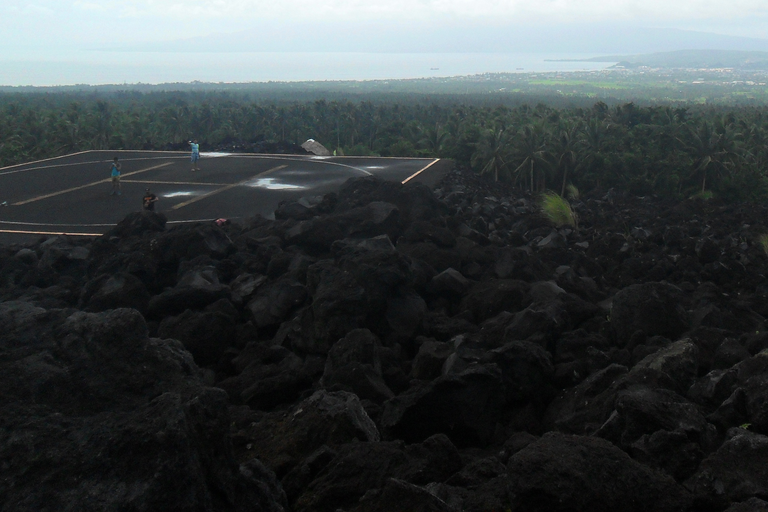

In [5]:
run_stage('prepare')
show_image('i2v_conditioning.png', 'the prepared 768 x 512 conditioning image')

**What to notice:** the settings dictionary (512 × 768, 49 frames, 50 steps, guidance 5.0, seed 42, 24 fps); the photograph's facts and its pinned digest; the crop box and `fraction_of_resized_area_kept`; and three `rejected` lines, each naming its rule.

<details>
<summary>Check your reasoning</summary>

The photograph is wider than 3:2, so scaling it to a height of 512 px makes it wider than 768 px, and the centre crop removes strips from the left and right. About 84 % of the resized area is kept. Anything at the edges of your own image is lost the same way, so keep the subject near the centre.

</details>

## 5. Encode the prompts once, then release the encoder · [Concept]

Both capabilities read a prompt the same way: Qwen2.5-VL-7B [5] turns it into a sequence of hidden states (up to 512 tokens) and the CLIP text tower [6] into one pooled vector (up to 77 tokens). The 7B encoder alone would need about 16.6 GB in float16 — more than the T4 has — so the `encode` stage loads it in **4-bit NF4** [8], encodes the text-to-video prompt, the image-to-video prompt and the negative prompt once, saves the embeddings to a safetensors file, and exits. The encoders never coexist with a transformer on the GPU.

**Predict before running:** after the encoders are released, how much GPU memory should still be allocated?

In [6]:
run_stage('encode')

Running stage 'encode' in the isolated environment; log: /content/outputs/kandinsky5_video/42f22852906e/logs/encode.log


Loading weights:   0%|          | 0/729 [00:00<?, ?it/s]


Loading weights:   0%|          | 1/729 [00:00<12:05,  1.00it/s]


Loading weights:   0%|          | 2/729 [00:05<37:32,  3.10s/it]


Loading weights:   1%|          | 4/729 [00:06<16:12,  1.34s/it]


...

{'t2v': {'qwen': [1, 29, 3584], 'clip': [1, 768], 'finite': True, 'clip_tokens': 31, 'clip_truncated': False}}


{'i2v': {'qwen': [1, 31, 3584], 'clip': [1, 768], 'finite': True, 'clip_tokens': 32, 'clip_truncated': False}}


{'negative': {'qwen': [1, 32, 3584], 'clip': [1, 768], 'finite': True, 'clip_tokens': 31, 'clip_truncated': False}}


{'encoder_load_seconds': 65.9, 'gpu_peak_gb': 6.72, 'gpu_allocated_after_release_gb': 0.01, 'seconds': 82.0, 'host_rss_peak_gb': 17.58}


{'stage': 'encode', 'status': 'ok', 'seconds': 82.0, 'host_rss_peak_gb': 17.58}


**What to notice:** an embedding shape for each prompt (Qwen: tokens × 3584; CLIP: 1 × 768) with `finite: True`; `clip_tokens` and `clip_truncated` (a prompt longer than 77 CLIP tokens loses its tail in the pooled vector, which is reported, not hidden); a GPU peak of roughly 7 GB; and close to 0 GB allocated after release. `host_rss_peak_gb` is the host-memory peak of this stage — the number the 24 GB gate in Section 1 protects.

<details>
<summary>Check your reasoning</summary>

Close to zero: the stage deletes both encoders, empties the CUDA cache and then exits, and the process exit returns everything to the driver. That is why the 2B transformers in Sections 6 and 7 can use most of the 15 GB.

</details>

## 6. Capability A — text-to-video · [Concept]

The `t2v` stage loads the sft transformer [2] and the HunyuanVideo VAE [4] in **float16**, turns VAE tiling on, and generates 49 frames at 512 × 768 from the cached embeddings: 50 flow-matching steps [11], each running the transformer twice for classifier-free guidance at 5.0 [12], with seed 42. A callback records, at every step, the fraction of the latent that is still finite — the signal that exposed the float16 overflow of the distilled checkpoint (see **What did not work**). The stage refuses to write a clip whose frames are non-finite or blank.

**Input contract:** one prompt. **Output contract:** `outputs/kandinsky5_video_t2v.mp4` (H.264, 24 fps), a three-frame strip (first, middle, last), and `outputs/t2v.json` with the settings, timings, GPU peak and frame checks.

**Predict before running:** 50 steps with guidance means 100 transformer passes. If one pass over a 49-frame latent takes about 13–14 s on a T4, roughly how long will the generation take?

Running stage 't2v' in the isolated environment; log: /content/outputs/kandinsky5_video/42f22852906e/logs/t2v.log


  0%|          | 0/50 [00:00<?, ?it/s]/tmp/kandinsky5_video_env_42f22852906e/venv/lib/python3.12/site-packages/torch/nn/functional.py:2954: UserWarning: Mismatch dtype between input and weight: input dtype = float, weight dtype = c10::Half, Cannot dispatch to fused implementation. (Triggered internally at /pytorch/aten/src/ATen/native/layer_norm.cpp:344.)


  return torch.rms_norm(input, normalized_shape, weight, eps)


  2%|▏         | 1/50 [00:22<18:32, 22.70s/it]


  4%|▍         | 2/50 [00:45<18:19, 22.92s/it]


...

{'capability': 't2v', 'precision': 'float16 (transformer and VAE)', 'load_seconds': 22.4, 'generate_seconds': 1285.1, 'gpu_peak_gb': 10.19, 'first_nonfinite_step': None, 'steps_completed': 50}


{'frame_checks': {'shape_as_requested': True, 'all_values_finite': True, 'no_blank_frames': True, 'clip_has_motion': True, 'no_abrupt_cuts': True}, 'consecutive_change': {'mean': 0.01813, 'min': 0.01513, 'max': 0.01993}, 'blank_frames': 0, 'frozen_pairs': 0}


{'video': {'file': 'kandinsky5_video_t2v.mp4', 'bytes': 223203, 'sha256': 'ec8385df56adb02f91dd932e3bd1efed1f27008353a1bf3a1f5b4a026c11a49a'}, 'strip': 'kandinsky5_video_t2v_strip.jpg'}


{'stage': 't2v', 'status': 'ok', 'seconds': 1319.3, 'host_rss_peak_gb': 9.43}


text-to-video: first, middle and last frame -> /content/outputs/kandinsky5_video/42f22852906e/outputs/kandinsky5_video_t2v_strip.jpg


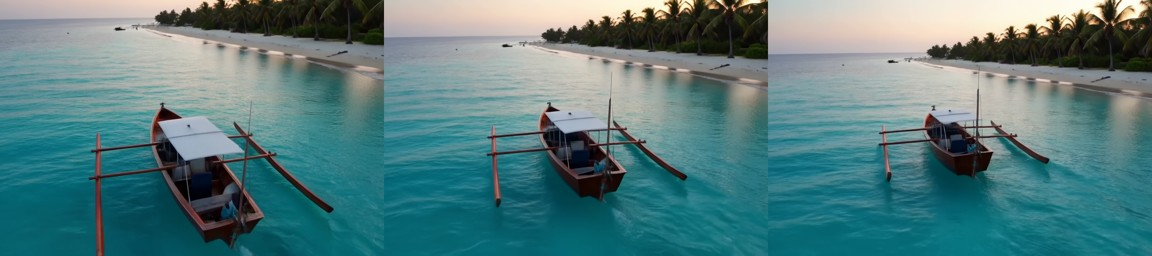

In [7]:
run_stage('t2v')
show_image('kandinsky5_video_t2v_strip.jpg', 'text-to-video: first, middle and last frame')

**What to notice:** `generate_seconds` (in the development probe, 1352 s on a Kaggle T4); `first_nonfinite_step: None`; a GPU peak near 10 GB; every frame check `True`; and a strip whose three frames show the same scene with visible change between them. Run `show_video('kandinsky5_video_t2v.mp4')` in a new cell to play the clip.

<details>
<summary>Check your reasoning</summary>

About 100 × 13.5 s ≈ 22–23 minutes, plus a few seconds of VAE decoding. Guidance doubles the work of every step; that is the main cost of a 50-step CFG sampler compared with a distilled 16-step one.

</details>

## 7. Capability B — image-to-video · [Concept]

The `i2v` stage loads the image-to-video transformer [3] from its own snapshot and the same VAE, encodes the prepared photograph into the latent space as the first frame's condition, and generates 49 frames with the same sampler, guidance, seed and negative prompt. The prompt now describes *motion* in a scene the photograph already fixes. The text-to-video transformer was released when Section 6's process exited, so only one transformer is ever in memory.

**Input contract:** one prompt and one prepared 768 × 512 image. **Output contract:** `outputs/kandinsky5_video_i2v.mp4`, a strip and `outputs/i2v.json`, as in Section 6.

**Predict before running:** which will change more from the first frame to the last — this clip or the text-to-video clip? Why?

Running stage 'i2v' in the isolated environment; log: /content/outputs/kandinsky5_video/42f22852906e/logs/i2v.log


  0%|          | 0/50 [00:00<?, ?it/s]/tmp/kandinsky5_video_env_42f22852906e/venv/lib/python3.12/site-packages/torch/nn/functional.py:2954: UserWarning: Mismatch dtype between input and weight: input dtype = float, weight dtype = c10::Half, Cannot dispatch to fused implementation. (Triggered internally at /pytorch/aten/src/ATen/native/layer_norm.cpp:344.)


  return torch.rms_norm(input, normalized_shape, weight, eps)


  2%|▏         | 1/50 [00:24<19:52, 24.33s/it]


  4%|▍         | 2/50 [00:49<19:52, 24.85s/it]


...

{'capability': 'i2v', 'precision': 'float16 (transformer and VAE)', 'load_seconds': 19.1, 'generate_seconds': 1285.5, 'gpu_peak_gb': 10.2, 'first_nonfinite_step': None, 'steps_completed': 50}


{'frame_checks': {'shape_as_requested': True, 'all_values_finite': True, 'no_blank_frames': True, 'clip_has_motion': True, 'no_abrupt_cuts': True}, 'consecutive_change': {'mean': 0.01146, 'min': 0.00716, 'max': 0.01645}, 'blank_frames': 0, 'frozen_pairs': 0}


{'video': {'file': 'kandinsky5_video_i2v.mp4', 'bytes': 145070, 'sha256': '75a45a16d01b72fd934f059d0ad95e88e311054de1f81ad730526397c538998f'}, 'strip': 'kandinsky5_video_i2v_strip.jpg'}


{'stage': 'i2v', 'status': 'ok', 'seconds': 1315.4, 'host_rss_peak_gb': 9.42}


image-to-video: first, middle and last frame -> /content/outputs/kandinsky5_video/42f22852906e/outputs/kandinsky5_video_i2v_strip.jpg


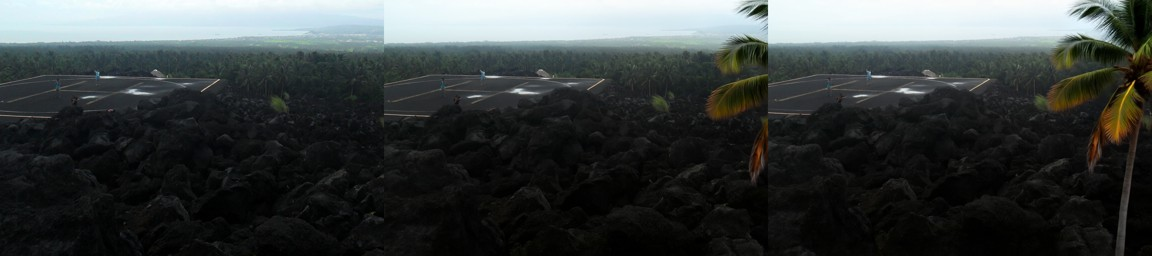

In [8]:
run_stage('i2v')
show_image('kandinsky5_video_i2v_strip.jpg', 'image-to-video: first, middle and last frame')

**What to notice:** a first frame that looks like the prepared photograph; the frame checks; and `consecutive_change`, the mean absolute change between neighbouring frames, to compare with Section 6's. In the development probe the image-to-video generation took 1378 s on a Kaggle T4.

<details>
<summary>Check your reasoning</summary>

Usually the text-to-video clip: nothing anchors its first frame, and its prompt describes a moving boat and a tracking camera. The image-to-video clip is anchored to the photograph and its prompt asks for slow cloud and palm motion. Section 8 measures this with `consecutive_change`; one pair of clips cannot show it is a general rule.

</details>

## 8. Evaluate both clips · [Evaluation practice]

Generated video has no reference answer here, so the `evaluate` stage reads three kinds of evidence, each with a stated threshold or baseline:

1. **Decoded-frame checks** (computed in Sections 6–7): every value finite; no blank frame (per-frame pixel standard deviation below 0.01 on a 0–1 scale); the clip moves (mean change between neighbouring frames at least 0.002); and no abrupt cut (no neighbouring pair changing by more than 0.25). These catch the failure modes seen in development — blank or frozen output — and say nothing about whether the video is good.
2. **First-frame fidelity** (image-to-video only): mean absolute difference and PSNR between the first generated frame and the prepared photograph, plus their CLIP image similarity. A high PSNR says the model kept the photograph; it does not say the motion is plausible.
3. **Prompt alignment with a swapped-prompt baseline:** CLIP ViT-L/14 [6] — the image and text towers stored in the same `text_encoder_2` file the pipeline already verified, so nothing more is downloaded — embeds every frame and both prompts. For each clip the stage reports the mean similarity to its own prompt, to the other capability's prompt, and the margin between them. The baseline is meaningful because the two prompts describe different scenes.

**Why not a standard video metric?** Fréchet Video Distance needs hundreds of reference clips, and VBench-style suites need many more generations than two clips that each take over 20 minutes on a T4. The notebook therefore reports sanity checks and a proxy. **Every threshold and score in this section is uncalibrated tutorial evidence:** the frame-check thresholds were chosen to catch the blank and frozen outputs seen in development, not fitted to human judgements; CLIP similarities and margins are not probabilities; and the only baseline is the swapped prompt.

**Predict before running:** will each clip be closer to its own prompt than to the other one? Which margin do you expect to be larger, and why?

In [9]:
run_stage('evaluate')
evaluation = load_record('evaluation.json')
for capability in evaluation['capabilities']:
    alignment = evaluation['prompt_alignment'][capability]
    print(capability, {'frame_checks_passed': evaluation['frame_checks'][capability]['passed'], 'own_prompt': alignment['own_prompt_similarity'], 'swapped_prompt': alignment['swapped_prompt_similarity'], 'margin': alignment['margin'], 'frames_closer_to_own_prompt': alignment['frames_closer_to_own_prompt']})

Running stage 'evaluate' in the isolated environment; log: /content/outputs/kandinsky5_video/42f22852906e/logs/evaluate.log


Loading weights:   0%|          | 0/590 [00:00<?, ?it/s]


Loading weights:   1%|          | 3/590 [00:00<02:09,  4.54it/s]


Loading weights:  15%|█▌        | 89/590 [00:00<00:03, 141.79it/s]


Loading weights:  21%|██        | 121/590 [00:01<00:03, 151.80it/s]


...

{'t2v': {'frame_checks_passed': True, 'own_prompt_similarity': 0.2855, 'swapped_prompt_similarity': 0.1402, 'margin': 0.1453, 'frames_closer_to_own_prompt': 1.0, 'frames_scored': 49}}


{'i2v': {'frame_checks_passed': True, 'own_prompt_similarity': 0.294, 'swapped_prompt_similarity': 0.0998, 'margin': 0.1942, 'frames_closer_to_own_prompt': 1.0, 'frames_scored': 49}}


{'i2v_first_frame_fidelity': {'mean_abs_diff': 0.01918, 'psnr_db': np.float64(33.28)}, 'i2v_clip_similarity_to_conditioning_image': {'first_frame': 0.9961, 'last_frame': 0.9065, 'mean': 0.9542}}


{'stage': 'evaluate', 'status': 'ok', 'seconds': 14.9, 'host_rss_peak_gb': 3.4}


t2v {'frame_checks_passed': True, 'own_prompt': 0.2855, 'swapped_prompt': 0.1402, 'margin': 0.1453, 'frames_closer_to_own_prompt': 1.0}
i2v {'frame_checks_passed': True, 'own_prompt': 0.294, 'swapped_prompt': 0.0998, 'margin': 0.1942, 'frames_closer_to_own_prompt': 1.0}


**What to notice** (all uncalibrated tutorial evidence)**:** both `frame_checks_passed` values; for each clip, the own-prompt and swapped-prompt similarities (CLIP cosine similarities for natural images and short captions typically sit between about 0.15 and 0.35) and a margin whose sign is the result; `frames_closer_to_own_prompt` near 1.0 when the margin is consistent across the clip; and the image-to-video first-frame PSNR. **Cross-capability interpretation:** the two capabilities share every component except the transformer, so a difference in their margins reflects the prompts, the conditioning image and the transformers together — one clip each cannot separate those causes.

<details>
<summary>Check your reasoning</summary>

Expect positive margins: the boat prompt and the lava-field prompt describe different scenes. The image-to-video margin is often the larger one, because its frames stay close to a photograph whose content (dark rocks, palms, a coastline) overlaps its own prompt and not the boat prompt. A negative margin would be a real result to report, not a reason to re-run until it changes. Either way, a margin is CLIP's opinion of one clip, not a measure of quality.

</details>

## 9. Export and provenance · [Engineering]

The `report` stage writes `outputs/kandinsky5_video_provenance.json`, the record that makes a clip traceable: the notebook source revision; both model ids and revisions and the SHA-256 of each manifest; the component licences; the quantization and precision; the prompts and the image source with its digest and crop; the settings and seed; the runtime versions and GPU; the timings and memory peaks; each mp4's size and SHA-256; and the evaluation summary. It contains no credential. It then lists every file under `outputs/`.

In [10]:
run_stage('report')

Running stage 'report' in the isolated environment; log: /content/outputs/kandinsky5_video/42f22852906e/logs/report.log


{'provenance': 'outputs/kandinsky5_video_provenance.json', 'journey': 'default', 'videos': {'t2v': 'kandinsky5_video_t2v.mp4', 'i2v': 'kandinsky5_video_i2v.mp4'}}


outputs/:


  - outputs/encode.json (0.8 KB)


  - outputs/evaluation.json (8.9 KB)


...

  - outputs/kandinsky5_video_t2v_strip.jpg (64.9 KB)


  - outputs/prepare.json (2.0 KB)


  - outputs/t2v.json (1.4 KB)


  - outputs/weights.json (2.1 KB)


{'stage': 'report', 'status': 'ok', 'seconds': 5.0, 'host_rss_peak_gb': 0.74}


**What to notice:** two mp4 files of a few MB each, two strips, the conditioning image, one JSON record per stage and the provenance record. The clips are generated, not reloaded artifacts: there is no trained artifact to reload in this notebook, so no fresh-reload check applies.

## 10. Optional activity: change one thing — the seed · [Concept]

**Predict → Change one thing → Run → Observe → Explain.** The seed fixes the starting noise. Keep the prompt, steps and guidance, change only the seed from 42 to 7, and regenerate the text-to-video clip.

1. **Predict:** will the new clip show the same boat and beach with small differences, or a different composition?
2. **Change one thing:** set `RUN_ACTIVITY = True` (about 23 more minutes on a T4).
3. **Run** the cell. 4. **Observe** the strip and `mean_abs_pixel_difference_between_seeds`. 5. **Explain** what the seed controls and what it means for a claim made from one clip.

The activity is off by default and never part of the default path.

In [11]:
RUN_ACTIVITY = False  # @param {type:"boolean"}
if RUN_ACTIVITY:
    run_stage('activity')
    show_image('kandinsky5_video_t2v_seed7_strip.jpg', 'text-to-video, seed 7')
else:
    print('Activity skipped (RUN_ACTIVITY is False).')

Activity skipped (RUN_ACTIVITY is False).


<details>
<summary>Check your reasoning</summary>

A different seed usually gives a different composition — boat position, framing, light — that still follows the prompt, and the mean pixel difference between the two clips is large compared with the frame-to-frame change inside either clip. A single clip is one sample from the model's distribution for that prompt, so any conclusion from it is a statement about one sample.

</details>

## 11. Bring Your Own Data (optional) · [Evaluation practice]

Run your own prompts and image through the same validation, encoding, generation, checks and export. **Contract:** prompts of 3..1000 characters; an image file that is JPEG, PNG or WEBP, at most 25 MiB, shorter side at least 256 px, longer side at most 8192 px, width/height between 0.5 and 2.5. The image is resized to cover 768 × 512 and centre-cropped, and the crop is reported. An input that breaks the contract stops in the `prepare` stage with a message naming the rule, before any model loads.

**Where your data goes.** Your prompts and image stay inside this runtime: nothing is sent to any service, and the outputs are written under `outputs/` with a `byod_` prefix. Do not use confidential, personal or regulated images unless you are authorized to process them in this environment, and do not generate depictions of real people.

**How.** On Kaggle, add your image as a dataset and set `BYOD_IMAGE_PATH` to its path under `/kaggle/input/` (there is no upload dialog). Leave a prompt empty to reuse the default one. `BYOD_CAPABILITIES` chooses `i2v`, `t2v` or `both`; each capability takes more than 20 minutes.

In [12]:
USE_BYOD = False  # @param {type:"boolean"}
BYOD_IMAGE_PATH = ''  # @param {type:"string"}
BYOD_T2V_PROMPT = ''  # @param {type:"string"}
BYOD_I2V_PROMPT = ''  # @param {type:"string"}
BYOD_CAPABILITIES = 'i2v'  # @param ["i2v", "t2v", "both"]
if USE_BYOD:
    capabilities = ['t2v', 'i2v'] if BYOD_CAPABILITIES == 'both' else [BYOD_CAPABILITIES]
    if 'i2v' in capabilities and not BYOD_IMAGE_PATH:
        raise ValueError('Set BYOD_IMAGE_PATH to an image file inside this runtime (for example under /kaggle/input/) for image-to-video.')
    options = ['--tag', 'byod', '--capabilities', ','.join(capabilities)]
    prepare = list(options)
    if BYOD_IMAGE_PATH:
        prepare += ['--image', BYOD_IMAGE_PATH]
    if BYOD_T2V_PROMPT:
        prepare += ['--t2v-prompt', BYOD_T2V_PROMPT]
    if BYOD_I2V_PROMPT:
        prepare += ['--i2v-prompt', BYOD_I2V_PROMPT]
    run_stage('prepare', *prepare)
    run_stage('encode', *options)
    for capability in capabilities:
        run_stage(capability, *options)
        show_image(f'byod_kandinsky5_video_{capability}_strip.jpg', f'BYOD {capability}')
    run_stage('evaluate', *options)
    run_stage('report', *options)
else:
    print('BYOD skipped (USE_BYOD is False).')

BYOD skipped (USE_BYOD is False).


## Interpretation and limits

Successful execution proves that the recorded repository revision, run in the documented Kaggle T4 environment, staged two digest-verified snapshots without the repository being cloned, encoded three prompts with a 4-bit encoder, generated one text-to-video and one image-to-video clip in float16, and wrote decoded-frame checks, a CLIP alignment proxy and a provenance record. It does **not** establish benchmark superiority, video quality, prompt faithfulness beyond CLIP's coarse opinion, safety of the generated content, or behaviour on other prompts, images, resolutions, lengths or GPUs. Results are tutorial evidence from one clip per capability.

**Sources of variability.** Non-deterministic GPU kernels, the 4-bit quantization of the encoder, float16 rounding and the library builds can change pixels for the same seed; the seed activity in Section 10 shows how much the starting noise alone changes a clip. **Reproducibility is limited to what the notebook controls:** pinned revisions, digests, the lock, the seed and the settings.

**Conclusion template.** Write your own conclusion in four sentences, each tied to a printed number: (1) the task and the two capabilities; (2) the principal result — did both clips pass the frame checks, and what were the two alignment margins against the swapped-prompt baseline? (3) the most important failure mode or uncertainty you observed (a distorted watermark, a frozen stretch, a near-zero margin, seed sensitivity); (4) what one clip per capability cannot show.

**Transfer.** Apply the same checks to another use: a short clip from a photograph of a flood-prone river in your province, for example, through the BYOD branch. Before running, write down which check you expect to be weakest and why.

## What did not work

Each entry below comes from the **development probe** that sized this notebook (an engineering-only SMOKE notebook run on a Kaggle T4 on 2026-10-11 and 2026-10-12, Python 3.13 with an in-kernel install of torch 2.11.0+cu128, transformers 5.16.1, diffusers 0.40.0 and bitsandbytes 0.50.2). It is development-run evidence, not evidence from this notebook's own run.

1. **The distilled 16-step text-to-video checkpoint in float16 produced blank frames.** Tried: `kandinskylab/Kandinsky-5.0-T2V-Lite-distilled16steps-5s-Diffusers` at revision `06d0f76a`, 16 steps, guidance 1.0, float16. Observed: every decoded frame had a pixel standard deviation of 0.0. A per-step check showed the latent finite through step 11 and 48.5 % non-finite at step 12 (timestep ≈ 562): an activation overflow inside the transformer, beyond float16's range. Rejected because the T4 has no fast alternative precision (entry 2); the sft checkpoint, which needs 50 guided steps instead of 16 unguided ones, stayed finite at every step and is used here. The lesson: a faster checkpoint is not automatically usable at a lower precision, and a per-step finiteness check finds where it breaks.
2. **bfloat16 on the T4 ran out of memory.** Tried: the same transformer in bfloat16. Observed: CUDA out of memory while requesting 41.59 GiB on a 14.56 GiB GPU. Inferred, not traced: attention fell back to a full-matrix path for this data type on this GPU. Rejected; float16 is used for every transformer and the VAE.
3. **Free Colab cannot hold the 4-bit encoder load.** Observed: host memory peaked at 18.6–21.9 GB while the Qwen2.5-VL encoder was loaded and quantized; free Colab sessions have about 12.7 GB. Rejected; the notebook targets Kaggle (about 33.7 GB of host RAM) and refuses sessions with less than 24 GB available.

Evidence: the development-probe logs committed byte for byte in this repository under `docs/development-probe/` (Kaggle kernel `kurtvalcorza/kandinsky5-lite-t4-smoke`: version 1 for the blank frames in entry 1, for entry 2 and for the 21.94 GB host-memory peak; version 2 for the per-step check in entry 1 and the 18.55 GB peak).

## Troubleshooting

- **Section 1 says the GPU is missing or too small.** Open *Settings → Accelerator* and choose *GPU T4 x2*, then *Run all* again. P100 and CPU sessions are not supported.
- **Section 1 says host RAM is too low.** Start a fresh Kaggle session; other notebooks in the same session share memory. Free Colab cannot run this notebook.
- **A download fails or stalls (Section 2 or 3).** Turn *Internet* on in the notebook settings and re-run the failed cell; staging fetches only files that are still missing. A `SHA-256 mismatch` names the file: delete it from the weights directory printed in Section 1 and re-run Section 3. Never edit a manifest or a lock hash.
- **Not enough disk.** The weights need about 28.4 GB on the temporary disk; start a fresh session.
- **`CUDA out of memory` in Sections 5–7.** Make sure no other process uses the GPU (restart the session and *Run all*). Do not raise the resolution or frame count above the measured envelope: the validators refuse it on purpose.
- **A stage reports non-finite or blank frames.** That is the float16 overflow failure mode; check that the pinned sft revision was staged (Section 3) and that the settings are the defaults.
- **The sample photograph fails its digest.** The Wikimedia file has changed upstream; the notebook will not substitute another image. Use BYOD with your own image.
- **BYOD refuses your image.** The message names the rule (format, size, side length or aspect ratio); fix the file and re-run Section 11. The Kaggle path must point to a file, not a directory.

## References

[1] V. Arkhipkin et al., "Kandinsky 5.0: A family of foundation models for image and video generation," arXiv:2511.14993, 2025. [Online]. Available: https://arxiv.org/abs/2511.14993

[2] Kandinsky Lab, "Kandinsky-5.0-T2V-Lite-sft-5s-Diffusers," Hugging Face model repository, revision 5c74c11b3ecfb96249b588d17aebd59f3fd9a080, 2025. [Online]. Available: https://huggingface.co/kandinskylab/Kandinsky-5.0-T2V-Lite-sft-5s-Diffusers/tree/5c74c11b3ecfb96249b588d17aebd59f3fd9a080

[3] Kandinsky Lab, "Kandinsky-5.0-I2V-Lite-5s-Diffusers," Hugging Face model repository, revision 8d965626ab76734922b00e359ca2d8faab2e0417, 2025. [Online]. Available: https://huggingface.co/kandinskylab/Kandinsky-5.0-I2V-Lite-5s-Diffusers/tree/8d965626ab76734922b00e359ca2d8faab2e0417

[4] W. Kong et al., "HunyuanVideo: A systematic framework for large video generative models," arXiv:2412.03603, 2024. [Online]. Available: https://arxiv.org/abs/2412.03603

[5] S. Bai et al., "Qwen2.5-VL technical report," arXiv:2502.13923, 2025. [Online]. Available: https://arxiv.org/abs/2502.13923

[6] A. Radford et al., "Learning transferable visual models from natural language supervision," in Proc. 38th Int. Conf. Mach. Learn. (ICML), 2021, pp. 8748–8763. [Online]. Available: https://arxiv.org/abs/2103.00020

[7] P. von Platen et al., "Diffusers: State-of-the-art diffusion models," GitHub repository, version 0.40.0. [Online]. Available: https://github.com/huggingface/diffusers/tree/v0.40.0

[8] T. Dettmers, A. Pagnoni, A. Holtzman, and L. Zettlemoyer, "QLoRA: Efficient finetuning of quantized LLMs," in Adv. Neural Inf. Process. Syst. (NeurIPS), vol. 36, 2023. [Online]. Available: https://arxiv.org/abs/2305.14314

[9] P. A. V. Mahusay, "Mayon Volcano, Albay (Toe ).jpg," Wikimedia Commons, photograph taken 2016-08-18, CC0 1.0. [Online]. Available: https://commons.wikimedia.org/wiki/File:Mayon_Volcano,_Albay_(Toe_).jpg

[10] Tencent, "Tencent Hunyuan Community License Agreement," tencent/HunyuanVideo, revision 6204ad6aea1a77ff5aba337c88278bb9500eb37d. [Online]. Available: https://huggingface.co/tencent/HunyuanVideo/blob/6204ad6aea1a77ff5aba337c88278bb9500eb37d/LICENSE

[11] Y. Lipman, R. T. Q. Chen, H. Ben-Hamu, M. Nickel, and M. Le, "Flow matching for generative modeling," in Proc. Int. Conf. Learn. Represent. (ICLR), 2023. [Online]. Available: https://arxiv.org/abs/2210.02747

[12] J. Ho and T. Salimans, "Classifier-free diffusion guidance," arXiv:2207.12598, 2022. [Online]. Available: https://arxiv.org/abs/2207.12598

Repository model card (licences, intended use and limitations): https://github.com/kurtvalcorza/kandinsky5-video-generation-pipeline/blob/main/MODEL_CARD.md